# GridMind: An AI trader for a GB grid battery



Loading the libraries and sets the battery we simulate: 50 MW power, 100 MWh storage, 88% round-trip efficiency, GBP 5/MWh wear cost. These match a typical new British 2-hour grid battery.

In [ ]:
# Libraries
import sys, subprocess
try:
    import lightgbm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm

import os, time, warnings
from datetime import date, datetime, timedelta, timezone
import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt
from scipy.optimize import linprog, milp, LinearConstraint, Bounds
from scipy import sparse
import joblib
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

# Data range: one year is ideal; start with 60 days to test quickly
START = date(2025, 10, 1)
END   = date.today() - timedelta(days=2)

# Battery: a typical new GB 2-hour site
P_MAX_MW   = 50.0                 # power
E_MAX_MWH  = 100.0                # energy capacity
SOC_MIN, SOC_MAX = 5.0, 95.0      # MWh limits (protects the battery)
RTE        = 0.88                 # round-trip efficiency
ETA        = RTE ** 0.5           # one-way efficiency (charge and discharge)
DEG_COST   = 5.0                  # GBP per MWh discharged (wear), stated assumption
DT         = 0.5                  # hours per settlement period
E_STEP     = P_MAX_MW * DT        # max grid-side MWh per half-hour (25)
SOC_START  = 50.0

DATA_FILE = "gb_power_data.csv"
TUNE_MODELS = True    # small hyperparameter search on validation months ; False = defaults
print("Data range:", START, "to", END)

Data range: 2025-10-01 to 2026-10-23


**What this does:** Reads optional keys from Colab Secrets (🔑 icon on the left): `TIGER_DB_URL` (Tiger Data connection string) and `GEMINI_API_KEY` (Google AI Studio). Without them everything still runs.

In [ ]:
# 1b. Sponsor keys
def _secret(name):
    v = os.environ.get(name)
    if v:
        return v
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None

TIGER_DB_URL = _secret("TIGER_DB_URL")
GEMINI_API_KEY = _secret("GEMINI_API_KEY")
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
print(f"Tiger Data: {'ON' if TIGER_DB_URL else 'off'} | Gemini: {'ON' if GEMINI_API_KEY else 'off'}")

Tiger Data: off | Gemini: off


 Functions that download five public datasets from Elexon's free API: imbalance prices (what we predict), generation by fuel type, the wholesale market price, and every published wind and demand forecast. One request per day or week, retried if it fails.

In [ ]:
# Data fetchers (Elexon Insights API, public, no key)
BASE = "https://data.elexon.co.uk/bmrs/api/v1"
S = requests.Session()

def get(url, params=None, retries=3):
    err = None
    for _ in range(retries):
        try:
            r = S.get(url, params=params, timeout=90)
            if r.status_code == 429:
                time.sleep(5); continue
            r.raise_for_status()
            js = r.json()
            return js["data"] if isinstance(js, dict) and "data" in js else js
        except Exception as e:
            err = e; time.sleep(2)
    print(f"   ! request failed: {url} {params or ''} -> {err}")
    return []

def chunks(start, end, days=7):
    d = start
    while d <= end:
        e = min(d + timedelta(days=days - 1), end)
        yield d, e
        d = e + timedelta(days=1)

def iso(d):  # date -> ISO midnight UTC
    return f"{d.isoformat()}T00:00:00Z"

def fetch_prices(start, end):
    # Imbalance (system) price per half-hour -> our TARGET
    rows = []
    d = start
    while d <= end:
        rows += get(f"{BASE}/balancing/settlement/system-prices/{d.isoformat()}")
        print(f"   prices {d}", end="\r"); d += timedelta(days=1)
    print()
    df = pd.DataFrame(rows)
    if df.empty: return df
    df = df[["startTime", "systemSellPrice", "netImbalanceVolume"]].rename(
        columns={"systemSellPrice": "price", "netImbalanceVolume": "niv"})
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    return df.drop_duplicates("startTime", keep="last")

def fetch_fuel(start, end):
    # Generation by fuel type every 5 min -> half-hourly averages
    rows = []
    for a, b in chunks(start, end):
        rows += get(f"{BASE}/datasets/FUELINST/stream",
                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})
        print(f"   fuel mix to {b}", end="\r")
    print()
    df = pd.DataFrame(rows)
    if df.empty: return df
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True).dt.floor("30min")
    return (df.pivot_table(index="startTime", columns="fuelType", values="generation", aggfunc="mean")
              .add_prefix("gen_").reset_index())

def fetch_mid(start, end):
    # Market Index Data: wholesale price per half-hour (volume-weighted across providers)
    rows = []
    for a, b in chunks(start, end):
        rows += get(f"{BASE}/datasets/MID", {"from": iso(a), "to": iso(b + timedelta(days=1))})
    df = pd.DataFrame(rows)
    if df.empty: return df
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    df["pv"] = df["price"] * df["volume"]
    g = df.groupby("startTime")[["pv", "volume", "price"]].agg({"pv": "sum", "volume": "sum", "price": "mean"})
    g["market_price"] = np.where(g["volume"] > 0, g["pv"] / g["volume"].replace(0, np.nan), g["price"])
    return g[["market_price"]].reset_index()

def fetch_forecast(dataset, start, end, value_col):
    # Every published forecast (with publishTime) so we can use only what was known at the time
    rows = []
    for a, b in chunks(start - timedelta(days=2), end):
        rows += get(f"{BASE}/datasets/{dataset}/stream",
                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})
        print(f"   {dataset} to {b}", end="\r")
    print()
    df = pd.DataFrame(rows)
    if df.empty or value_col not in df.columns: return pd.DataFrame()
    df = df[["publishTime", "startTime", value_col]].rename(columns={value_col: "value"})
    df["publishTime"] = pd.to_datetime(df["publishTime"], utc=True)
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    return df.dropna()

def fetch_all(start, end):
    print("Fetching imbalance prices..."); prices = fetch_prices(start, end)
    print("Fetching fuel mix...");         fuel   = fetch_fuel(start, end)
    print("Fetching market index...");     mid    = fetch_mid(start, end)
    print("Fetching wind forecasts...");   windf  = fetch_forecast("WINDFOR", start, end, "generation")
    print("Fetching demand forecasts..."); demf   = fetch_forecast("NDF", start, end, "demand")
    for name, d in [("prices", prices), ("fuel", fuel), ("mid", mid), ("wind fc", windf), ("demand fc", demf)]:
        print(f"   {name:10s}: {len(d):>8,} rows" + ("   <-- EMPTY (feature will be skipped)" if d.empty else ""))
    return prices, fuel, mid, windf, demf

Puts everything on one timeline, one row per half-hour. For forecasts, `asat` picks only the latest forecast that was **already published** at least 1 hour or 24 hours for day-ahead before that half-hour, so the model never sees anything from the future.

In [ ]:
#Combine into one half-hourly table (as-at forecasts, no look-ahead)
FC_LEAD = pd.Timedelta("60min")
DA_LEAD = pd.Timedelta("24h")     #

def asat(fc, times, lead=FC_LEAD, hourly=False):
    # For each target time, the latest forecast for that time published at least `lead` earlier
    if fc.empty: return pd.Series(np.nan, index=times)
    t = pd.DataFrame({"startTime": times})
    t["key"] = t["startTime"].dt.floor("60min") if hourly else t["startTime"]
    t["cutoff"] = t["startTime"] - lead
    f = fc.rename(columns={"startTime": "key"}).sort_values("publishTime")
    out = pd.merge_asof(t.sort_values("cutoff"), f, left_on="cutoff", right_on="publishTime",
                        by="key", direction="backward")
    return out.set_index("startTime")["value"].reindex(times)

def combine(prices, fuel, mid, windf, demf, extend_periods=0):
    t0 = prices["startTime"].min()
    t1 = prices["startTime"].max() + pd.Timedelta(minutes=30) * extend_periods
    grid = pd.DataFrame({"startTime": pd.date_range(t0, t1, freq="30min", tz="UTC")})
    df = grid.merge(prices, on="startTime", how="left")
    for extra in (fuel, mid):
        if len(extra): df = df.merge(extra, on="startTime", how="left")
    hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()
    df["wind_fc"]   = asat(windf, df["startTime"], hourly=hourly).values
    df["demand_fc"] = asat(demf, df["startTime"]).values
    df["wind_fc_da"]   = asat(windf, df["startTime"], lead=DA_LEAD, hourly=hourly).values
    df["demand_fc_da"] = asat(demf, df["startTime"], lead=DA_LEAD).values
    return df

 Downloads the data the first time and saves it to `gb_power_data.csv`; later runs just load the file in seconds.

In [ ]:
# 3b. Download (or load cached) data
if os.path.exists(DATA_FILE):
    raw = pd.read_csv(DATA_FILE, parse_dates=["startTime"])
    print("Loaded cached", DATA_FILE, raw.shape)
    if "wind_fc_da" not in raw.columns:      # file from an older run: add the day-ahead forecasts once
        print("Adding day-ahead wind and demand forecasts to the cached data...")
        t_ = pd.to_datetime(raw["startTime"], utc=True)
        s_, e_ = t_.min().date(), t_.max().date()
        windf = fetch_forecast("WINDFOR", s_, e_, "generation"); demf = fetch_forecast("NDF", s_, e_, "demand")
        hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()
        raw["wind_fc_da"]   = asat(windf, t_, lead=DA_LEAD, hourly=hourly).values
        raw["demand_fc_da"] = asat(demf, t_, lead=DA_LEAD).values
        raw.to_csv(DATA_FILE, index=False)
        print("Upgraded", DATA_FILE, raw.shape)
else:
    prices, fuel, mid, windf, demf = fetch_all(START, END)
    if prices.empty:
        raise SystemExit("No price data came back. Check the internet connection, then open the failing "
                         "URL printed above in a browser to see Elexon's error message.")
    raw = combine(prices, fuel, mid, windf, demf)
    raw.to_csv(DATA_FILE, index=False)
    print("Saved", DATA_FILE, raw.shape)
print(f"Day-ahead forecasts available for {raw['wind_fc_da'].notna().mean():.0%} (wind) and "
      f"{raw['demand_fc_da'].notna().mean():.0%} (demand) of half-hours")
raw.tail()

Loaded cached gb_power_data.csv (18624, 28)
Day-ahead forecasts available for 100% (wind) and 83% (demand) of half-hours


,startTime,price,niv,gen_BIOMASS,gen_CCGT,gen_COAL,gen_INTELEC,gen_INTEW,gen_INTFR,gen_INTGRNL,...,gen_OCGT,gen_OIL,gen_OTHER,gen_PS,gen_WIND,market_price,wind_fc,demand_fc,wind_fc_da,demand_fc_da
18619,2026-10-23 20:30:00+00:00,26.009843,-192.493385,1125.500000,2989.833333,0.0,-0.833333,-531.000000,1439.333333,-513.833333,...,0.0,0.0,226.333333,-12.000000,13547.333333,73.61,14414,28494,14569,28360.0
18620,2026-10-23 21:00:00+00:00,34.720000,-328.081940,902.333333,2731.666667,0.0,-1.000000,-531.000000,1117.333333,-513.833333,...,0.0,0.0,328.666667,-12.000000,13991.000000,69.08,15578,27059,14436,26964.0
18621,2026-10-23 21:30:00+00:00,22.700000,-389.638891,899.833333,2625.000000,0.0,-10.166667,-531.000000,1054.000000,-514.000000,...,0.0,0.0,153.333333,-16.333333,14323.166667,55.95,15578,25857,14436,25849.0
18622,2026-10-23 22:00:00+00:00,12.634449,-223.792462,903.500000,2395.166667,0.0,-224.833333,-531.166667,-22.833333,-513.833333,...,0.0,0.0,1037.166667,-64.333333,14249.833333,50.19,16322,24192,14789,24189.0
18623,2026-10-23 22:30:00+00:00,46.040000,-311.510793,811.666667,2350.833333,0.0,-210.333333,-531.000000,-115.166667,-513.333333,...,0.0,0.0,756.166667,-8.500000,14127.666667,46.04,16322,23300,14789,23300.0


## Data quality and cleaning

Checks the raw data before using it: duplicates, missing half-hours, missing values, columns that never change, extreme prices and clock-change days.

In [ ]:
#  4. Data quality report
if "raw" not in globals():
    if os.path.exists(DATA_FILE):
        raw = pd.read_csv(DATA_FILE, parse_dates=["startTime"]); print("Loaded", DATA_FILE)
    else:
        _p, _f, _m, _w, _d = fetch_all(START, END)
        raw = combine(_p, _f, _m, _w, _d); raw.to_csv(DATA_FILE, index=False)
dq = raw.copy()
dq["startTime"] = pd.to_datetime(dq["startTime"], utc=True)
full = pd.date_range(dq.startTime.min(), dq.startTime.max(), freq="30min", tz="UTC")
print(f"Rows: {len(dq):,}   Range: {dq.startTime.min():%d %b %Y} -> {dq.startTime.max():%d %b %Y}")
print(f"Duplicate timestamps: {dq.startTime.duplicated().sum()}   "
      f"Missing half-hours in the timeline: {len(full.difference(dq.startTime))}")
miss = dq.isna().mean().mul(100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print("\nMissing values (% of rows):", "none" if miss.empty else "")
if not miss.empty: print(miss.to_string())
num = dq.select_dtypes("number")
const = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
print("\nConstant columns (carry no information):", const or "none")
p = dq["price"].dropna()
print(f"\nImbalance price: min GBP{p.min():,.0f} | median GBP{p.median():,.0f} | max GBP{p.max():,.0f}")
print(f"  negative: {(p < 0).mean():.1%} of half-hours | above GBP300: {(p > 300).mean():.1%} | "
      f"99th percentile: GBP{p.quantile(0.99):,.0f}")
per_day = dq.startTime.dt.tz_convert("Europe/London").dt.date.value_counts()
print(f"Clock-change days (46 or 50 half-hours): {int(per_day.isin([46, 50]).sum())} "
      "(handled by working in UTC)")

Rows: 18,624   Range: 30 Sep 2025 -> 23 Oct 2026
Duplicate timestamps: 0   Missing half-hours in the timeline: 0

Missing values (% of rows): 
demand_fc_da    16.67
gen_BIOMASS      0.01
gen_COAL         0.01
gen_INTELEC      0.01
gen_INTEW        0.01
gen_CCGT         0.01
gen_INTFR        0.01
gen_INTGRNL      0.01
gen_INTIRL       0.01
gen_INTIFA2      0.01
gen_INTNEM       0.01
gen_INTNSL       0.01
gen_INTVKL       0.01
gen_INTNED       0.01
gen_NPSHYD       0.01
gen_NUCLEAR      0.01
gen_OIL          0.01
gen_OCGT         0.01
gen_OTHER        0.01
gen_PS           0.01
gen_WIND         0.01
market_price     0.01

Constant columns (carry no information): ['gen_OIL']

Imbalance price: min GBP-98 | median GBP97 | max GBP800
  negative: 4.3% of half-hours | above GBP300: 0.2% | 99th percentile: GBP238
Clock-change days (46 or 50 half-hours): 2 (handled by working in UTC)


Fixes problems with simple, explainable rules: remove duplicates, drop useless columns, fix impossible values, and fill short gaps **only from earlier values** (filling from later values would leak the future). Prices are never invented and spikes are kept: they are real and they are where a battery makes money.

In [ ]:
#  5. Leak-free cleaning
FILL_LIMIT = 4

def clean_data(raw, verbose=True):
    df = raw.copy()
    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)
    n_dup = df.startTime.duplicated().sum()
    df = df.drop_duplicates("startTime", keep="last").sort_values("startTime")
    grid = pd.date_range(df.startTime.min(), df.startTime.max(), freq="30min", tz="UTC")
    n_gap = len(grid) - len(df)
    df = df.set_index("startTime").reindex(grid).rename_axis("startTime").reset_index()

    # 1. drop columns with no information (e.g. coal after 2024) or mostly missing
    num = df.select_dtypes("number").columns
    drop = [c for c in num if c not in ("price", "niv", "market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da")
            and (df[c].nunique(dropna=True) <= 1 or df[c].isna().mean() > 0.5)]
    df = df.drop(columns=drop)

    # 2. physically impossible values
    gen_cols = [c for c in df.columns if c.startswith("gen_")]
    clip_cols = [c for c in gen_cols if not c.startswith("gen_INT") and c != "gen_PS"]
    n_clip = int(sum((df[c] < 0).sum() for c in clip_cols))
    for c in clip_cols: df[c] = df[c].clip(lower=0)
    n_bad_fc = 0
    if "wind_fc" in df:   n_bad_fc += int((df.wind_fc < 0).sum());   df.loc[df.wind_fc < 0, "wind_fc"] = np.nan
    if "wind_fc_da" in df: n_bad_fc += int((df.wind_fc_da < 0).sum()); df.loc[df.wind_fc_da < 0, "wind_fc_da"] = np.nan
    if "demand_fc_da" in df: n_bad_fc += int((df.demand_fc_da <= 0).sum()); df.loc[df.demand_fc_da <= 0, "demand_fc_da"] = np.nan
    if "demand_fc" in df: n_bad_fc += int((df.demand_fc <= 0).sum()); df.loc[df.demand_fc <= 0, "demand_fc"] = np.nan

    # 3. fill short feature gaps from the PAST only (never the target)
    feat_cols = gen_cols + [c for c in ("market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da") if c in df]
    before = int(df[feat_cols].isna().sum().sum())
    df[feat_cols] = df[feat_cols].ffill(limit=FILL_LIMIT)
    n_fill = before - int(df[feat_cols].isna().sum().sum())

    if verbose:
        print(f"Removed {n_dup} duplicate rows; added {n_gap} empty rows for missing half-hours (kept as gaps)")
        print(f"Dropped uninformative columns: {drop or 'none'}")
        print(f"Clipped {n_clip} negative generation values to 0; removed {n_bad_fc} impossible forecasts")
        print(f"Forward-filled {n_fill:,} short feature gaps (<= {FILL_LIMIT * 30} min). Prices left untouched.")
        print(f"Half-hours with a usable price: {df.price.notna().sum():,} of {len(df):,}")
    return df

clean = clean_data(raw)

Removed 0 duplicate rows; added 0 empty rows for missing half-hours (kept as gaps)
Dropped uninformative columns: ['gen_OIL']
Clipped 0 negative generation values to 0; removed 0 impossible forecasts
Forward-filled 1,552 short feature gaps (<= 120 min). Prices left untouched.
Half-hours with a usable price: 18,624 of 18,624


 Stores the cleaned half-hourly grid data in a Tiger Data **hypertable** (`grid_halfhourly`), creates a `battery_decisions` hypertable for every decision, and builds a **continuous aggregate** (`grid_daily`) with `time_bucket('1 day')`: the daily price spread is the battery's money-making opportunity.

In [ ]:
#  5b. Tiger Data: time-series storage for grid data and decisions
def _pip(pkg, mod):
    try:
        return __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
        return __import__(mod)

TIGER_COLS = [c for c in ["price", "niv", "market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da",
                          "gen_WIND", "gen_CCGT", "gen_NUCLEAR", "gen_BIOMASS"] if c in clean.columns]

def _val(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else v

def tiger_log(rows):
    """rows: iterable of (time, strategy, action, soc, pnl, price). Does nothing without TIGER_DB_URL."""
    if not TIGER_DB_URL:
        return 0
    try:
        psycopg = _pip("psycopg[binary]", "psycopg")
        k = 0
        with psycopg.connect(TIGER_DB_URL, autocommit=True) as con, con.cursor() as cur:
            with cur.copy("COPY battery_decisions (time, strategy, action, soc, pnl, price) FROM STDIN") as cp:
                for r in rows:
                    cp.write_row([_val(v) for v in r]); k += 1
        return k
    except Exception as e:
        print("Tiger Data logging skipped:", e)
        return 0

if TIGER_DB_URL:
    psycopg = _pip("psycopg[binary]", "psycopg")
    t0 = time.time()
    with psycopg.connect(TIGER_DB_URL, autocommit=True) as con:
        cols_sql = ", ".join(f"{c.lower()} DOUBLE PRECISION" for c in TIGER_COLS)
        con.execute(f"CREATE TABLE IF NOT EXISTS grid_halfhourly (time TIMESTAMPTZ NOT NULL PRIMARY KEY, {cols_sql})")
        con.execute("SELECT create_hypertable('grid_halfhourly', by_range('time'), if_not_exists => TRUE)")
        con.execute("""CREATE TABLE IF NOT EXISTS battery_decisions (time TIMESTAMPTZ NOT NULL, strategy TEXT,
                       action DOUBLE PRECISION, soc DOUBLE PRECISION, pnl DOUBLE PRECISION, price DOUBLE PRECISION)""")
        con.execute("SELECT create_hypertable('battery_decisions', by_range('time'), if_not_exists => TRUE)")
        con.execute("DROP MATERIALIZED VIEW IF EXISTS grid_daily")
        con.execute("TRUNCATE grid_halfhourly")
        with con.cursor() as cur:
            with cur.copy(f"COPY grid_halfhourly (time, {', '.join(c.lower() for c in TIGER_COLS)}) FROM STDIN") as cp:
                for row in clean[["startTime"] + TIGER_COLS].itertuples(index=False, name=None):
                    cp.write_row([row[0].to_pydatetime()] + [float(v) if pd.notna(v) else None for v in row[1:]])
        con.execute("""CREATE MATERIALIZED VIEW grid_daily WITH (timescaledb.continuous) AS
                       SELECT time_bucket('1 day', time) AS day, avg(price) AS avg_price,
                              max(price) - min(price) AS spread, avg(wind_fc) AS avg_wind_fc
                       FROM grid_halfhourly GROUP BY day WITH NO DATA""")
        con.execute("CALL refresh_continuous_aggregate('grid_daily', NULL, NULL)")
        n_rows = con.execute("SELECT count(*) FROM grid_halfhourly").fetchone()[0]
        top = pd.DataFrame(con.execute("""SELECT day::date, round(spread::numeric, 0), round(avg_price::numeric, 0),
                                                 round(avg_wind_fc::numeric, 0)
                                          FROM grid_daily ORDER BY spread DESC LIMIT 5""").fetchall(),
                           columns=["day", "spread GBP/MWh", "avg price", "avg wind fc MW"])
        hourly = pd.DataFrame(con.execute("""SELECT extract(hour FROM time AT TIME ZONE 'Europe/London') AS hour_uk,
                                                    avg(price) AS avg_price FROM grid_halfhourly GROUP BY 1 ORDER BY 1""").fetchall(),
                              columns=["hour_uk", "avg_price"]).astype(float)
    print(f"Tiger Data: {n_rows:,} half-hours stored in hypertable grid_halfhourly ({time.time() - t0:.0f}s)")
    print("\nBiggest daily price spreads (continuous aggregate grid_daily, time_bucket('1 day')):")
    print(top.to_string(index=False))
    print(f"\nCheapest UK hour on average: {int(hourly.loc[hourly.avg_price.idxmin(), 'hour_uk'])}:00 | "
          f"dearest: {int(hourly.loc[hourly.avg_price.idxmax(), 'hour_uk'])}:00  (SQL on the hypertable)")
else:
    print("Tiger Data skipped (add TIGER_DB_URL in Colab Secrets to enable).")

Tiger Data skipped (add TIGER_DB_URL in Colab Secrets to enable).


## Exploratory data analysis

Each chart is followed by printed findings you can put straight on a slide.

 How the price behaves: level over the year, distribution, the daily shape (the battery's core opportunity) and month-to-month changes.

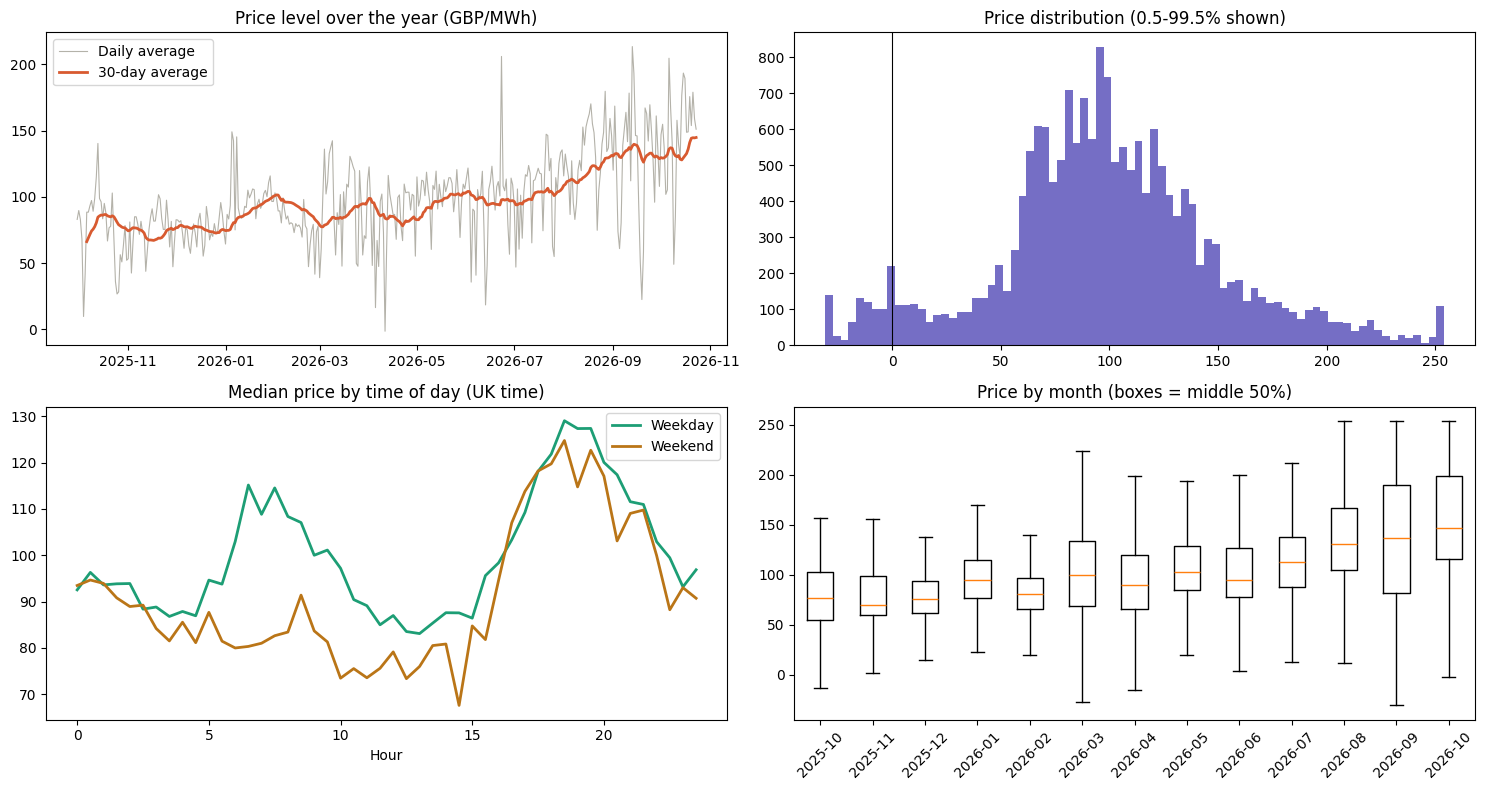

FINDINGS
- Most expensive time (weekdays): 18.5h at GBP129; cheapest: 13.0h at GBP83. Daily spread = GBP46/MWh: the battery's core opportunity.
- Weekends are GBP9/MWh cheaper on average.
- 4.3% of half-hours had NEGATIVE prices (paid to charge); 0.2% spiked above GBP300.
- Monthly median ranged from GBP70 (2025-11) to GBP147 (2026-10): the price LEVEL moves a lot, so models must adapt.


In [ ]:
#  6. EDA 1: how the imbalance price behaves
e = clean.dropna(subset=["price"]).copy()
loc = e.startTime.dt.tz_convert("Europe/London")
e["hour"] = loc.dt.hour + loc.dt.minute / 60
e["weekend"] = loc.dt.weekday >= 5
e["month"] = loc.dt.to_period("M").astype(str)
lo_, hi_ = e.price.quantile([0.005, 0.995])

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
daily = e.set_index("startTime").price.resample("D").mean()
ax[0, 0].plot(daily.index, daily, color="#B4B2A9", lw=0.8, label="Daily average")
ax[0, 0].plot(daily.index, daily.rolling(30, min_periods=7).mean(), color="#D85A30", lw=2, label="30-day average")
ax[0, 0].set_title("Price level over the year (GBP/MWh)"); ax[0, 0].legend()
ax[0, 1].hist(e.price.clip(lo_, hi_), bins=80, color="#534AB7", alpha=0.8)
ax[0, 1].axvline(0, color="black", lw=0.8); ax[0, 1].set_title("Price distribution (0.5-99.5% shown)")
prof = e.groupby(["weekend", "hour"]).price.median().unstack(0)
ax[1, 0].plot(prof.index, prof[False], color="#1D9E75", lw=2, label="Weekday")
ax[1, 0].plot(prof.index, prof[True], color="#BA7517", lw=2, label="Weekend")
ax[1, 0].set_title("Median price by time of day (UK time)"); ax[1, 0].set_xlabel("Hour"); ax[1, 0].legend()
months = sorted(e.month.unique())
ax[1, 1].boxplot([e.loc[e.month == m, "price"].clip(lo_, hi_) for m in months], showfliers=False)
ax[1, 1].set_xticks(range(1, len(months) + 1)); ax[1, 1].set_xticklabels(months)
ax[1, 1].set_title("Price by month (boxes = middle 50%)"); ax[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

wd = prof[False]
print("FINDINGS")
print(f"- Most expensive time (weekdays): {wd.idxmax():04.1f}h at GBP{wd.max():,.0f}; cheapest: {wd.idxmin():04.1f}h "
      f"at GBP{wd.min():,.0f}. Daily spread = GBP{wd.max() - wd.min():,.0f}/MWh: the battery's core opportunity.")
print(f"- Weekends are GBP{(prof[False] - prof[True]).mean():,.0f}/MWh cheaper on average.")
print(f"- {(e.price < 0).mean():.1%} of half-hours had NEGATIVE prices (paid to charge); "
      f"{(e.price > 300).mean():.1%} spiked above GBP300.")
mm = e.groupby("month").price.median()
print(f"- Monthly median ranged from GBP{mm.min():,.0f} ({mm.idxmin()}) to GBP{mm.max():,.0f} ({mm.idxmax()}): "
      "the price LEVEL moves a lot, so models must adapt.")

What drives the price: shortage vs surplus on the grid, demand left over after wind, correlations, and how much recent prices predict the next one.

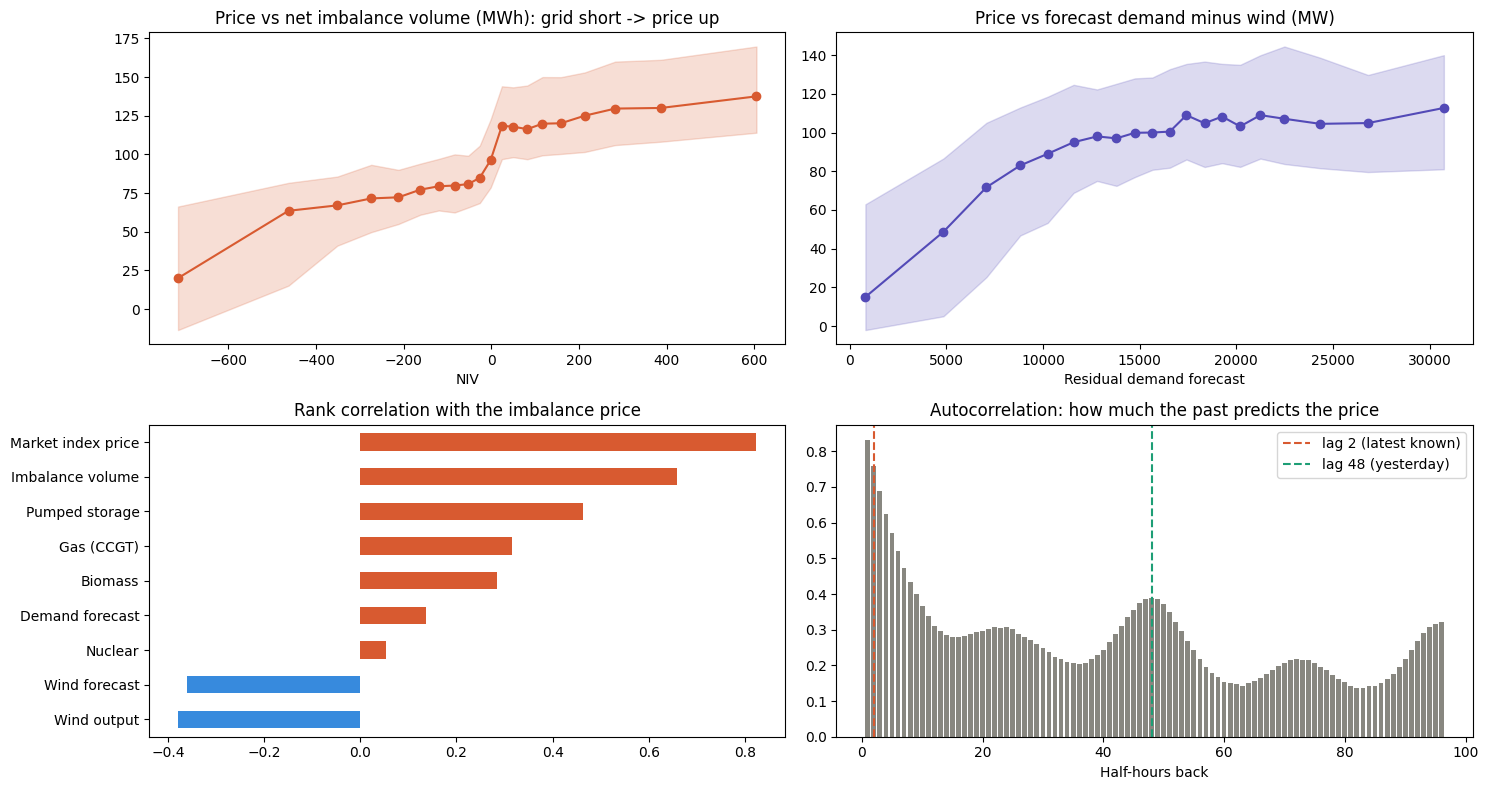

FINDINGS
- Price vs imbalance volume correlation: +0.66 (shortage = higher price; this is the core mechanism).
- Price vs (demand - wind) forecast: +0.35 (less wind left to cover demand = more gas = higher price).
- Strongest single driver: Market index price (+0.82).
- Autocorrelation at lag 2 = 0.76, at lag 48 = 0.39: recent prices carry strong information, yesterday's much less.


In [ ]:
# EDA 2: what drives the price
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
def binned(x, y, bins=20):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    d["b"] = pd.qcut(d.x, bins, duplicates="drop")
    g = d.groupby("b", observed=True).agg(x=("x", "median"), y=("y", "median"),
                                          lo=("y", lambda s: s.quantile(0.25)), hi=("y", lambda s: s.quantile(0.75)))
    return g
findings = []
if "niv" in e and e.niv.notna().any():
    g = binned(e.niv, e.price)
    ax[0, 0].fill_between(g.x, g.lo, g.hi, alpha=0.2, color="#D85A30"); ax[0, 0].plot(g.x, g.y, "o-", color="#D85A30")
    ax[0, 0].set_title("Price vs net imbalance volume (MWh): grid short -> price up"); ax[0, 0].set_xlabel("NIV")
    findings.append(f"- Price vs imbalance volume correlation: {e.price.corr(e.niv, method='spearman'):+.2f} "
                    "(shortage = higher price; this is the core mechanism).")
if {"demand_fc", "wind_fc"} <= set(e.columns) and e.wind_fc.notna().any():
    resid = e.demand_fc - e.wind_fc
    g = binned(resid, e.price)
    ax[0, 1].fill_between(g.x, g.lo, g.hi, alpha=0.2, color="#534AB7"); ax[0, 1].plot(g.x, g.y, "o-", color="#534AB7")
    ax[0, 1].set_title("Price vs forecast demand minus wind (MW)"); ax[0, 1].set_xlabel("Residual demand forecast")
    findings.append(f"- Price vs (demand - wind) forecast: {e.price.corr(resid, method='spearman'):+.2f} "
                    "(less wind left to cover demand = more gas = higher price).")
cand = {"Market index price": "market_price", "Wind output": "gen_WIND", "Gas (CCGT)": "gen_CCGT",
        "Nuclear": "gen_NUCLEAR", "Demand forecast": "demand_fc", "Wind forecast": "wind_fc",
        "Imbalance volume": "niv", "Biomass": "gen_BIOMASS", "Pumped storage": "gen_PS"}
corr = pd.Series({k: e.price.corr(e[v], method="spearman") for k, v in cand.items() if v in e}).dropna().sort_values()
corr.plot.barh(ax=ax[1, 0], color=np.where(corr > 0, "#D85A30", "#378ADD"))
ax[1, 0].set_title("Rank correlation with the imbalance price")
lags = range(1, 97)
ac = [e.set_index("startTime").price.asfreq("30min").autocorr(l) for l in lags]
ax[1, 1].bar(list(lags), ac, color="#888780"); ax[1, 1].axvline(2, color="#D85A30", ls="--", label="lag 2 (latest known)")
ax[1, 1].axvline(48, color="#1D9E75", ls="--", label="lag 48 (yesterday)")
ax[1, 1].set_title("Autocorrelation: how much the past predicts the price"); ax[1, 1].set_xlabel("Half-hours back")
ax[1, 1].legend(); plt.tight_layout(); plt.show()
print("FINDINGS"); print("\n".join(findings))
print(f"- Strongest single driver: {corr.abs().idxmax()} ({corr[corr.abs().idxmax()]:+.2f}).")
print(f"- Autocorrelation at lag 2 = {ac[1]:.2f}, at lag 48 = {ac[47]:.2f}: recent prices carry strong information, "
      "yesterday's much less.")

 Checks whether the market changed over time. If test months look different from training months, a model trained once will be biased, which motivates the fixes used below.

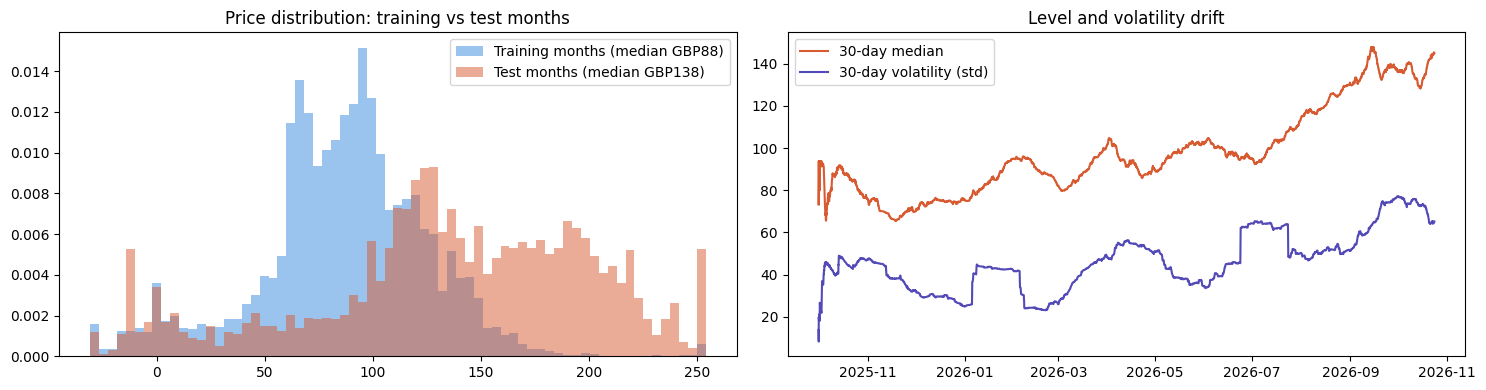

FINDINGS
- Test-month prices are GBP+50/MWh vs training months (median), volatility 1.62x.
- A model trained once on old months under-predicts after a shift like this (seen in v1: only 34% of prices fell below its median). Fixes used below:
  1) predict the CHANGE vs the latest market price (adapts to level automatically)
  2) retrain every two weeks on all data so far (walk-forward)
  3) build uncertainty ranges from the most recent 30 days of real forecast errors


In [ ]:
# EDA 3: did the market change over time? (explains model bias)
k1, k2 = int(len(e) * 0.65), int(len(e) * 0.80)
early, late = e.iloc[:k1], e.iloc[k2:]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
bins = np.linspace(lo_, hi_, 70)
ax[0].hist(early.price.clip(lo_, hi_), bins=bins, density=True, alpha=0.5, color="#378ADD",
           label=f"Training months (median GBP{early.price.median():.0f})")
ax[0].hist(late.price.clip(lo_, hi_), bins=bins, density=True, alpha=0.5, color="#D85A30",
           label=f"Test months (median GBP{late.price.median():.0f})")
ax[0].legend(); ax[0].set_title("Price distribution: training vs test months")
roll = e.set_index("startTime").price.rolling("30D")
ax[1].plot(roll.median().index, roll.median(), color="#D85A30", label="30-day median")
ax[1].plot(roll.std().index, roll.std(), color="#534AB7", label="30-day volatility (std)")
ax[1].legend(); ax[1].set_title("Level and volatility drift"); plt.tight_layout(); plt.show()
shift = late.price.median() - early.price.median()
print("FINDINGS")
print(f"- Test-month prices are GBP{shift:+,.0f}/MWh vs training months (median), "
      f"volatility {late.price.std() / early.price.std():.2f}x.")
print("- A model trained once on old months under-predicts after a shift like this (seen in v1: only 34% of prices "
      "fell below its median). Fixes used below:")
print("  1) predict the CHANGE vs the latest market price (adapts to level automatically)")
print("  2) retrain every two weeks on all data so far (walk-forward)")
print("  3) build uncertainty ranges from the most recent 30 days of real forecast errors")

 Turns the cleaned data into model inputs. Rule: a decision at the start of a half-hour may only use prices already published (2 periods back), the latest fuel mix and market price, and forecasts published in advance.

In [ ]:
#  9. Leak-free features
# Decision for period P is made at the START of P. Known then:
#   * imbalance prices up to P-2 (P-1's price is published ~15 min after P-1 ends)
#   * fuel mix and market price for P-1 (near real time)
#   * wind / demand forecasts for P published >= 1 hour earlier
def col(df, name):
    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)

def build_features(raw):
    df = raw.sort_values("startTime").reset_index(drop=True).copy()
    local = df["startTime"].dt.tz_convert("Europe/London")
    gen = [c for c in df.columns if c.startswith("gen_")]
    df["gas"]     = col(df, "gen_CCGT").fillna(0) + col(df, "gen_OCGT").fillna(0)
    df["imports"] = df[[c for c in gen if c.startswith("gen_INT")]].sum(axis=1, min_count=1) if gen else np.nan
    df["total_gen"] = df[gen].sum(axis=1, min_count=1) if gen else np.nan
    df["wind_act"]  = col(df, "gen_WIND")

    f = pd.DataFrame({"startTime": df["startTime"], "price": col(df, "price")})
    p = df["price"]
    for k in (2, 3, 4, 6, 48, 336):                      # 48 = same time yesterday, 336 = last week
        f[f"price_lag{k}"] = p.shift(k)
    known = p.shift(2)
    f["price_mean_6"]  = known.rolling(6, min_periods=3).mean()
    f["price_std_6"]   = known.rolling(6, min_periods=3).std()
    f["price_max_48"]  = known.rolling(48, min_periods=12).max()
    f["ref_price"]     = known.rolling(336, min_periods=48).median()   # 7-day typical price
    # typical price at this time of day over the last 7 days (all already published)
    f["tod_profile"]   = pd.concat([p.shift(48 * k) for k in range(1, 8)], axis=1).median(axis=1)
    # smoother 28-day daily shape used for planning ahead (still only published prices)
    f["profile28"] = (pd.concat([p.shift(48 * k) for k in range(1, 29)], axis=1).median(axis=1)
                        .rolling(5, center=True, min_periods=1).median())
    f["price_vs_ref"]  = f["price_lag2"] - f["ref_price"]
    f["niv_lag2"]      = col(df, "niv").shift(2)
    f["niv_lag3"]      = col(df, "niv").shift(3)
    f["mkt_lag1"]      = col(df, "market_price").shift(1)
    f["mkt_lag2"]      = col(df, "market_price").shift(2)
    f["mkt_minus_ref"] = f["mkt_lag1"] - f["ref_price"]
    f["wind_act_lag1"] = df["wind_act"].shift(1)
    f["wind_fc"]       = col(df, "wind_fc")
    f["wind_err_lag1"] = df["wind_act"].shift(1) - col(df, "wind_fc").shift(1)   # +: more wind than expected
    f["wind_ramp_fc"]  = col(df, "wind_fc") - df["wind_act"].shift(1)            # expected change in wind
    f["demand_fc"]     = col(df, "demand_fc")
    f["residual_fc"]   = col(df, "demand_fc") - col(df, "wind_fc")                      # demand left for gas etc.
    f["gas_lag1"]      = df["gas"].shift(1)
    f["gas_share_lag1"] = (df["gas"] / df["total_gen"]).shift(1)
    f["nuclear_lag1"]  = col(df, "gen_NUCLEAR").shift(1)
    f["imports_lag1"]  = df["imports"].shift(1)
    f["gas_ramp_lag1"] = df["gas"].shift(1) - df["gas"].shift(3)
    hr = local.dt.hour + local.dt.minute / 60
    f["hour"] = hr
    f["hour_sin"], f["hour_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)
    f["weekday"] = local.dt.weekday
    f["weekend"] = (local.dt.weekday >= 5).astype(int)
    f["month"]   = local.dt.month
    f["is_peak"] = ((hr >= 16) & (hr < 19.5)).astype(int)
    # latest market price: the anchor for change models. Live, the newest prices may not be published yet,
    # so fall back to the most recent known value (forward-fill uses only the past)
    f["base"] = f["mkt_lag1"].fillna(f["price_lag2"]).ffill()
    # day-ahead forecasts (published >= 24h before each half-hour): inputs to the multi-horizon model
    f["wind_fc_da"]   = col(df, "wind_fc_da")
    f["demand_fc_da"] = col(df, "demand_fc_da")
    f["resid_da"]     = f["demand_fc_da"] - f["wind_fc_da"]
    f["local_date"] = local.dt.date
    return f

feat = build_features(clean)
FEATURES = [c for c in feat.columns
            if c not in ("startTime", "price", "local_date", "profile28", "base", "wind_fc_da", "demand_fc_da", "resid_da") and feat[c].notna().mean() > 0.5]
data = feat.dropna(subset=["price", "price_lag2", "ref_price", "profile28"]).reset_index(drop=True)
print(f"{len(data):,} usable half-hours, {len(FEATURES)} features:")
print(FEATURES)

18,575 usable half-hours, 35 features:
['price_lag2', 'price_lag3', 'price_lag4', 'price_lag6', 'price_lag48', 'price_lag336', 'price_mean_6', 'price_std_6', 'price_max_48', 'ref_price', 'tod_profile', 'price_vs_ref', 'niv_lag2', 'niv_lag3', 'mkt_lag1', 'mkt_lag2', 'mkt_minus_ref', 'wind_act_lag1', 'wind_fc', 'wind_err_lag1', 'wind_ramp_fc', 'demand_fc', 'residual_fc', 'gas_lag1', 'gas_share_lag1', 'nuclear_lag1', 'imports_lag1', 'gas_ramp_lag1', 'hour', 'hour_sin', 'hour_cos', 'weekday', 'weekend', 'month', 'is_peak']


 The decision engine. `step` applies one charge/discharge with real limits and losses. `lp_schedule` is a small linear program that finds the most profitable charge/discharge plan over the next 22 hours. `run_mpc` repeats this every half-hour, acting only on the first step (re-planning with fresh information), which is how real battery operators work.

In [ ]:
# 10. Battery simulator, decision engine and benchmarks
def step(soc, action, price):
    # action in [-1, 1]: + = discharge, - = charge (fraction of max power)
    if action > 1e-9:
        out = min(action * E_STEP, (soc - SOC_MIN) * ETA)
        return soc - out / ETA, 0.0, out, out * price - DEG_COST * out
    if action < -1e-9:
        inn = min(-action * E_STEP, (SOC_MAX - soc) / ETA)
        return soc + inn * ETA, inn, 0.0, -inn * price
    return soc, 0.0, 0.0, 0.0

def lp_schedule(soc0, p_buy, p_sell, end_soc=SOC_START, end_equal=False, end_free=False):
    # Best charge/discharge plan for given buy/sell price paths.
    # Variables per half-hour: charge c, discharge d (grid MWh) and battery level s.
    # A battery cannot charge and discharge in the same half-hour. With positive prices doing both never pays,
    # but at NEGATIVE prices a plain linear program would do both to "burn" energy as losses and get paid,
    # so those half-hours get an on/off switch u (u=1: may charge, u=0: may discharge): a small mixed-integer program.
    p_buy, p_sell = np.asarray(p_buy, float), np.asarray(p_sell, float)
    n = len(p_buy)
    neg = np.flatnonzero(p_buy < 0); m = len(neg); nv = 3 * n + m
    cost = np.concatenate([p_buy, -p_sell + DEG_COST, np.zeros(n), np.zeros(m)])
    I = sparse.identity(n, format="csr")
    prev = sparse.diags([np.ones(n - 1)], [-1], shape=(n, n), format="csr")
    # level now - level before - ETA * charge + discharge / ETA = 0   (level before the first step = soc0)
    dyn = sparse.hstack([-ETA * I, (1 / ETA) * I, I - prev, sparse.csr_matrix((n, m))], format="csr")
    b0 = np.zeros(n); b0[0] = soc0
    cons = [LinearConstraint(dyn, b0, b0)]
    last = sparse.csr_matrix(([1.0], ([0], [3 * n - 1])), shape=(1, nv))
    if end_equal:
        cons.append(LinearConstraint(last, end_soc, end_soc))
    elif not end_free:
        cons.append(LinearConstraint(last, min(end_soc, SOC_MAX), np.inf))   # end at least this full
    if m:
        r = np.arange(m)
        sw = sparse.csr_matrix((np.full(m, E_STEP), (r, 3 * n + r)), shape=(m, nv))
        cons.append(LinearConstraint(sparse.csr_matrix((np.ones(m), (r, neg)), shape=(m, nv)) - sw, -np.inf, 0))      # c <= 25 u
        cons.append(LinearConstraint(sparse.csr_matrix((np.ones(m), (r, n + neg)), shape=(m, nv)) + sw, -np.inf, E_STEP))  # d <= 25 (1-u)
    lb = np.concatenate([np.zeros(2 * n), np.full(n, SOC_MIN), np.zeros(m)])
    ub = np.concatenate([np.full(2 * n, E_STEP), np.full(n, SOC_MAX), np.ones(m)])
    res = milp(cost, constraints=cons, bounds=Bounds(lb, ub),
               integrality=np.concatenate([np.zeros(3 * n), np.ones(m)]))
    if not res.success: return None, None
    return res.x[:n], res.x[n:2 * n]

HORIZON = 44   # plan 22 hours ahead; every price used is already published or forecast at decision time

def plan_paths(df, p1, future=None):
    # The 44 expected prices the planner uses at each half-hour:
    #   step 1  = p1, our forecast for the coming half-hour
    #   steps 2..44 = the multi-horizon forecast when given (`future`, rows x 43), else the typical 28-day shape
    prof = df["profile28"].values
    paths = np.empty((len(df), HORIZON))
    for i in range(len(df)):
        fut = prof[i + 1:i + HORIZON]
        if len(fut) < HORIZON - 1:
            fut = np.concatenate([fut, np.full(HORIZON - 1 - len(fut), prof[i])])
        if future is not None:
            fz = future[i]
            fut = np.where(np.isfinite(fz), fz, fut)
        paths[i, 0], paths[i, 1:] = p1[i], fut
    return paths

def run_mpc(df, p1, kappa=0.0, soc=SOC_START, future=None):
    # Rolling optimisation (model predictive control): every half-hour, plan the next 22h,
    # carry out only the first step at the real price, then re-plan with fresh information.
    #   kappa = trading hurdle (GBP/MWh): buying looks dearer and selling cheaper by kappa, so the plan
    #           ignores spreads smaller than forecast noise. A number, or one value per half-hour.
    actual, paths = df["price"].values, plan_paths(df, p1, future)
    log = []
    for i in range(len(df)):
        k = kappa[i] if np.ndim(kappa) else kappa
        ch, dis = lp_schedule(soc, paths[i] + k, paths[i] - k)
        a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP
        soc, e_in, e_out, pnl = step(soc, a, actual[i])
        log.append((df["startTime"].iloc[i], a, soc, e_in, e_out, pnl))
    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])

def blend(df, forecast, alpha):
    # Trust the forecast in proportion to its proven skill: alpha=1 uses it fully, 0 ignores it
    prof = df["profile28"].values
    return prof + alpha * (np.asarray(forecast) - prof)

def run_fixed(df, soc=SOC_START):
    # What many simple sites do: charge overnight, discharge at the evening peak
    log = []
    for t, h, p in zip(df["startTime"], df["hour"], df["price"]):
        a = -1.0 if 1 <= h < 4.5 else 1.0 if 16.5 <= h < 19.5 else 0.0
        soc, e_in, e_out, pnl = step(soc, a, p)
        log.append((t, a, soc, e_in, e_out, pnl))
    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])

def perfect_hindsight(df, soc0=SOC_START):
    # Upper bound: the best possible schedule over the WHOLE period if every price were known in advance.
    # Same start as the other strategies, charge carried across days, free to end at any level.
    p = df["price"].values
    ch, dis = lp_schedule(soc0, p, p, end_free=True)
    if ch is None: return 0.0, pd.DataFrame(columns=["startTime", "pnl"])
    pnl = p * dis - p * ch - DEG_COST * dis
    return float(pnl.sum()), pd.DataFrame({"startTime": df["startTime"].values, "pnl": pnl})

 real Elexon data, one row per half-hour; no look-ahead anywhere (each forecast is
> used only if it was published early enough); gaps filled only from the past; price spikes kept because they are
> real; all times in UTC, so clock changes (like tonight's) are handled correctly.

 Automated tests of the battery model: no charging and discharging in the same half-hour (even at negative prices, on 4,000 real half-hours), charge limits respected, and no selling from an empty battery.

In [ ]:
 # 10b. Sanity checks on the battery model
# 1) a battery never charges and discharges in the same half-hour, even at negative prices
neg = np.array([-200.0, -200.0, -50.0])
ch, dis = lp_schedule(95.0, neg, neg)
assert not ((ch > 1e-6) & (dis > 1e-6)).any(), "simultaneous charge and discharge"
p_ = data.price.values[:4000]                                   # real prices, including negative ones
ch, dis = lp_schedule(SOC_START, p_, p_, end_free=True)
assert not ((ch > 1e-6) & (dis > 1e-6)).any(), "simultaneous charge and discharge on real prices"
# 2) the plan respects the battery: rebuild the level from the plan and check its limits
lvl = SOC_START + np.cumsum(ETA * ch - dis / ETA)
assert lvl.min() >= SOC_MIN - 1e-6 and lvl.max() <= SOC_MAX + 1e-6 and ch.max() <= E_STEP + 1e-6
# 3) the simulator cannot sell from an empty battery or buy into a full one
assert step(SOC_MIN, 1.0, 100.0)[2] == 0 and step(SOC_MAX, -1.0, 100.0)[1] == 0
print(f"All battery checks passed ({int((p_ < 0).sum())} negative-price half-hours tested, none charging and "
      "discharging at once).")

All battery checks passed (151 negative-price half-hours tested, none charging and discharging at once).


## Model comparison


 Four forecasters for the next half-hour: two simple baselines and two LightGBM models (one predicts the price, one predicts the change from the latest market price). Optional small hyperparameter search on validation months. Each model is retrained every two weeks on all data available at that time (walk-forward), exactly as it would run live.

In [ ]:
# 11. Candidate models, walk-forward retraining
n = len(data)
i_val, i_test = int(n * 0.65), int(n * 0.80)
CHUNK, GAP = 672, 2           # retrain every 2 weeks; skip the 2 newest rows (their prices aren't published yet)
WF_START = max(i_val - 2 * CHUNK, 2000)
val, test = data.iloc[i_val:i_test], data.iloc[i_test:]
print(f"validate {val.startTime.min():%d %b %Y} -> {val.startTime.max():%d %b %Y} ({len(val):,})   "
      f"test {test.startTime.min():%d %b %Y} -> {test.startTime.max():%d %b %Y} ({len(test):,})")

LGB_PARAMS = dict(n_estimators=500, learning_rate=0.04, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

LGB_HALF_LIFE = None   # days; recent data counts more when set (chosen on validation below)

def recency_weights(times, half_life_days):
    # weight 1 for the newest row, 0.5 for a row half_life_days older, and so on
    if not half_life_days: return None
    age = (times.max() - times).dt.total_seconds().values / 86400
    return 0.5 ** (age / half_life_days)

def fit_cand(kind, df):
    # the two simple baselines need no training
    if kind in ("persist", "market"): return None
    w = recency_weights(df.startTime, LGB_HALF_LIFE)
    # LightGBM with "l1" loss = predicts the median, so rare price spikes don't dominate training
    if kind == "lgb_price":                      # learns the price directly
        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price, sample_weight=w)
    if kind in ("lgb_change", "ens"):            # learns the CHANGE from the latest market price (adapts to price level)
        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price - df.base, sample_weight=w)
    raise ValueError(kind)

def predict_cand(kind, obj, df):
    if kind == "persist":    return df.price_lag2.values                     # "price stays as last published"
    if kind == "market":     return df.base.values                           # "price = latest market price"
    if kind == "lgb_price":  return obj.predict(df[FEATURES])
    if kind == "lgb_change": return df.base.values + obj.predict(df[FEATURES])
    if kind == "ens":        return 0.5 * (df.price_lag2.values + df.base.values + obj.predict(df[FEATURES]))   # average of the two views
    raise ValueError(kind)

CANDIDATES = {
    "Persistence (latest known price)": "persist",
    "Market index (last half-hour)":    "market",
    "LightGBM (price)":                 "lgb_price",
    "LightGBM (change vs market)":      "lgb_change",
    "Ensemble (persistence + LightGBM)": "ens",
}

def walk_forward(kind):
    out = np.full(n, np.nan)
    for s in range(WF_START, n, CHUNK):
        e_ = min(s + CHUNK, n)
        obj = fit_cand(kind, data.iloc[:s - GAP])
        out[s:e_] = predict_cand(kind, obj, data.iloc[s:e_])
    return out

LGB_GRID = [   # small, sensible search space (the second entry is the default)
    dict(num_leaves=15,  learning_rate=0.05, n_estimators=400, min_child_samples=50),
    dict(num_leaves=31,  learning_rate=0.04, n_estimators=500, min_child_samples=50),
    dict(num_leaves=63,  learning_rate=0.03, n_estimators=600, min_child_samples=100),
    dict(num_leaves=31,  learning_rate=0.08, n_estimators=250, min_child_samples=20),
    dict(num_leaves=127, learning_rate=0.03, n_estimators=500, min_child_samples=200),
    dict(num_leaves=15,  learning_rate=0.03, n_estimators=900, min_child_samples=100),
    dict(num_leaves=31,  learning_rate=0.03, n_estimators=800, min_child_samples=100, reg_lambda=5.0),
    dict(num_leaves=63,  learning_rate=0.05, n_estimators=300, min_child_samples=50, colsample_bytree=0.5),
]
if TUNE_MODELS:
    t0 = time.time()
    tr_, va_ = data.iloc[:i_val - GAP], data.iloc[i_val:i_test]
    maes = []
    for g_ in LGB_GRID:
        m_ = lgb.LGBMRegressor(objective="l1", **{**LGB_PARAMS, **g_}).fit(tr_[FEATURES], tr_.price - tr_.base)
        maes.append(np.mean(np.abs(va_.price - (va_.base + m_.predict(va_[FEATURES])))))
    tune_tab = pd.DataFrame(LGB_GRID).assign(**{"Validation MAE": maes}).sort_values("Validation MAE")
    print("Hyperparameter search for the next-half-hour LightGBM (trained on training months, scored on validation):")
    print(tune_tab.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:g}"))
    best_i = int(np.argmin(maes))
    LGB_PARAMS = {**LGB_PARAMS, **LGB_GRID[best_i]}
    print(f"-> chosen setting #{best_i + 1}: validation error GBP{maes[best_i]:.2f} vs GBP{maes[1]:.2f} with defaults "
          f"({time.time() - t0:.0f}s)")
    # Recency weighting: prices drifted over the year (EDA 3), so test whether recent data should count more
    hl_scores = {}
    for hl in (None, 180, 90, 45):
        w_ = recency_weights(tr_.startTime, hl)
        m_ = lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(tr_[FEATURES], tr_.price - tr_.base, sample_weight=w_)
        hl_scores[hl] = np.mean(np.abs(va_.price - (va_.base + m_.predict(va_[FEATURES]))))
    LGB_HALF_LIFE = min(hl_scores, key=hl_scores.get)
    print("Recency weighting (half-life in days -> validation error): "
          + ", ".join(f"{'none' if k is None else k}: GBP{v:.2f}" for k, v in hl_scores.items())
          + f"  -> chosen: {'none' if LGB_HALF_LIFE is None else str(LGB_HALF_LIFE) + ' days'}\n")

t0 = time.time(); WF = {}
for name, kind in CANDIDATES.items():
    if kind == "ens":   # same fitted model as LightGBM (change), so reuse its forecasts: average with persistence
        WF[name] = 0.5 * (WF["Persistence (latest known price)"] + WF["LightGBM (change vs market)"])
    else:
        WF[name] = walk_forward(kind)
    print(f"   {name:36s} done ({time.time() - t0:.0f}s)")

def band(q50, window=1440):
    # 80% range from the last 30 days of REAL out-of-sample errors (only errors already known)
    res = pd.Series(data.price.values - q50).shift(GAP)
    lo = res.rolling(window, min_periods=200).quantile(0.10).values
    hi = res.rolling(window, min_periods=200).quantile(0.90).values
    return pd.DataFrame({"q10": q50 + lo, "q50": q50, "q90": q50 + hi}, index=data.index)

validate 10 Jun 2026 -> 07 Aug 2026 (2,787)   test 07 Aug 2026 -> 23 Oct 2026 (3,715)
Hyperparameter search for the next-half-hour LightGBM (trained on training months, scored on validation):
 num_leaves  learning_rate  n_estimators  min_child_samples  reg_lambda  colsample_bytree  Validation MAE
        127           0.03           500                200           -                 -         22.2443
         31           0.03           800                100           5                 -         22.3035
         15           0.03           900                100           -                 -         22.3126
         15           0.05           400                 50           -                 -         22.3662
         63           0.03           600                100           -                 -         22.4318
         31           0.08           250                 20           -                 -         22.4535
         63           0.05           300                 50       

Scores each forecaster on the validation months by accuracy, by direction (above or below the usual price) and, most importantly, by the profit the battery makes using it. The best by profit is chosen.

(71s)

                            Model  MAE RMSE Direction right Validation profit (GBP)
 Persistence (latest known price) 25.3 39.6             74%                 314,391
Ensemble (persistence + LightGBM) 22.6 33.6             76%                 308,212
                 LightGBM (price) 23.1 39.9             76%                 296,128
    Market index (last half-hour) 24.2 33.4             74%                 283,793
      LightGBM (change vs market) 22.2 32.2             76%                 283,692

CHOSEN: Persistence (latest known price)  (highest validation profit)
Note: the most ACCURATE model was LightGBM (change vs market); we choose by profit because the decision is what pays.


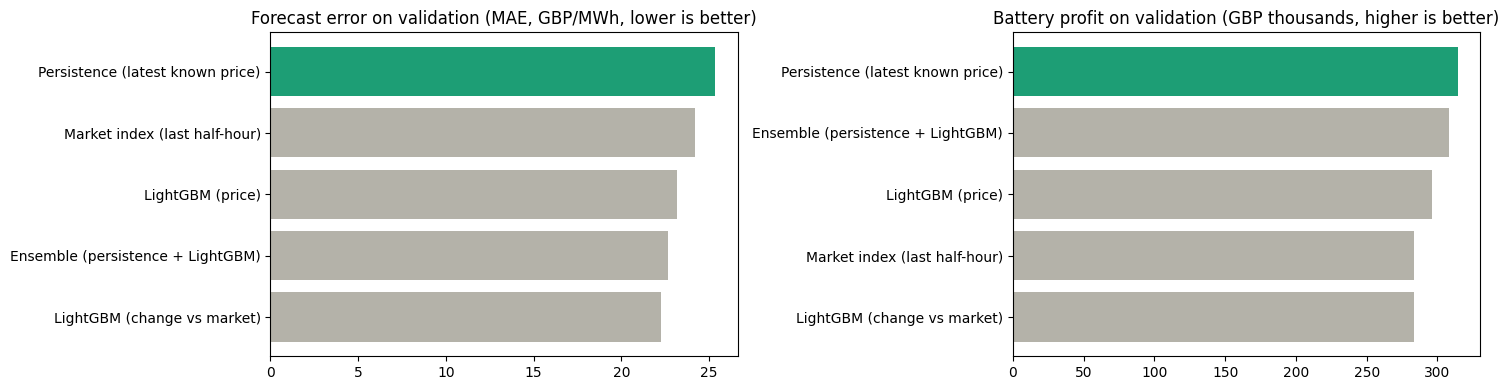

Chosen model's 80% range on validation holds 79% of actual prices (below median: 49%, ideal 50%).


In [ ]:
#  12. Compare on VALIDATION months and choose the best by profit
t0 = time.time()
rows = []
yv = val.price.values
for name, q50 in WF.items():
    pv = q50[i_val:i_test]
    prof = val.tod_profile.values
    ok = ~np.isnan(prof)
    direction = (np.nan if np.allclose(pv[ok], prof[ok], equal_nan=True)     # the profile itself has no direction
                 else np.mean(np.sign(pv[ok] - prof[ok]) == np.sign(yv[ok] - prof[ok])))
    profit = run_mpc(val, blend(val, pv, 0.5), 5.0)["pnl"].sum()
    rows.append({"Model": name, "MAE": np.mean(np.abs(yv - pv)), "RMSE": np.sqrt(np.mean((yv - pv) ** 2)),
                 "Direction right": direction, "Validation profit (GBP)": profit})
comp = pd.DataFrame(rows).sort_values("Validation profit (GBP)", ascending=False).reset_index(drop=True)
BEST = comp.loc[0, "Model"]; BEST_KIND = CANDIDATES[BEST]
print(f"({time.time() - t0:.0f}s)\n")
print(comp.to_string(index=False, na_rep="n/a", formatters={"MAE": "{:.1f}".format, "RMSE": "{:.1f}".format,
      "Direction right": lambda v: "n/a" if pd.isna(v) else f"{v:.0%}", "Validation profit (GBP)": "{:,.0f}".format}))
print(f"\nCHOSEN: {BEST}  (highest validation profit)")
best_mae = comp.sort_values("MAE").iloc[0]
if best_mae.Model != BEST:
    print(f"Note: the most ACCURATE model was {best_mae.Model}; we choose by profit because the decision is what pays.")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
c2 = comp.sort_values("MAE")
ax[0].barh(c2.Model, c2.MAE, color=["#1D9E75" if m == BEST else "#B4B2A9" for m in c2.Model])
ax[0].set_title("Forecast error on validation (MAE, GBP/MWh, lower is better)")
c3 = comp.sort_values("Validation profit (GBP)")
ax[1].barh(c3.Model, c3["Validation profit (GBP)"] / 1000, color=["#1D9E75" if m == BEST else "#B4B2A9" for m in c3.Model])
ax[1].set_title("Battery profit on validation (GBP thousands, higher is better)")
plt.tight_layout(); plt.show()

BANDS = {name: band(q50) for name, q50 in WF.items()}
pred_all = BANDS[BEST]
pred_val, pred_test = pred_all.iloc[i_val:i_test], pred_all.iloc[i_test:]
cv = np.mean((yv >= pred_val.q10) & (yv <= pred_val.q90))
print(f"Chosen model's 80% range on validation holds {cv:.0%} of actual prices "
      f"(below median: {np.mean(yv < pred_val.q50):.0%}, ideal 50%).")

## Multi-horizon forecast: the whole 22-hour plan from machine learning

The optimiser plans 22 hours ahead. Until now only the coming half-hour came from a model; the other 43 steps used the
28-day typical shape. Here a second LightGBM model forecasts **every one of the next 43 half-hours**, using the official
day-ahead **wind and demand forecasts** (published at least 24 hours before each half-hour, so they were genuinely
available at decision time), the current state of the market, and the typical shape. It is retrained every 4 weeks (walk-forward).

A second LightGBM model forecasts each of the next 43 half-hours (22 hours) using the official day-ahead wind and demand forecasts. One training row per (decision time, hours ahead) pair. The chart compares its error with the typical daily shape at every horizon.

Hyperparameter search for the multi-horizon model (scored on validation months):
 num_leaves  learning_rate  n_estimators  min_child_samples  colsample_bytree  Validation MAE
        255           0.05           250                400                 -         32.0254
         63           0.05           300                100                 -         32.0383
         63           0.03           600                100               0.6         32.1402
        127           0.05           300                200                 -         32.1409
         31           0.05           400                200                 -         32.3637
-> chosen setting #5: GBP32.03 vs GBP32.04 with defaults (47s)
Recency weighting (half-life in days -> validation error): none: GBP32.03, 180: GBP32.22, 90: GBP32.19, 45: GBP32.48  -> chosen: none

Multi-horizon walk-forward done (70s)


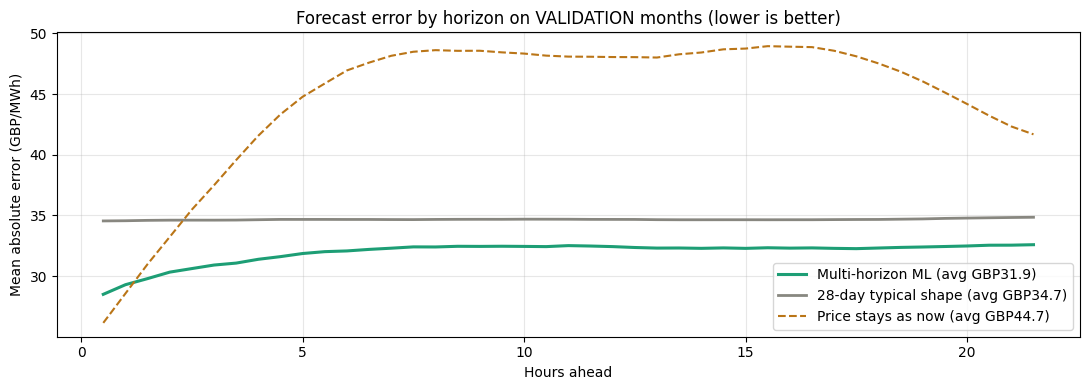

Across the 22-hour plan, the ML forecast is 8% more accurate than the 28-day shape and 29% more accurate than 'price stays as now'.


In [ ]:
# 12b. Multi-horizon forecast for the next 43 half-hours
HZ = HORIZON - 1
NOW_COLS = ["price_lag2", "price_mean_6", "price_std_6", "price_max_48", "ref_price", "niv_lag2",
            "wind_err_lag1", "wind_act_lag1", "gas_lag1", "mkt_lag1"]                     # known at decision time
AT_COLS = ["hour", "weekday", "weekend", "month", "is_peak", "profile28", "tod_profile", "price_lag48",
           "price_lag336", "wind_fc_da", "demand_fc_da", "resid_da"]                       # describe the target half-hour
MH_KS_TRAIN = np.array([1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 28, 32, 38, 43])
MH_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=100,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

def arrays(f):
    return {c: pd.to_numeric(f[c], errors="coerce").values.astype(float) for c in f.columns
            if c not in ("startTime", "local_date")}

def mh_frame(FA, js, ks):
    # one row per (decision half-hour j, steps ahead k); target = price at j+k minus its typical value
    N = len(FA["price"])
    J = np.repeat(np.asarray(js), len(ks)); K = np.tile(np.asarray(ks), len(js))
    valid = (J + K) < N
    T = np.minimum(J + K, N - 1)
    nan = np.full(len(J), np.nan)
    X = {f"now_{c}": FA.get(c, nan)[J] if c in FA else nan for c in NOW_COLS}
    X.update({f"at_{c}": FA[c][T] if c in FA else nan for c in AT_COLS})
    X["k"] = K
    X["dev_now"] = FA["base"][J] - FA["profile28"][J]
    X["wind_da_change"] = (FA["wind_fc_da"][T] if "wind_fc_da" in FA else nan) - FA["wind_act_lag1"][J]
    y = FA["price"][T] - FA["profile28"][T]
    return pd.DataFrame(X), y, T, valid

MH_HALF_LIFE = None   # days; chosen on validation below

def fit_mh(FA, train_js, cutoff_pos, params=None, half_life=-1):
    X, y, T, valid = mh_frame(FA, train_js, MH_KS_TRAIN)
    ok = valid & (T <= cutoff_pos - 3) & np.isfinite(y)       # only targets already published at cutoff
    hl = MH_HALF_LIFE if half_life == -1 else half_life
    J = np.repeat(np.asarray(train_js), len(MH_KS_TRAIN))
    w = 0.5 ** ((cutoff_pos - J) / 48 / hl) if hl else None    # 48 half-hours per day
    return lgb.LGBMRegressor(objective="l1", **(params or MH_PARAMS)).fit(X[ok], y[ok],
                                                                           sample_weight=None if w is None else w[ok])

def predict_mh(model, FA, js):
    ks = np.arange(1, HZ + 1)
    X, _, T, valid = mh_frame(FA, js, ks)
    p = model.predict(X) + FA["profile28"][T]
    p[~valid] = np.nan
    return p.reshape(len(js), HZ)

FA_ALL = arrays(feat)
POS = pd.Index(feat.startTime).get_indexer(data.startTime)          # each decision row on the full timeline
KS = np.arange(1, HZ + 1)
FUT_IDX = np.minimum(POS[:, None] + KS[None, :], len(feat) - 1)
FUT_OK = (POS[:, None] + KS[None, :]) < len(feat)
ACT_FUT = np.where(FUT_OK, FA_ALL["price"][FUT_IDX], np.nan)         # what actually happened (for scoring only)
PROF_FUT = np.where(FUT_OK, FA_ALL["profile28"][FUT_IDX], np.nan)    # the 28-day typical shape (old plan)

MH_GRID = [
    dict(num_leaves=63, learning_rate=0.05, n_estimators=300, min_child_samples=100),   # default
    dict(num_leaves=31, learning_rate=0.05, n_estimators=400, min_child_samples=200),
    dict(num_leaves=127, learning_rate=0.05, n_estimators=300, min_child_samples=200),
    dict(num_leaves=63, learning_rate=0.03, n_estimators=600, min_child_samples=100, colsample_bytree=0.6),
    dict(num_leaves=255, learning_rate=0.05, n_estimators=250, min_child_samples=400),
]
if TUNE_MODELS:
    t0 = time.time()
    ev = np.arange(i_val, i_test, 4)                     # validation decisions (every 2 hours, all 43 steps)
    act = ACT_FUT[ev]; maes = []
    for g_ in MH_GRID:
        m_ = fit_mh(FA_ALL, POS[:i_val:2], POS[i_val], params={**MH_PARAMS, **g_})
        p_ = predict_mh(m_, FA_ALL, POS[ev]); ok_ = np.isfinite(act) & np.isfinite(p_)
        maes.append(np.mean(np.abs(act - p_)[ok_]))
    print("Hyperparameter search for the multi-horizon model (scored on validation months):")
    print(pd.DataFrame(MH_GRID).assign(**{"Validation MAE": maes}).sort_values("Validation MAE")
          .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:g}"))
    best_i = int(np.argmin(maes)); MH_PARAMS = {**MH_PARAMS, **MH_GRID[best_i]}
    print(f"-> chosen setting #{best_i + 1}: GBP{maes[best_i]:.2f} vs GBP{maes[0]:.2f} with defaults ({time.time() - t0:.0f}s)")
    hl_scores = {}
    for hl in (None, 180, 90, 45):
        m_ = fit_mh(FA_ALL, POS[:i_val:2], POS[i_val], half_life=hl)
        p_ = predict_mh(m_, FA_ALL, POS[ev]); ok_ = np.isfinite(act) & np.isfinite(p_)
        hl_scores[hl] = np.mean(np.abs(act - p_)[ok_])
    MH_HALF_LIFE = min(hl_scores, key=hl_scores.get)
    print("Recency weighting (half-life in days -> validation error): "
          + ", ".join(f"{'none' if k is None else k}: GBP{v:.2f}" for k, v in hl_scores.items())
          + f"  -> chosen: {'none' if MH_HALF_LIFE is None else str(MH_HALF_LIFE) + ' days'}\n")

t0 = time.time()
MH_CHUNK = 1344                                                       # retrain every 4 weeks
MH = np.full((n, HZ), np.nan)
for s_ in range(WF_START, n, MH_CHUNK):
    e_ = min(s_ + MH_CHUNK, n)
    model_ = fit_mh(FA_ALL, POS[:s_:2], POS[s_])
    MH[s_:e_] = predict_mh(model_, FA_ALL, POS[s_:e_])
print(f"Multi-horizon walk-forward done ({time.time() - t0:.0f}s)")

def future_path(lo, hi, beta):
    # plan prices for steps 2..44: typical shape moved towards the ML forecast by `beta` (0 = old behaviour)
    prof, mh = PROF_FUT[lo:hi], MH[lo:hi]
    return np.where(np.isfinite(mh) & np.isfinite(prof), prof + beta * (mh - prof), prof)

def mae_by_k(pred, lo, hi):
    a = ACT_FUT[lo:hi]; m = np.isfinite(a) & np.isfinite(pred[lo:hi])
    return np.array([np.mean(np.abs(a[:, k] - pred[lo:hi, k])[m[:, k]]) for k in range(HZ)])

persist_fut = np.repeat(data.base.values[:, None], HZ, axis=1)        # "price stays as it is now"
mk_ml, mk_prof, mk_pers = (mae_by_k(x, i_val, i_test) for x in (MH, PROF_FUT, persist_fut))
fig, ax = plt.subplots(figsize=(11, 4))
hrs = KS / 2
ax.plot(hrs, mk_ml, color="#1D9E75", lw=2.2, label=f"Multi-horizon ML (avg GBP{np.nanmean(mk_ml):.1f})")
ax.plot(hrs, mk_prof, color="#888780", lw=2, label=f"28-day typical shape (avg GBP{np.nanmean(mk_prof):.1f})")
ax.plot(hrs, mk_pers, color="#BA7517", lw=1.5, ls="--", label=f"Price stays as now (avg GBP{np.nanmean(mk_pers):.1f})")
ax.set_xlabel("Hours ahead"); ax.set_ylabel("Mean absolute error (GBP/MWh)")
ax.set_title("Forecast error by horizon on VALIDATION months (lower is better)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Across the 22-hour plan, the ML forecast is {1 - np.nanmean(mk_ml) / np.nanmean(mk_prof):.0%} more accurate "
      f"than the 28-day shape and {1 - np.nanmean(mk_ml) / np.nanmean(mk_pers):.0%} more accurate than 'price stays as now'.")

Chooses three decision settings on validation months only: how much to trust the next-half-hour forecast, a small trading hurdle that ignores spreads smaller than forecast noise, and how strongly to use the multi-horizon forecast (0 = not at all is allowed).

In [27]:
#13. Tune on VALIDATION only: trust in the next-half-hour forecast, trading hurdle, multi-horizon strength
t0 = time.time()
SETTINGS = [(al, k) for al in (0.25, 0.5, 1.0) for k in (0.0, 5.0, 10.0)]
def tune(df, forecast, future=None):
    scores = {(al, k): run_mpc(df, blend(df, forecast, al), k, future=future)["pnl"].sum() for al, k in SETTINGS}
    best = max(scores, key=scores.get)
    return best, scores[best]
(ALPHA, KAPPA0), score0 = tune(val, pred_val.q50.values)
MKT = "Market index (last half-hour)"
(ALPHA_M, KAPPA_M), _ = tune(val, WF[MKT][i_val:i_test])

# Selection rule fixed in advance: use the multi-horizon forecast only if it earns more on VALIDATION
p1_val = blend(val, pred_val.q50.values, ALPHA)
beta_scores = {(b, k): run_mpc(val, p1_val, k, future=future_path(i_val, i_test, b))["pnl"].sum()
               for b in (0.25, 0.5, 0.75, 1.0) for k in (0.0, 5.0, 10.0)}
(BETA, KAPPA) = max(beta_scores, key=beta_scores.get)
if beta_scores[(BETA, KAPPA)] <= score0:
    BETA, KAPPA = 0.0, KAPPA0
print(f"Validation profit with 28-day shape: GBP{score0:,.0f} | best with multi-horizon ML: "
      f"GBP{max(beta_scores.values()):,.0f}")
print(f"CHOSEN: next-half-hour trust={ALPHA}, multi-horizon strength={BETA}, hurdle=GBP{KAPPA}/MWh "
      f"| market-index baseline: trust={ALPHA_M}, hurdle=GBP{KAPPA_M}")
print(f"({time.time() - t0:.0f}s)")

Validation profit with 28-day shape: GBP351,485 | best with multi-horizon ML: GBP367,385
CHOSEN: next-half-hour trust=0.25, multi-horizon strength=0.25, hurdle=GBP5.0/MWh | market-index baseline: trust=0.25, hurdle=GBP5.0
(369s)


 The final exam on test months that no choice ever used. Compares GridMind with a fixed schedule, a market-price forecast with the same optimiser, GridMind without the multi-horizon model, and perfect hindsight. The transparency table shows every forecaster's test profit with the same settings.

In [28]:
# 14. The honest backtest on unseen TEST months
t0 = time.time()
yt = test.price.values
acc = pd.DataFrame([{"Model": m, "Test MAE": np.mean(np.abs(yt - q[i_test:])),
                     "80% range holds": np.mean((yt >= BANDS[m].q10.values[i_test:]) & (yt <= BANDS[m].q90.values[i_test:]))}
                    for m, q in WF.items()]).sort_values("Test MAE")
print("Forecast accuracy on test months (all candidates, for transparency):")
print(acc.to_string(index=False, formatters={"Test MAE": "{:.1f}".format, "80% range holds": "{:.0%}".format}))
COVERAGE_TEST = float(acc.set_index("Model").loc[BEST, "80% range holds"])
print(f"Chosen model's 80% range held {COVERAGE_TEST:.0%} of actual test prices (target 80%).")

mt_ml, mt_prof = mae_by_k(MH, i_test, n), mae_by_k(PROF_FUT, i_test, n)
print(f"\nMulti-horizon forecast on test months: average error GBP{np.nanmean(mt_ml):.1f} "
      f"vs GBP{np.nanmean(mt_prof):.1f} for the 28-day shape")

FUT_TEST = future_path(i_test, n, BETA)
p1_test = blend(test, pred_test.q50.values, ALPHA)
NOMH = "GridMind, 28-day shape for the plan (no multi-horizon)"
GM = f"GridMind ({BEST} + multi-horizon ML)" if BETA > 0 else f"GridMind ({BEST})"
runs = {
    "Fixed schedule (charge night, sell 4:30-7:30pm)": run_fixed(test),
    "Market index forecast + same optimiser":          run_mpc(test, blend(test, WF[MKT][i_test:], ALPHA_M), KAPPA_M),
    NOMH:                                              run_mpc(test, p1_test, KAPPA0),
    GM:                                                run_mpc(test, p1_test, KAPPA, future=FUT_TEST),
}
ph_total, ph_log = perfect_hindsight(test)
days = test["local_date"].nunique()

def summary(name, log):
    daily = log.groupby(log.startTime.dt.tz_convert("Europe/London").dt.date)["pnl"].sum()
    return {"Strategy": name, "Profit (GBP)": log.pnl.sum(), "GBP/MW/year": log.pnl.sum() / P_MAX_MW / days * 365,
            "Cycles/day": log.e_out.sum() / ETA / (SOC_MAX - SOC_MIN) / days,
            "Worst day (GBP)": daily.min(), "Losing days": f"{(daily < 0).mean():.0%}"}

table = pd.DataFrame([summary(k, v) for k, v in runs.items()])
table.loc[len(table)] = {"Strategy": "Perfect hindsight (theoretical max)", "Profit (GBP)": ph_total,
                         "GBP/MW/year": ph_total / P_MAX_MW / days * 365}
table["% of max"] = (table["Profit (GBP)"] / ph_total * 100).round(1)
fixed_pnl = table.loc[0, "Profit (GBP)"]
table["vs fixed"] = [f"{(v / fixed_pnl - 1) * 100:+.0f}%" if fixed_pnl > 0 else "" for v in table["Profit (GBP)"]]
print(f"\nBattery backtest: {days} test days never used for any choice  ({time.time() - t0:.0f}s)\n")
print(table.round(1).to_string(index=False))
print("Profit = SIMULATED margin: energy valued at Elexon's imbalance (settlement) prices minus charging cost and wear. "
      "A real battery would also need market access and other markets to realise it.")

# Transparency: EVERY next-half-hour model through the same final optimiser settings (chosen on validation)
t0 = time.time()
trans = pd.DataFrame([{"Next-half-hour model": m,
                       "Test profit (GBP)": run_mpc(test, blend(test, q[i_test:], ALPHA), KAPPA, future=FUT_TEST)["pnl"].sum(),
                       "Chosen": "<- chosen on validation" if m == BEST else ""} for m, q in WF.items()])
print(f"\nTransparency: every model with the same optimiser on test months ({time.time() - t0:.0f}s)")
print(trans.sort_values("Test profit (GBP)", ascending=False).to_string(index=False,
      formatters={"Test profit (GBP)": "{:,.0f}".format}))

Forecast accuracy on test months (all candidates, for transparency):
                            Model Test MAE 80% range holds
      LightGBM (change vs market)     28.5             77%
                 LightGBM (price)     29.2             77%
Ensemble (persistence + LightGBM)     29.4             77%
    Market index (last half-hour)     31.0             76%
 Persistence (latest known price)     33.3             77%
Chosen model's 80% range held 77% of actual test prices (target 80%).

Multi-horizon forecast on test months: average error GBP41.6 vs GBP48.3 for the 28-day shape

Battery backtest: 78 test days never used for any choice  (50s)

                                                      Strategy  Profit (GBP)  GBP/MW/year  Cycles/day  Worst day (GBP) Losing days  % of max vs fixed
               Fixed schedule (charge night, sell 4:30-7:30pm)      119263.0      11161.8         1.0         -11146.0         42%       7.1      +0%
                        Market index forecast +

Logs every test-month decision of every strategy into the `battery_decisions` hypertable, so they can be queried in the Tiger console (e.g. daily profit per strategy with `time_bucket`).

In [29]:
#  14b. Tiger Data: log every backtest decision
if TIGER_DB_URL:
    psycopg = _pip("psycopg[binary]", "psycopg")
    with psycopg.connect(TIGER_DB_URL, autocommit=True) as con:      # a rerun replaces earlier backtest rows
        con.execute("DELETE FROM battery_decisions WHERE strategy <> 'live'")
    k = 0
    for name, log in runs.items():
        pr = test["price"].values[:len(log)]
        k += tiger_log((pd.Timestamp(t).to_pydatetime(), name, float(a), float(s), float(p), float(x))
                       for t, a, s, p, x in zip(log.startTime, log.action, log.soc, log.pnl, pr))
    print(f"Logged {k:,} backtest decisions to Tiger Data (battery_decisions)")
else:
    print("Tiger Data skipped.")

Tiger Data skipped.


Cumulative profit over the test months, and the most volatile day showing forecasts, decisions and battery level.

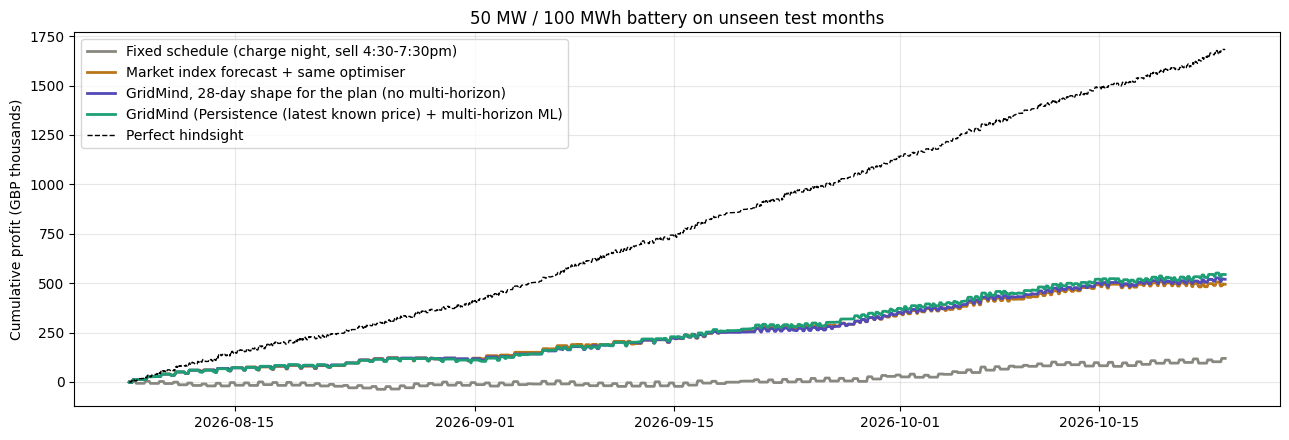

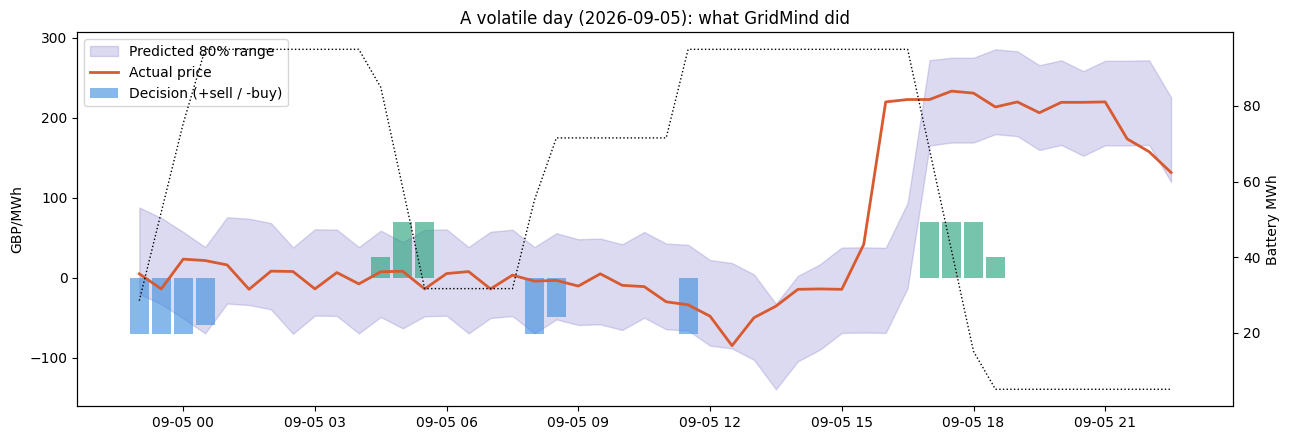

In [30]:
# ===== 15. Charts for the pitch =====
fig, ax = plt.subplots(figsize=(13, 4.5))
for (name, log), c in zip(runs.items(), ["#888780", "#BA7517", "#534AB7", "#1D9E75"]):
    ax.plot(log.startTime, log.pnl.cumsum() / 1000, label=name, color=c, lw=2)
ax.plot(ph_log.startTime, ph_log.pnl.cumsum() / 1000, label="Perfect hindsight", color="black", lw=1, ls="--")
ax.set_ylabel("Cumulative profit (GBP thousands)"); ax.set_title("50 MW / 100 MWh battery on unseen test months")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

gm = runs[GM].copy()
gm["price"] = test.price.values
for q in ("q10", "q50", "q90"): gm[q] = pred_test[q].values
gm["day"] = gm.startTime.dt.tz_convert("Europe/London").dt.date
day = gm.groupby("day")["price"].std().idxmax(); d = gm[gm.day == day]
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.fill_between(d.startTime, d.q10, d.q90, alpha=0.2, color="#534AB7", label="Predicted 80% range")
ax1.plot(d.startTime, d.price, color="#D85A30", lw=2, label="Actual price")
ax1.bar(d.startTime, d.action * d.price.abs().max() * 0.3, width=0.018,
        color=np.where(d.action > 0, "#1D9E75", "#378ADD"), alpha=0.6, label="Decision (+sell / -buy)")
ax1.set_ylabel("GBP/MWh"); ax1.legend(loc="upper left")
ax2 = ax1.twinx(); ax2.plot(d.startTime, d.soc, color="black", lw=1, ls=":"); ax2.set_ylabel("Battery MWh")
ax1.set_title(f"A volatile day ({day}): what GridMind did"); plt.tight_layout(); plt.show()

if BEST_KIND.startswith("lgb"):
    m = fit_cand(BEST_KIND, data.iloc[:i_test - GAP])
    imp = pd.Series(m.booster_.feature_importance("gain"), index=FEATURES).sort_values().tail(12)
    (imp / imp.sum()).plot.barh(figsize=(8, 4.5), color="#1D9E75", title="What the chosen model relies on")
    plt.tight_layout(); plt.show()

 Every model is retrained on a rolling basis as

1.   List item
2.   List item

it would be live; all choices
> (model, hyperparameters, trading settings) use validation months only; the test months are touched once.

## Explainability: why does GridMind predict and decide what it does?

LightGBM can split every single forecast exactly into contributions from each input (TreeSHAP values,
built into LightGBM). We translate inputs into plain English and show: what matters on average, *how* each driver
pushes the price, and one real decision explained step by step.

**What this does:** LightGBM can split each prediction exactly into contributions from each input (TreeSHAP). These helpers translate input names into plain English and pick the top drivers of any single forecast.

In [31]:
# ===== 15b. Explainability helpers (plain-English drivers) =====
NICE = {
    "price_lag2": "Latest published imbalance price", "price_lag3": "Imbalance price 1.5h ago",
    "price_lag4": "Imbalance price 2h ago", "price_lag6": "Imbalance price 3h ago",
    "price_lag48": "Price same time yesterday", "price_lag336": "Price same time last week",
    "price_mean_6": "Average price, last 3 hours", "price_std_6": "Price volatility, last 3 hours",
    "price_max_48": "Highest price, last 24 hours", "ref_price": "Typical price this week",
    "tod_profile": "Typical price at this time of day", "profile28": "Typical price at this time of day",
    "price_vs_ref": "Latest price vs typical", "niv_lag2": "Grid short/long (imbalance volume)",
    "niv_lag3": "Grid short/long 1.5h ago", "mkt_lag1": "Latest market index price",
    "mkt_lag2": "Market index price 1h ago", "mkt_minus_ref": "Market price vs typical",
    "wind_act_lag1": "Wind output now", "wind_fc": "Wind forecast", "wind_err_lag1": "Wind surprise (actual - forecast)",
    "wind_ramp_fc": "Expected change in wind", "demand_fc": "Demand forecast",
    "residual_fc": "Demand left after wind (forecast)", "gas_lag1": "Gas generation now",
    "gas_share_lag1": "Gas share of generation", "nuclear_lag1": "Nuclear output",
    "imports_lag1": "Imports via interconnectors", "gas_ramp_lag1": "Change in gas output (last hour)",
    "hour": "Time of day", "hour_sin": "Time of day", "hour_cos": "Time of day", "weekday": "Day of week",
    "weekend": "Weekend", "month": "Month", "is_peak": "Evening peak", "wind_fc_da": "Day-ahead wind forecast",
    "demand_fc_da": "Day-ahead demand forecast", "resid_da": "Day-ahead demand left after wind",
    "k": "Hours ahead", "dev_now": "Today's price vs typical", "wind_da_change": "Forecast wind change vs now",
}

def nice(c):
    if c.startswith("now_"): return NICE.get(c[4:], c[4:])
    if c.startswith("at_"):  return NICE.get(c[3:], c[3:])
    return NICE.get(c, c)

def contrib_table(model, X):
    # exact split of each prediction into per-input contributions (+ the model's average value)
    c = model.predict(X, pred_contrib=True)
    return pd.DataFrame(c[:, :-1], columns=list(X.columns), index=X.index), c[:, -1]

def grouped(con):
    # add up inputs that mean the same thing in plain English (e.g. the three time-of-day encodings)
    return con.T.groupby([nice(c) for c in con.columns], sort=False).sum().T

def top_drivers(model, X, n=3, scale=1.0):
    con, _ = contrib_table(model, X)
    g = grouped(con.iloc[[0]] * scale).iloc[0]
    return [(name, float(g[name])) for name in g.abs().sort_values(ascending=False).index[:n]]

EXPLAINABLE = ("lgb_price", "lgb_change")
def explain_next(kind, obj, X, explain_kind=None, explain_obj=None):
    k, m = (kind, obj) if kind in EXPLAINABLE else (explain_kind, explain_obj)
    if m is None: return [], ""
    note = "" if k == kind else " (read from the LightGBM model)"
    return top_drivers(m, X[FEATURES]), note

def drivers_text(drivers):
    return [f"{name}: {'+' if v >= 0 else '-'}GBP{abs(v):,.0f}/MWh" for name, v in drivers]

**What this does:** Average impact of each input on the forecasts, plus charts showing **how** the top drivers push the price up or down.

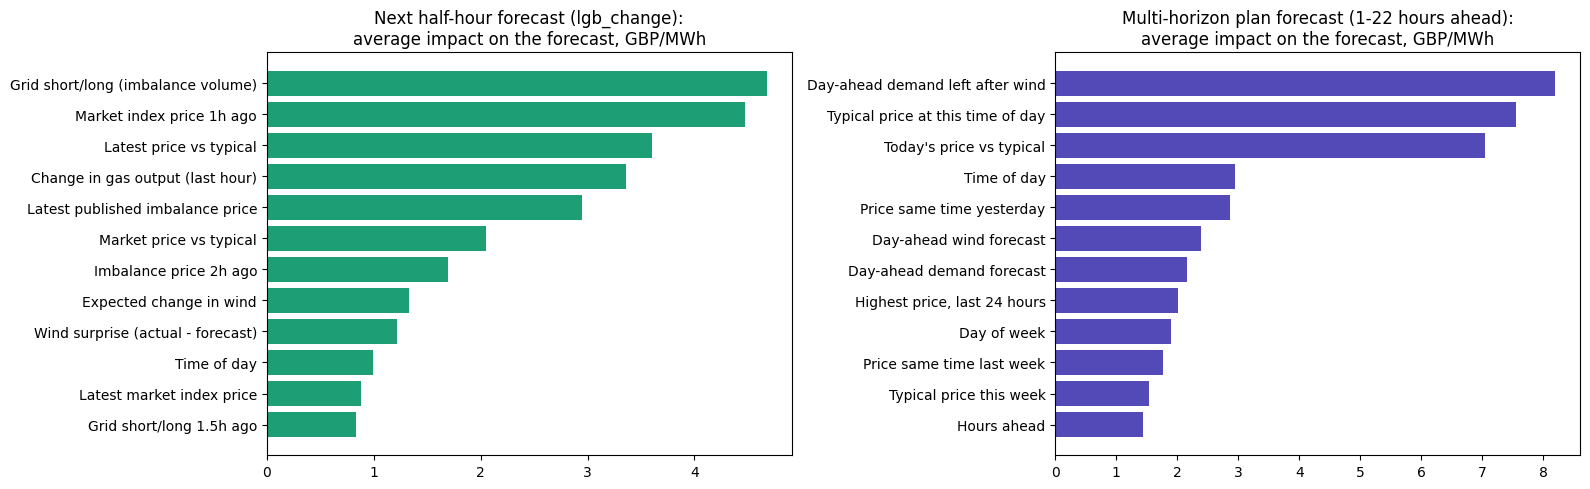

FINDINGS (how each top driver moves the forecast)
- Grid short/long (imbalance volume): higher values push the forecast UP (average impact GBP4.7/MWh, consistency 0.97)
- Market index price 1h ago: higher values push the forecast DOWN (average impact GBP4.5/MWh, consistency 0.87)
- Latest price vs typical: higher values push the forecast UP (average impact GBP3.6/MWh, consistency 0.98)
- Change in gas output (last hour): higher values push the forecast UP (average impact GBP3.4/MWh, consistency 0.94)


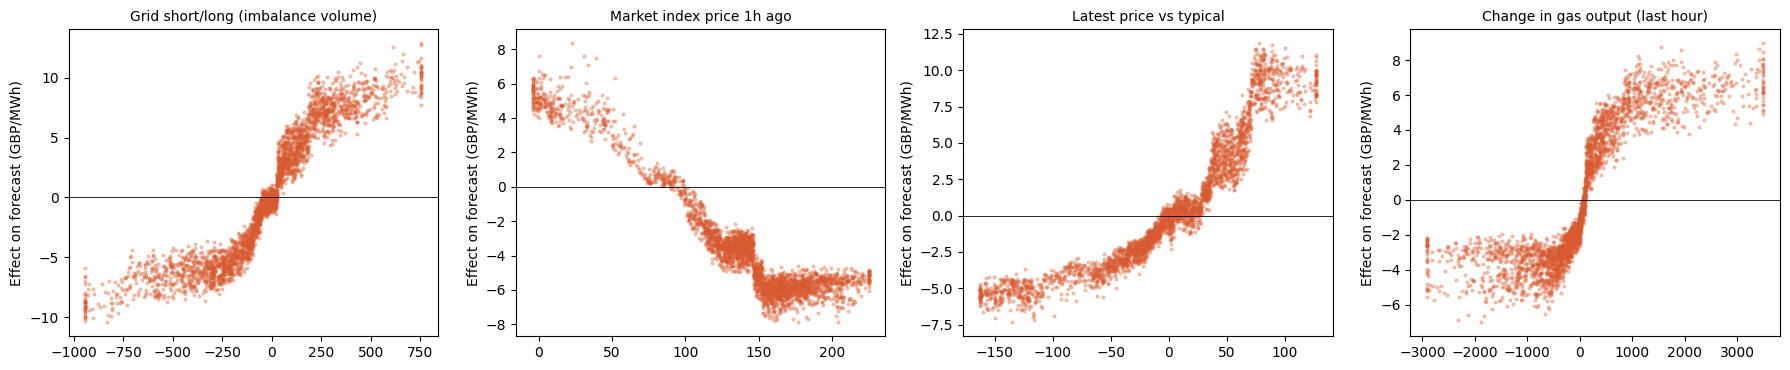

- Top drivers of the 22-hour plan: Day-ahead demand left after wind, Typical price at this time of day, Today's price vs typical


In [32]:
# ===== 15c. What drives the forecasts? (global explanation) =====
EXPLAIN_KIND = BEST_KIND if BEST_KIND in EXPLAINABLE else "lgb_change"
exp_model = fit_cand(EXPLAIN_KIND, data.iloc[:i_test - GAP])          # trained only on data before the test months
con_t, _ = contrib_table(exp_model, test[FEATURES])
IMPORTANCE = grouped(con_t).abs().mean().sort_values().tail(12)

mh_exp = fit_mh(FA_ALL, POS[:i_test:2], POS[i_test])
Xm, _, _, _ = mh_frame(FA_ALL, POS[i_test::6], np.array([1, 4, 12, 24, 43]))
con_m, _ = contrib_table(mh_exp, Xm)
IMPORTANCE_MH = grouped(con_m).abs().mean().sort_values().tail(12)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].barh(IMPORTANCE.index, IMPORTANCE.values, color="#1D9E75")
ax[0].set_title(f"Next half-hour forecast ({EXPLAIN_KIND}):\naverage impact on the forecast, GBP/MWh")
ax[1].barh(IMPORTANCE_MH.index, IMPORTANCE_MH.values, color="#534AB7")
ax[1].set_title("Multi-horizon plan forecast (1-22 hours ahead):\naverage impact on the forecast, GBP/MWh")
plt.tight_layout(); plt.show()

# How do the top drivers push the price? (dependence plots: input value vs its contribution)
raw_imp = con_t.abs().mean().sort_values(ascending=False)
top_raw = [c for c in raw_imp.index if c not in ("hour_sin", "hour_cos")][:4]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
samp = np.random.default_rng(0).choice(len(test), size=min(3000, len(test)), replace=False)
print("FINDINGS (how each top driver moves the forecast)")
for a_, c in zip(ax, top_raw):
    xv, cv = test[c].values[samp], con_t[c].values[samp]
    ok = np.isfinite(xv) & np.isfinite(cv)
    lo, hi = np.nanpercentile(xv[ok], [1, 99])
    a_.scatter(np.clip(xv[ok], lo, hi), cv[ok], s=4, alpha=0.3, color="#D85A30")
    a_.axhline(0, color="black", lw=0.6); a_.set_title(nice(c), fontsize=10); a_.set_ylabel("Effect on forecast (GBP/MWh)")
    r = pd.Series(xv[ok]).corr(pd.Series(cv[ok]), method="spearman")
    print(f"- {nice(c)}: higher values push the forecast {'UP' if r > 0 else 'DOWN'} "
          f"(average impact GBP{raw_imp[c]:.1f}/MWh, consistency {abs(r):.2f})")
plt.tight_layout(); plt.show()
print(f"- Top drivers of the 22-hour plan: {', '.join(IMPORTANCE_MH.sort_values(ascending=False).index[:3])}")

**What this does:** GridMind's most valuable sale in the test months, explained: how the forecast was built from its drivers, and the 22-hour plan the optimiser made at that moment.

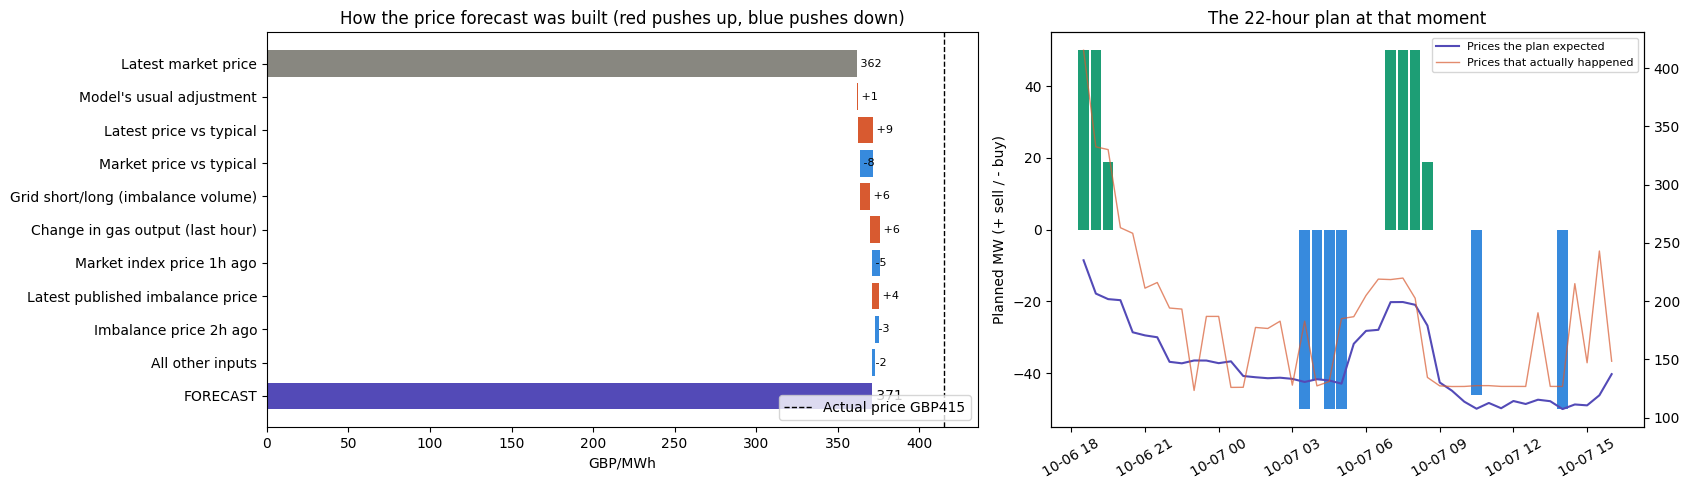

STORY FOR THE JUDGES: at Tue 06 Oct 18:30, with the battery at 68 MWh, GridMind sold at 50 MW.
- It forecast GBP371/MWh (actual: GBP415). Biggest reasons: Latest price vs typical: +GBP9/MWh; Market price vs typical: -GBP8/MWh; Grid short/long (imbalance volume): +GBP6/MWh.
- The plan expected to recharge later at about GBP123/MWh, so selling now was worth about GBP95/MWh after efficiency losses.


In [33]:
# ===== 15d. One real decision, explained step by step =====
gm_log = runs[GM].reset_index(drop=True)
i0 = int(np.nanargmax(gm_log.action.values * test.price.values))      # GridMind's most valuable sale on test
row = test.iloc[[i0]]
con_r, ev_r = contrib_table(exp_model, row[FEATURES])
g_r = grouped(con_r).iloc[0]
top = g_r.abs().sort_values(ascending=False).index[:7]
start_lbl, start = (("Latest market price", float(row.base.iloc[0])) if EXPLAIN_KIND != "lgb_price"
                    else ("Average price (model baseline)", 0.0))
steps = [(start_lbl, start)]
if EXPLAIN_KIND != "lgb_price": steps.append(("Model's usual adjustment", float(ev_r[0])))
else: steps[0] = (start_lbl, float(ev_r[0]))
steps += [(n_, float(g_r[n_])) for n_ in top] + [("All other inputs", float(g_r.drop(top).sum()))]
forecast = sum(v for _, v in steps)

fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 1]})
cum = 0.0
for k_, (lbl, v) in enumerate(steps):
    base_ = 0 if k_ == 0 else cum
    ax[0].barh(k_, v, left=base_, color="#888780" if k_ == 0 else ("#D85A30" if v >= 0 else "#378ADD"))
    ax[0].text(base_ + v, k_, f" {v:+,.0f}" if k_ else f" {v:,.0f}", va="center", fontsize=8)
    cum += v
ax[0].barh(len(steps), forecast, color="#534AB7"); ax[0].text(forecast, len(steps), f" {forecast:,.0f}", va="center")
ax[0].set_yticks(range(len(steps) + 1)); ax[0].set_yticklabels([l for l, _ in steps] + ["FORECAST"])
ax[0].axvline(row.price.iloc[0], color="black", ls="--", lw=1, label=f"Actual price GBP{row.price.iloc[0]:,.0f}")
ax[0].invert_yaxis(); ax[0].legend(loc="lower right"); ax[0].set_xlabel("GBP/MWh")
ax[0].set_title("How the price forecast was built (red pushes up, blue pushes down)")

# the plan the optimiser made at that moment
soc0 = SOC_START if i0 == 0 else float(gm_log.soc.iloc[i0 - 1])
prof = test.profile28.values
fut = prof[i0 + 1:i0 + HORIZON]
fut = np.concatenate([fut, np.full(HZ - len(fut), prof[i0])]) if len(fut) < HZ else fut
fut = np.where(np.isfinite(FUT_TEST[i0]), FUT_TEST[i0], fut)
path = np.concatenate([[p1_test[i0]], fut])
ch_, dis_ = lp_schedule(soc0, path + KAPPA, path - KAPPA)
tt = test.startTime.iloc[i0:i0 + HORIZON].dt.tz_convert("Europe/London")
m_ = len(tt)
ax[1].bar(tt, ((dis_ - ch_) / DT)[:m_], width=0.018, color=np.where((dis_ - ch_)[:m_] > 0, "#1D9E75", "#378ADD"))
ax[1].set_ylabel("Planned MW (+ sell / - buy)")
tw = ax[1].twinx(); tw.plot(tt, path[:m_], color="#534AB7", lw=1.5, label="Prices the plan expected")
tw.plot(tt, test.price.values[i0:i0 + m_], color="#D85A30", lw=1, alpha=0.7, label="Prices that actually happened")
tw.legend(fontsize=8, loc="upper right"); ax[1].tick_params(axis="x", rotation=30)
ax[1].set_title("The 22-hour plan at that moment"); plt.tight_layout(); plt.show()

t_ = row.startTime.iloc[0].tz_convert("Europe/London")
print(f"STORY FOR THE JUDGES: at {t_:%a %d %b %H:%M}, with the battery at {soc0:.0f} MWh, GridMind sold at "
      f"{gm_log.action.iloc[i0] * P_MAX_MW:.0f} MW.")
print(f"- It forecast GBP{forecast:,.0f}/MWh (actual: GBP{row.price.iloc[0]:,.0f}). Biggest reasons: "
      + "; ".join(drivers_text([(n_, float(g_r[n_])) for n_ in top[:3]])) + ".")
sell_later = path[1:][(dis_ - ch_)[1:] > 0.5]; buy_later = path[1:][(dis_ - ch_)[1:] < -0.5]
if len(buy_later):
    print(f"- The plan expected to recharge later at about GBP{buy_later.mean():,.0f}/MWh, so selling now was worth "
          f"about GBP{path[0] - buy_later.mean() / RTE:,.0f}/MWh after efficiency losses.")

## Proof: where the value comes from, whether it is real, and whether it is robust

Ablation: adds one component at a time (optimiser, next-half-hour forecast, multi-horizon plan) to show how much profit each adds.

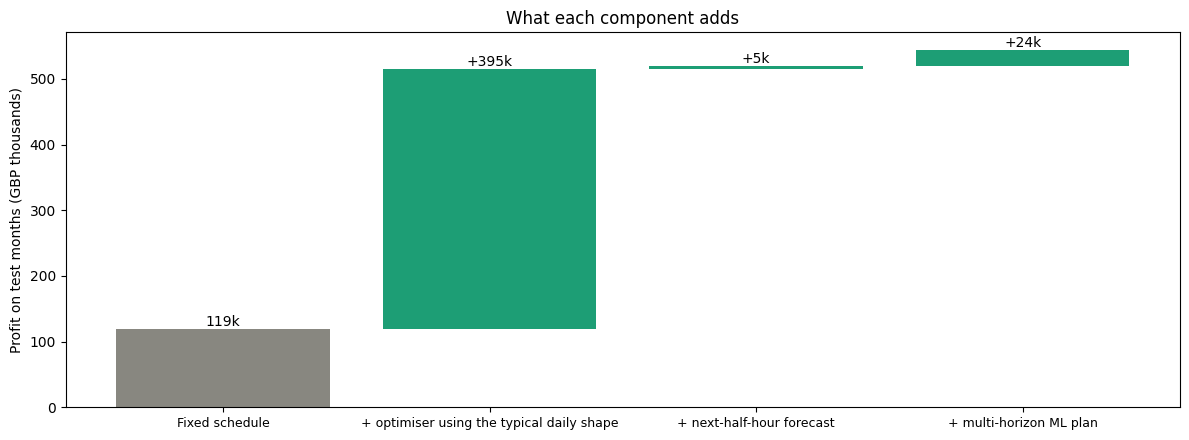

+ optimiser using the typical daily shape         +395,040 GBP
+ next-half-hour forecast                           +5,348 GBP
+ multi-horizon ML plan                            +23,940 GBP


In [34]:
#  15e. Where does the value come from? (ablation)
abl_prof = run_mpc(test, test.profile28.values, KAPPA0)               # optimiser with NO forecasts at all
FIXED = list(runs)[0]
ABLATION = [("Fixed schedule", runs[FIXED].pnl.sum()),
            ("+ optimiser using the typical daily shape", abl_prof.pnl.sum()),
            ("+ next-half-hour forecast", runs[NOMH].pnl.sum()),
            ("+ multi-horizon ML plan" + ("" if BETA > 0 else " (not selected)"), runs[GM].pnl.sum())]
fig, ax = plt.subplots(figsize=(12, 4.5))
prev = 0.0
for k_, (lbl, tot) in enumerate(ABLATION):
    inc = tot if k_ == 0 else tot - prev
    ax.bar(k_, inc / 1000, bottom=0 if k_ == 0 else prev / 1000,
           color="#888780" if k_ == 0 else ("#1D9E75" if inc >= 0 else "#D85A30"))
    ax.text(k_, max(tot, prev) / 1000, f"{'' if k_ == 0 else ('+' if inc >= 0 else '')}{inc / 1000:,.0f}k",
            ha="center", va="bottom")
    prev = tot
ax.set_xticks(range(len(ABLATION))); ax.set_xticklabels([l for l, _ in ABLATION], fontsize=9)
ax.set_ylabel("Profit on test months (GBP thousands)"); ax.set_title("What each component adds")
plt.tight_layout(); plt.show()
for (l0, a0), (l1, a1) in zip(ABLATION, ABLATION[1:]):
    print(f"{l1:45s} {a1 - a0:+12,.0f} GBP")

Block bootstrap: resamples whole weeks of daily profit differences 5,000 times to see whether GridMind's edge could be luck. If the 95% interval is above zero, it is very unlikely to be.

In [35]:
#  15f. Is the advantage real or luck? (block bootstrap over days)
def daily_pnl(log):
    return log.groupby(log.startTime.dt.tz_convert("Europe/London").dt.date)["pnl"].sum()

def block_bootstrap(diff, n_boot=5000, block=7, seed=0):
    # resample whole weeks, keeping day-to-day dependence, to get the uncertainty of the average daily difference
    rng = np.random.default_rng(seed); n_ = len(diff)
    starts = rng.integers(0, n_ - block + 1, size=(n_boot, int(np.ceil(n_ / block))))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n_]
    return diff[idx].mean(axis=1)

dg = daily_pnl(runs[GM])
SIGNIF = []
for name in [n_ for n_ in runs if n_ != GM and not (n_ == NOMH and BETA == 0)]:
    diff = (dg - daily_pnl(runs[name])).dropna().values
    boots = block_bootstrap(diff)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    SIGNIF.append({"GridMind vs": name, "Extra GBP per day": diff.mean(), "95% interval": f"{lo:,.0f} to {hi:,.0f}",
                   "Chance the edge is real": f"{(boots > 0).mean():.0%}", "Days GridMind was ahead": f"{(diff > 0).mean():.0%}"})
SIGNIF = pd.DataFrame(SIGNIF)
print(SIGNIF.to_string(index=False, formatters={"Extra GBP per day": "{:+,.0f}".format}))
print("\nRead it as: if the 95% interval is entirely above 0, the advantage is very unlikely to be luck.")

                                           GridMind vs Extra GBP per day   95% interval Chance the edge is real Days GridMind was ahead
       Fixed schedule (charge night, sell 4:30-7:30pm)            +5,440 3,452 to 7,094                    100%                     77%
                Market index forecast + same optimiser              +633  -164 to 1,143                     93%                     50%
GridMind, 28-day shape for the plan (no multi-horizon)              +307    -153 to 765                     90%                     58%

Read it as: if the 95% interval is entirely above 0, the advantage is very unlikely to be luck.


**What this does:** Reruns the backtest with different battery assumptions (efficiency, wear cost) to check the conclusion does not depend on one choice.

In [36]:
#  15g. Robustness: do the results hold under different battery assumptions?
t0 = time.time()
SCENARIOS = [("Less efficient (85%)", 0.85, 5.0), ("More efficient (92%)", 0.92, 5.0),
             ("No wear cost", 0.88, 0.0), ("High wear cost (GBP10/MWh)", 0.88, 10.0)]
_saved = (RTE, ETA, DEG_COST)
rows_ = [{"Scenario": "Base case (88%, GBP5 wear)", "Fixed": runs[FIXED].pnl.sum(),
          "Market + optimiser": runs["Market index forecast + same optimiser"].pnl.sum(), "GridMind": runs[GM].pnl.sum()}]
try:
    for lbl, rte_, deg_ in SCENARIOS:
        RTE, ETA, DEG_COST = rte_, rte_ ** 0.5, deg_
        rows_.append({"Scenario": lbl, "Fixed": run_fixed(test).pnl.sum(),
                      "Market + optimiser": run_mpc(test, blend(test, WF[MKT][i_test:], ALPHA_M), KAPPA_M)["pnl"].sum(),
                      "GridMind": run_mpc(test, p1_test, KAPPA, future=FUT_TEST if BETA > 0 else None)["pnl"].sum()})
finally:
    RTE, ETA, DEG_COST = _saved
ROBUST = pd.DataFrame(rows_)
ROBUST["GridMind vs fixed"] = [f"{(g / f - 1) * 100:+.0f}%" if f > 0 else "" for g, f in zip(ROBUST.GridMind, ROBUST.Fixed)]
ROBUST["GridMind wins"] = np.where(ROBUST.GridMind > ROBUST[["Fixed", "Market + optimiser"]].max(axis=1), "yes", "no")
print(ROBUST.to_string(index=False, formatters={c: "{:,.0f}".format for c in ("Fixed", "Market + optimiser", "GridMind")}))
print(f"({time.time() - t0:.0f}s)")

                  Scenario   Fixed Market + optimiser GridMind GridMind vs fixed GridMind wins
Base case (88%, GBP5 wear) 119,263            494,245  543,591             +356%           yes
      Less efficient (85%)  82,690            424,558  494,525             +498%           yes
      More efficient (92%) 166,268            555,520  612,973             +269%           yes
              No wear cost 151,979            537,806  594,053             +291%           yes
High wear cost (GBP10/MWh)  86,547            426,516  494,619             +472%           yes
(129s)


 Links uncertainty to decisions: a conservative operator raises the trading hurdle when the forecast range is wide. Compares margin, worst day and losing days with the balanced setting.

In [37]:
# 15h. Risk preference: a conservative mode that uses the forecast's uncertainty
# When the 80% range is wide, the forecast is unsure, so a conservative operator demands a bigger price gap
# before trading: hurdle = chosen hurdle + 25% of the half-width of the range at that moment.
half_width = ((pred_test.q90 - pred_test.q10) / 2).fillna(0).values
KAPPA_CONS = KAPPA + 0.25 * half_width
cons_log = run_mpc(test, p1_test, KAPPA_CONS, future=FUT_TEST if BETA > 0 else None)
RISK = pd.DataFrame([summary("Balanced (chosen settings)", runs[GM]),
                     summary("Conservative (bigger hurdle when uncertain)", cons_log)])
RISK["Typical hurdle (GBP/MWh)"] = [f"{KAPPA:.0f}", f"{np.median(KAPPA_CONS):.0f}"]
print(RISK.round(1).to_string(index=False))
print("Conservative trades less when the forecast is uncertain: compare margin, worst day and losing days.")

                                   Strategy  Profit (GBP)  GBP/MW/year  Cycles/day  Worst day (GBP) Losing days Typical hurdle (GBP/MWh)
                 Balanced (chosen settings)      543590.6      50874.5         1.5          -7895.3         21%                        5
Conservative (bigger hurdle when uncertain)      489679.9      45829.0         1.0          -7926.4         14%                       19
Conservative trades less when the forecast is uncertain: compare margin, worst day and losing days.


Retrains the chosen models on all data for live use, and measures the forecast range from the latest real errors.

In [38]:
#  16. Final model on ALL data, ready for live use
FINAL_OBJ = fit_cand(BEST_KIND, data)
res = (data.price.values - pred_all.q50.values)[i_test:]
res = res[~np.isnan(res)][-1440:]
RES_Q = (float(np.quantile(res, 0.10)), float(np.quantile(res, 0.90)))   # latest 30 days of real errors
FINAL_MH = fit_mh(FA_ALL, POS[::2], len(feat) + 3) if BETA > 0 else None
EXPLAIN_OBJ = FINAL_OBJ if EXPLAIN_KIND == BEST_KIND else fit_cand(EXPLAIN_KIND, data)   # for plain-English drivers
print(f"Final model: {BEST}, trained on {len(data):,} half-hours. Live 80% range = forecast "
      f"{RES_Q[0]:+.0f} / {RES_Q[1]:+.0f} GBP/MWh")
print("Multi-horizon model:", "trained on all data" if FINAL_MH is not None else "not used (did not win on validation)")

Final model: Persistence (latest known price), trained on 18,575 half-hours. Live 80% range = forecast -63 / +65 GBP/MWh
Multi-horizon model: trained on all data


 Downloads the last month of live data and produces the decision for the next half-hour: forecast, 22-hour plan, action, the reason, and the main drivers.

In [39]:
# 17. LIVE recommendation for the next half-hour
def live_plan(f, now, kind, obj, res_q, mh_model, alpha, beta, kappa, soc, explain_kind=None, explain_obj=None):
    # Shared by this notebook and the website: forecast -> 22-hour plan -> decision for the coming half-hour
    pos = np.flatnonzero((f["startTime"] > now).values)
    if len(pos) == 0: return None
    j = int(pos[0]); X = f.iloc[[j]]
    FA = arrays(f)
    typical = float(np.nanmedian(FA["price"][-336:]))
    idx = np.minimum(j + np.arange(HORIZON), len(f) - 1)
    prof = FA["profile28"][idx]; prof = np.where(np.isfinite(prof), prof, typical)
    q50 = float(predict_cand(kind, obj, X)[0])
    if not np.isfinite(q50): q50 = float(prof[0])           # newest inputs not published yet
    fut = prof[1:]
    if mh_model is not None and beta > 0:
        mh = predict_mh(mh_model, FA, np.array([j]))[0]
        fut = np.where(np.isfinite(mh), prof[1:] + beta * (mh - prof[1:]), prof[1:])
    path = np.concatenate([[prof[0] + alpha * (q50 - prof[0])], fut])
    ch, dis = lp_schedule(soc, path + kappa, path - kappa)
    a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP
    plan_mw = np.zeros(len(path)) if ch is None else (dis - ch) / DT
    act = "DISCHARGE (sell)" if a > 1e-6 else "CHARGE (buy)" if a < -1e-6 else "HOLD"
    sell_p = path[plan_mw > 0.5]; buy_p = path[plan_mw < -0.5]
    if a < -1e-6:
        why = (f"Expected price now (GBP{path[0]:,.0f}) is low compared with the later half-hours the plan sells in "
               f"(about GBP{sell_p.mean():,.0f})." if len(sell_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the lowest of the next 22 hours.")
    elif a > 1e-6:
        why = (f"Expected price now (GBP{path[0]:,.0f}) is high compared with the half-hours the plan recharges in "
               f"(about GBP{buy_p.mean():,.0f})." if len(buy_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the highest of the next 22 hours.")
    else:
        why = "Better opportunities are expected later, or the price gap is too small to cover losses and wear."
    try:
        drivers, dnote = explain_next(kind, obj, X, explain_kind, explain_obj)
    except Exception:
        drivers, dnote = [], ""
    return dict(drivers=drivers, drivers_note=dnote,
                time=X["startTime"].iloc[0].tz_convert("Europe/London"), q10=q50 + res_q[0], q50=q50,
                q90=q50 + res_q[1], typical=float(prof[0]), a=a, mw=abs(a) * P_MAX_MW, action=act, why=why,
                soc=soc, plan_times=pd.DatetimeIndex(f["startTime"].iloc[idx]), plan_price=path, plan_mw=plan_mw,
                recent=f.dropna(subset=["price"]).tail(96)[["startTime", "price"]])

def recommend(live_raw, now, current_soc=50.0, verbose=True):
    f = build_features(clean_data(live_raw, verbose=False))
    rec = live_plan(f, now, BEST_KIND, FINAL_OBJ, RES_Q, FINAL_MH, ALPHA, BETA, KAPPA, current_soc,
                    EXPLAIN_KIND, EXPLAIN_OBJ)
    if rec is None:
        if verbose: print("No upcoming period found")
        return None
    if verbose:
        print(f"\\nPeriod starting {rec['time']:%a %d %b %H:%M} (UK time)")
        print(f"Predicted imbalance price: GBP{rec['q50']:,.0f}/MWh  (80% range GBP{rec['q10']:,.0f} to GBP{rec['q90']:,.0f})")
        print(f"Typical price at this time of day: GBP{rec['typical']:,.0f}/MWh")
        print(f"Decision: {rec['action']} at {rec['mw']:.0f} MW   (battery at {current_soc:.0f} MWh)")
        print(f"Why: {rec['why']}")
        if rec["drivers"]:
            print(f"Main drivers of the forecast{rec['drivers_note']}: " + "; ".join(drivers_text(rec["drivers"])))
    return rec

_cache = {"t": 0.0, "raw": None}
def live_raw_data(max_age_s=900):
    if _cache["raw"] is None or time.time() - _cache["t"] > max_age_s:
        now = datetime.now(timezone.utc)
        prices, fuel, mid, windf, demf = fetch_all((now - timedelta(days=31)).date(), now.date())
        if prices.empty: raise RuntimeError("No live price data returned")
        _cache.update(t=time.time(), raw=combine(prices, fuel, mid, windf, demf, extend_periods=52))
    return _cache["raw"]

rec = recommend(live_raw_data(), datetime.now(timezone.utc), 50.0)

Fetching imbalance prices...
   prices 2026-10-25
Fetching fuel mix...
   fuel mix to 2026-10-25
Fetching market index...
Fetching wind forecasts...
   WINDFOR to 2026-10-25
Fetching demand forecasts...
   NDF to 2026-10-25
   prices    :    1,506 rows
   fuel      :    1,506 rows
   mid       :    1,505 rows
   wind fc   :   19,437 rows
   demand fc :   93,827 rows
\nPeriod starting Sun 25 Oct 09:00 (UK time)
Predicted imbalance price: GBP125/MWh  (80% range GBP62 to GBP189)
Typical price at this time of day: GBP125/MWh
Decision: DISCHARGE (sell) at 50 MW   (battery at 50 MWh)
Why: Expected price now (GBP125) is high compared with the half-hours the plan recharges in (about GBP97).
Main drivers of the forecast (read from the LightGBM model): Market index price 1h ago: +GBP7/MWh; Change in gas output (last hour): -GBP6/MWh; Imbalance price 2h ago: -GBP4/MWh


 Gemini rewrites the live decision, its reason and its main drivers into three plain-English sentences for a non-expert (falls back to the built-in reason if there is no key). The live decision is also logged to Tiger Data.

In [40]:
#  17b. Gemini explanation of the live decision + log it to Tiger Data
import json

def decision_facts(rec):
    mw, prices = np.asarray(rec["plan_mw"], float), np.asarray(rec["plan_price"], float)
    times = pd.DatetimeIndex(rec["plan_times"])
    times = times.tz_convert("Europe/London") if times.tz is not None else times.tz_localize("UTC").tz_convert("Europe/London")
    f = {"period_uk": f"{rec['time']:%a %d %b %H:%M}", "decision": rec["action"], "power_mw": round(rec["mw"]),
         "battery_mwh_now": round(rec["soc"]), "battery_capacity_mwh": E_MAX_MWH,
         "forecast_price_gbp_mwh": round(rec["q50"]), "forecast_80pct_range": [round(rec["q10"]), round(rec["q90"])],
         "typical_price_at_this_time": round(rec["typical"]), "built_in_reason": rec["why"],
         "planned_charge_times": [f"{t:%H:%M}" for t, m in zip(times, mw) if m < -1][:8],
         "planned_sell_times": [f"{t:%H:%M}" for t, m in zip(times, mw) if m > 1][:8],
         "round_trip_efficiency": RTE, "wear_cost_gbp_per_mwh": DEG_COST}
    if rec.get("drivers"):
        try:
            f["main_forecast_drivers"] = drivers_text(rec["drivers"])
        except Exception:
            pass
    return f

_gem = None
def explain_decision(rec):
    fallback = rec["why"]
    if not GEMINI_API_KEY:
        return fallback
    global _gem, GEMINI_MODEL
    try:
        _pip("google-genai", "google.genai")
        from google import genai
        _gem = _gem or genai.Client(api_key=GEMINI_API_KEY)
        prompt = ("You are an energy-trading analyst explaining a grid battery's decision to a non-expert judge. "
                  "Using ONLY these facts, write 3 short sentences: what the battery does now, why (price now vs later, "
                  "and the main drivers), and one risk. Use GBP and UK times. No bullet points, no invented numbers.\n\nFACTS: "
                  + json.dumps(decision_facts(rec), default=str))
        last = None
        for model in dict.fromkeys([GEMINI_MODEL, "gemini-flash-latest", "gemini-2.5-flash"]):
            try:
                r = _gem.models.generate_content(model=model, contents=prompt)
                if r.text:
                    GEMINI_MODEL = model
                    return r.text.strip()
            except Exception as e:
                last = e
        raise RuntimeError(last)
    except Exception as e:
        print("Gemini unavailable, using the built-in reason:", e)
        return fallback

if rec is not None:
    print(("GEMINI: " if GEMINI_API_KEY else "REASON: ") + explain_decision(rec))
    n_log = tiger_log([(rec["time"].tz_convert("UTC").to_pydatetime(), "live", float(rec["a"]), float(rec["soc"]),
                        None, float(rec["q50"]))])
    if n_log:
        print("Live decision logged to Tiger Data (strategy = 'live').")

REASON: Expected price now (GBP125) is high compared with the half-hours the plan recharges in (about GBP97).


**What this does:** All the headline numbers as ready-to-say sentences.

In [41]:
# ===== 19. Your pitch numbers =====
g = table.set_index("Strategy")
gm_row, fx_row, mk_row = g.loc[GM], g.iloc[0], g.iloc[1]
print(f"Data: {len(clean):,} half-hours of real GB market data ({clean.startTime.min():%b %Y} - {clean.startTime.max():%b %Y}).")
print(f"Compared {len(CANDIDATES)} forecasting approaches with fortnightly retraining; chose {BEST} by validation profit.")
print(f"On {days} unseen days, GridMind made a simulated margin of GBP{gm_row['Profit (GBP)']:,.0f} vs GBP{fx_row['Profit (GBP)']:,.0f} "
      f"for a fixed schedule ({gm_row['vs fixed']}), capturing {gm_row['% of max']:.0f}% of the theoretical maximum "
      f"(about GBP{gm_row['GBP/MW/year']:,.0f} per MW per year).")
nm_row = g.loc[NOMH]
print(f"Multi-horizon ML (22-hour plan from day-ahead wind & demand forecasts): plan error GBP{np.nanmean(mt_ml):.1f} vs "
      f"GBP{np.nanmean(mt_prof):.1f} for the 28-day shape; profit GBP{gm_row['Profit (GBP)'] - nm_row['Profit (GBP)']:+,.0f} "
      f"vs the same system without it" + ("" if BETA > 0 else " (not selected on validation, so not used)") + ".")
diff = gm_row['Profit (GBP)'] - mk_row['Profit (GBP)']
print(f"Versus using the market index price with the same optimiser: GBP{diff:+,.0f}.")
print(f"Losing days: {gm_row['Losing days']} vs {fx_row['Losing days']} for the fixed schedule.")
print(f"Uncertainty: the 80% forecast range held {COVERAGE_TEST:.0%} of actual test prices.")
print(f"Conservative mode: margin GBP{RISK.iloc[1]['Profit (GBP)']:,.0f}, losing days {RISK.iloc[1]['Losing days']}, "
      f"worst day GBP{RISK.iloc[1]['Worst day (GBP)']:,.0f}.")
print("All margins are simulated at Elexon imbalance prices (research prototype, not achievable revenue).")
sig_fx = SIGNIF.iloc[0]
print(f"Is it luck? vs the fixed schedule GridMind makes GBP{sig_fx['Extra GBP per day']:+,.0f}/day "
      f"(95% interval GBP{sig_fx['95% interval']}), chance the edge is real: {sig_fx['Chance the edge is real']}.")
print("Where the value comes from: " + "; ".join(f"{l1} {a1 - a0:+,.0f}" for (l0, a0), (l1, a1) in zip(ABLATION, ABLATION[1:])))
print(f"Robustness: GridMind beats both baselines in {int((ROBUST['GridMind wins'] == 'yes').sum())} of {len(ROBUST)} "
      "battery scenarios.")
print("Top drivers of the forecast: " + ", ".join(IMPORTANCE.sort_values(ascending=False).index[:3]) + ".")

Data: 18,624 half-hours of real GB market data (Sep 2025 - Oct 2026).
Compared 5 forecasting approaches with fortnightly retraining; chose Persistence (latest known price) by validation profit.
On 78 unseen days, GridMind made a simulated margin of GBP543,591 vs GBP119,263 for a fixed schedule (+356%), capturing 32% of the theoretical maximum (about GBP50,875 per MW per year).
Multi-horizon ML (22-hour plan from day-ahead wind & demand forecasts): plan error GBP41.6 vs GBP48.3 for the 28-day shape; profit GBP+23,940 vs the same system without it.
Versus using the market index price with the same optimiser: GBP+49,346.
Losing days: 21% vs 42% for the fixed schedule.
Uncertainty: the 80% forecast range held 77% of actual test prices.
Conservative mode: margin GBP489,680, losing days 14%, worst day GBP-7,926.
All margins are simulated at Elexon imbalance prices (research prototype, not achievable revenue).
Is it luck? vs the fixed schedule GridMind makes GBP+5,440/day (95% interval GBP3,4

**What this does:** Builds `gridmind_app.zip`: everything the Streamlit website needs (the app, the notebook's functions, the trained models, results, replay data and a live snapshot). Unzip it into a GitHub repository and deploy on Streamlit Community Cloud.

In [42]:
# ===== 20. Package the WEBSITE for GitHub + Streamlit Community Cloud (one zip) =====
import json, shutil, platform, importlib.metadata as md_
SITE = "gridmind_app"; os.makedirs(SITE, exist_ok=True)

joblib.dump({"best": BEST, "kind": BEST_KIND, "model": FINAL_OBJ, "features": FEATURES, "alpha": ALPHA,
             "kappa": KAPPA, "beta": BETA, "mh_model": FINAL_MH, "res_q": RES_Q,
             "explain_kind": EXPLAIN_KIND, "explain_model": EXPLAIN_OBJ}, f"{SITE}/gridmind_model.joblib")

def _daily_cum(log):
    s = log.set_index(pd.to_datetime(log.startTime, utc=True)).pnl.resample("D").sum().cumsum()
    return s
series = {k: _daily_cum(v) for k, v in runs.items()}
series["Perfect hindsight"] = _daily_cum(ph_log)
idx = series[GM].index
e_ = clean.dropna(subset=["price"]); loc_ = e_.startTime.dt.tz_convert("Europe/London")
shape = e_.assign(h=loc_.dt.hour + loc_.dt.minute / 60, we=loc_.dt.weekday >= 5).groupby(["we", "h"]).price.median().unstack(0)
g_ = table.set_index("Strategy"); gm_, fx_ = g_.loc[GM], g_.iloc[0]
results = {
    "meta": {"best": BEST, "n_candidates": len(CANDIDATES), "test_days": int(days), "rows": int(len(clean)),
             "start": f"{clean.startTime.min():%Y-%m-%d}", "end": f"{clean.startTime.max():%Y-%m-%d}",
             "coverage_test": COVERAGE_TEST, "alpha": ALPHA, "beta": BETA, "kappa": KAPPA,
             "rte": RTE, "deg_cost": DEG_COST},
    "pitch": [f"{len(clean):,} half-hours of real GB market data ({clean.startTime.min():%b %Y} to {clean.startTime.max():%b %Y})",
              f"Chosen model: {BEST}, picked from {len(CANDIDATES)} candidates by validation profit",
              f"Simulated margin GBP{gm_['Profit (GBP)']:,.0f} vs GBP{fx_['Profit (GBP)']:,.0f} for a fixed schedule ({gm_['vs fixed']}), at Elexon imbalance prices",
              f"Captured {gm_['% of max']:.0f}% of the theoretical maximum, about GBP{gm_['GBP/MW/year']:,.0f} per MW per year",
              f"Losing days: {gm_['Losing days']} vs {fx_['Losing days']} for the fixed schedule",
              f"22-hour plan error: GBP{np.nanmean(mt_ml):.1f} with multi-horizon ML vs GBP{np.nanmean(mt_prof):.1f} with the 28-day shape",
              f"80% forecast range held {COVERAGE_TEST:.0%} of actual test prices"],
    "backtest": json.loads(table.round(1).fillna("").to_json(orient="records")),
    "comparison": json.loads(comp.round(3).fillna("").to_json(orient="records")),
    "cumulative": {"dates": [f"{d:%Y-%m-%d}" for d in idx],
                   "series": {k: [float(x) for x in v.reindex(idx).ffill().fillna(0)] for k, v in series.items()}},
    "importance": {"names": list(IMPORTANCE.index), "values": [float(v) for v in IMPORTANCE.values]},
    "importance_mh": {"names": list(IMPORTANCE_MH.index), "values": [float(v) for v in IMPORTANCE_MH.values]},
    "ablation": [{"step": l, "profit": float(v)} for l, v in ABLATION],
    "significance": json.loads(SIGNIF.round(0).to_json(orient="records")),
    "robustness": json.loads(ROBUST.round(0).to_json(orient="records")),
    "risk": json.loads(RISK.round(0).to_json(orient="records")),
    "daily_shape": {"hour": [float(h) for h in shape.index], "weekday": [float(x) for x in shape[False]],
                    "weekend": [float(x) for x in shape[True]]},
}
json.dump(results, open(f"{SITE}/gridmind_results.json", "w"), indent=1)

# Replay data: every test half-hour, what GridMind and the fixed schedule did (lets the site replay any day offline)
pd.DataFrame({"startTime": test.startTime.dt.strftime("%Y-%m-%dT%H:%M:%SZ").values, "price": test.price.values,
              "q10": pred_test.q10.values, "q50": pred_test.q50.values, "q90": pred_test.q90.values,
              "gm_action": runs[GM].action.values, "gm_soc": runs[GM].soc.values, "gm_pnl": runs[GM].pnl.values,
              "fixed_action": runs[FIXED].action.values, "fixed_pnl": runs[FIXED].pnl.values}
             ).round(3).to_csv(f"{SITE}/gridmind_replay.csv", index=False)
# The 44 expected prices GridMind planned with at every test half-hour: lets the website re-run any day
# with different settings (Decision Lab) exactly as the backtest did
np.savez_compressed(f"{SITE}/gridmind_paths.npz",
                    paths=plan_paths(test, p1_test, FUT_TEST if BETA > 0 else None).astype("float32"),
                    half_width=half_width.astype("float32"))

# Snapshot of a live decision right now, so the website's first screen appears instantly
try:
    r_ = recommend(live_raw_data(), datetime.now(timezone.utc), 50.0, verbose=False)
except Exception as ex_:
    r_ = None; print("No live snapshot:", ex_)
if r_ is not None:
    iso_ = lambda ts: pd.Timestamp(ts).tz_convert("UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
    json.dump({"created": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"), "soc": 50.0,
               "time": iso_(r_["time"]), "action": r_["action"], "mw": float(r_["mw"]), "q10": float(r_["q10"]),
               "q50": float(r_["q50"]), "q90": float(r_["q90"]), "typical": float(r_["typical"]), "why": r_["why"],
               "drivers": [[n_, float(v_)] for n_, v_ in r_["drivers"]], "drivers_note": r_["drivers_note"],
               "plan_times": [iso_(t) for t in r_["plan_times"]], "plan_price": [float(x) for x in r_["plan_price"]],
               "plan_mw": [float(x) for x in r_["plan_mw"]],
               "recent_times": [iso_(t) for t in r_["recent"].startTime], "recent_price": [float(x) for x in r_["recent"].price]},
              open(f"{SITE}/gridmind_snapshot.json", "w"))
    print("Saved a live snapshot for the website's first screen")

open(f"{SITE}/gridmind_core.py", "w").write('# GridMind core functions (generated from the notebook; do not edit by hand)\n\nFEATURES = []   # set by app.py from the saved model\n\nimport sys, subprocess\n\nimport os, time, warnings\n\nfrom datetime import date, datetime, timedelta, timezone\n\nimport numpy as np\n\nimport pandas as pd\n\nimport requests\n\nimport lightgbm as lgb\n\nimport matplotlib.pyplot as plt\n\nfrom scipy.optimize import linprog, milp, LinearConstraint, Bounds\n\nfrom scipy import sparse\n\nimport joblib\n\nP_MAX_MW   = 50.0\n\nE_MAX_MWH  = 100.0\n\nSOC_MIN, SOC_MAX = 5.0, 95.0\n\nRTE        = 0.88\n\nETA        = RTE ** 0.5\n\nDEG_COST   = 5.0\n\nDT         = 0.5\n\nE_STEP     = P_MAX_MW * DT\n\nSOC_START  = 50.0\n\nTUNE_MODELS = True\n\nBASE = "https://data.elexon.co.uk/bmrs/api/v1"\n\nS = requests.Session()\n\ndef get(url, params=None, retries=3):\n    err = None\n    for _ in range(retries):\n        try:\n            r = S.get(url, params=params, timeout=90)\n            if r.status_code == 429:\n                time.sleep(5); continue\n            r.raise_for_status()\n            js = r.json()\n            return js["data"] if isinstance(js, dict) and "data" in js else js\n        except Exception as e:\n            err = e; time.sleep(2)\n    print(f"   ! request failed: {url} {params or \'\'} -> {err}")\n    return []\n\ndef chunks(start, end, days=7):\n    d = start\n    while d <= end:\n        e = min(d + timedelta(days=days - 1), end)\n        yield d, e\n        d = e + timedelta(days=1)\n\ndef iso(d):  # date -> ISO midnight UTC\n    return f"{d.isoformat()}T00:00:00Z"\n\ndef fetch_prices(start, end):\n    # Imbalance (system) price per half-hour -> our TARGET\n    rows = []\n    d = start\n    while d <= end:\n        rows += get(f"{BASE}/balancing/settlement/system-prices/{d.isoformat()}")\n        print(f"   prices {d}", end="\\r"); d += timedelta(days=1)\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df = df[["startTime", "systemSellPrice", "netImbalanceVolume"]].rename(\n        columns={"systemSellPrice": "price", "netImbalanceVolume": "niv"})\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    return df.drop_duplicates("startTime", keep="last")\n\ndef fetch_fuel(start, end):\n    # Generation by fuel type every 5 min -> half-hourly averages\n    rows = []\n    for a, b in chunks(start, end):\n        rows += get(f"{BASE}/datasets/FUELINST/stream",\n                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})\n        print(f"   fuel mix to {b}", end="\\r")\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True).dt.floor("30min")\n    return (df.pivot_table(index="startTime", columns="fuelType", values="generation", aggfunc="mean")\n              .add_prefix("gen_").reset_index())\n\ndef fetch_mid(start, end):\n    # Market Index Data: wholesale price per half-hour (volume-weighted across providers)\n    rows = []\n    for a, b in chunks(start, end):\n        rows += get(f"{BASE}/datasets/MID", {"from": iso(a), "to": iso(b + timedelta(days=1))})\n    df = pd.DataFrame(rows)\n    if df.empty: return df\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    df["pv"] = df["price"] * df["volume"]\n    g = df.groupby("startTime")[["pv", "volume", "price"]].agg({"pv": "sum", "volume": "sum", "price": "mean"})\n    g["market_price"] = np.where(g["volume"] > 0, g["pv"] / g["volume"].replace(0, np.nan), g["price"])\n    return g[["market_price"]].reset_index()\n\ndef fetch_forecast(dataset, start, end, value_col):\n    # Every published forecast (with publishTime) so we can use only what was known at the time\n    rows = []\n    for a, b in chunks(start - timedelta(days=2), end):\n        rows += get(f"{BASE}/datasets/{dataset}/stream",\n                    {"publishDateTimeFrom": iso(a), "publishDateTimeTo": iso(b + timedelta(days=1))})\n        print(f"   {dataset} to {b}", end="\\r")\n    print()\n    df = pd.DataFrame(rows)\n    if df.empty or value_col not in df.columns: return pd.DataFrame()\n    df = df[["publishTime", "startTime", value_col]].rename(columns={value_col: "value"})\n    df["publishTime"] = pd.to_datetime(df["publishTime"], utc=True)\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    return df.dropna()\n\ndef fetch_all(start, end):\n    print("Fetching imbalance prices..."); prices = fetch_prices(start, end)\n    print("Fetching fuel mix...");         fuel   = fetch_fuel(start, end)\n    print("Fetching market index...");     mid    = fetch_mid(start, end)\n    print("Fetching wind forecasts...");   windf  = fetch_forecast("WINDFOR", start, end, "generation")\n    print("Fetching demand forecasts..."); demf   = fetch_forecast("NDF", start, end, "demand")\n    for name, d in [("prices", prices), ("fuel", fuel), ("mid", mid), ("wind fc", windf), ("demand fc", demf)]:\n        print(f"   {name:10s}: {len(d):>8,} rows" + ("   <-- EMPTY (feature will be skipped)" if d.empty else ""))\n    return prices, fuel, mid, windf, demf\n\nFC_LEAD = pd.Timedelta("60min")\n\nDA_LEAD = pd.Timedelta("24h")\n\ndef asat(fc, times, lead=FC_LEAD, hourly=False):\n    # For each target time, the latest forecast for that time published at least `lead` earlier\n    if fc.empty: return pd.Series(np.nan, index=times)\n    t = pd.DataFrame({"startTime": times})\n    t["key"] = t["startTime"].dt.floor("60min") if hourly else t["startTime"]\n    t["cutoff"] = t["startTime"] - lead\n    f = fc.rename(columns={"startTime": "key"}).sort_values("publishTime")\n    out = pd.merge_asof(t.sort_values("cutoff"), f, left_on="cutoff", right_on="publishTime",\n                        by="key", direction="backward")\n    return out.set_index("startTime")["value"].reindex(times)\n\ndef combine(prices, fuel, mid, windf, demf, extend_periods=0):\n    t0 = prices["startTime"].min()\n    t1 = prices["startTime"].max() + pd.Timedelta(minutes=30) * extend_periods\n    grid = pd.DataFrame({"startTime": pd.date_range(t0, t1, freq="30min", tz="UTC")})\n    df = grid.merge(prices, on="startTime", how="left")\n    for extra in (fuel, mid):\n        if len(extra): df = df.merge(extra, on="startTime", how="left")\n    hourly = (not windf.empty) and (windf["startTime"].dt.minute == 0).all()\n    df["wind_fc"]   = asat(windf, df["startTime"], hourly=hourly).values\n    df["demand_fc"] = asat(demf, df["startTime"]).values\n    df["wind_fc_da"]   = asat(windf, df["startTime"], lead=DA_LEAD, hourly=hourly).values\n    df["demand_fc_da"] = asat(demf, df["startTime"], lead=DA_LEAD).values\n    return df\n\nFILL_LIMIT = 4\n\ndef clean_data(raw, verbose=True):\n    df = raw.copy()\n    df["startTime"] = pd.to_datetime(df["startTime"], utc=True)\n    n_dup = df.startTime.duplicated().sum()\n    df = df.drop_duplicates("startTime", keep="last").sort_values("startTime")\n    grid = pd.date_range(df.startTime.min(), df.startTime.max(), freq="30min", tz="UTC")\n    n_gap = len(grid) - len(df)\n    df = df.set_index("startTime").reindex(grid).rename_axis("startTime").reset_index()\n\n    # 1. drop columns with no information (e.g. coal after 2024) or mostly missing\n    num = df.select_dtypes("number").columns\n    drop = [c for c in num if c not in ("price", "niv", "market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da")\n            and (df[c].nunique(dropna=True) <= 1 or df[c].isna().mean() > 0.5)]\n    df = df.drop(columns=drop)\n\n    # 2. physically impossible values\n    gen_cols = [c for c in df.columns if c.startswith("gen_")]\n    clip_cols = [c for c in gen_cols if not c.startswith("gen_INT") and c != "gen_PS"]   # imports/pumping can be negative\n    n_clip = int(sum((df[c] < 0).sum() for c in clip_cols))\n    for c in clip_cols: df[c] = df[c].clip(lower=0)\n    n_bad_fc = 0\n    if "wind_fc" in df:   n_bad_fc += int((df.wind_fc < 0).sum());   df.loc[df.wind_fc < 0, "wind_fc"] = np.nan\n    if "wind_fc_da" in df: n_bad_fc += int((df.wind_fc_da < 0).sum()); df.loc[df.wind_fc_da < 0, "wind_fc_da"] = np.nan\n    if "demand_fc_da" in df: n_bad_fc += int((df.demand_fc_da <= 0).sum()); df.loc[df.demand_fc_da <= 0, "demand_fc_da"] = np.nan\n    if "demand_fc" in df: n_bad_fc += int((df.demand_fc <= 0).sum()); df.loc[df.demand_fc <= 0, "demand_fc"] = np.nan\n\n    # 3. fill short feature gaps from the PAST only (never the target)\n    feat_cols = gen_cols + [c for c in ("market_price", "wind_fc", "demand_fc", "wind_fc_da", "demand_fc_da") if c in df]\n    before = int(df[feat_cols].isna().sum().sum())\n    df[feat_cols] = df[feat_cols].ffill(limit=FILL_LIMIT)\n    n_fill = before - int(df[feat_cols].isna().sum().sum())\n\n    if verbose:\n        print(f"Removed {n_dup} duplicate rows; added {n_gap} empty rows for missing half-hours (kept as gaps)")\n        print(f"Dropped uninformative columns: {drop or \'none\'}")\n        print(f"Clipped {n_clip} negative generation values to 0; removed {n_bad_fc} impossible forecasts")\n        print(f"Forward-filled {n_fill:,} short feature gaps (<= {FILL_LIMIT * 30} min). Prices left untouched.")\n        print(f"Half-hours with a usable price: {df.price.notna().sum():,} of {len(df):,}")\n    return df\n\ndef col(df, name):\n    return df[name] if name in df.columns else pd.Series(np.nan, index=df.index)\n\ndef build_features(raw):\n    df = raw.sort_values("startTime").reset_index(drop=True).copy()\n    local = df["startTime"].dt.tz_convert("Europe/London")\n    gen = [c for c in df.columns if c.startswith("gen_")]\n    df["gas"]     = col(df, "gen_CCGT").fillna(0) + col(df, "gen_OCGT").fillna(0)\n    df["imports"] = df[[c for c in gen if c.startswith("gen_INT")]].sum(axis=1, min_count=1) if gen else np.nan\n    df["total_gen"] = df[gen].sum(axis=1, min_count=1) if gen else np.nan\n    df["wind_act"]  = col(df, "gen_WIND")\n\n    f = pd.DataFrame({"startTime": df["startTime"], "price": col(df, "price")})\n    p = df["price"]\n    for k in (2, 3, 4, 6, 48, 336):                      # 48 = same time yesterday, 336 = last week\n        f[f"price_lag{k}"] = p.shift(k)\n    known = p.shift(2)\n    f["price_mean_6"]  = known.rolling(6, min_periods=3).mean()\n    f["price_std_6"]   = known.rolling(6, min_periods=3).std()\n    f["price_max_48"]  = known.rolling(48, min_periods=12).max()\n    f["ref_price"]     = known.rolling(336, min_periods=48).median()   # 7-day typical price\n    # typical price at this time of day over the last 7 days (all already published)\n    f["tod_profile"]   = pd.concat([p.shift(48 * k) for k in range(1, 8)], axis=1).median(axis=1)\n    # smoother 28-day daily shape used for planning ahead (still only published prices)\n    f["profile28"] = (pd.concat([p.shift(48 * k) for k in range(1, 29)], axis=1).median(axis=1)\n                        .rolling(5, center=True, min_periods=1).median())\n    f["price_vs_ref"]  = f["price_lag2"] - f["ref_price"]\n    f["niv_lag2"]      = col(df, "niv").shift(2)\n    f["niv_lag3"]      = col(df, "niv").shift(3)\n    f["mkt_lag1"]      = col(df, "market_price").shift(1)\n    f["mkt_lag2"]      = col(df, "market_price").shift(2)\n    f["mkt_minus_ref"] = f["mkt_lag1"] - f["ref_price"]\n    f["wind_act_lag1"] = df["wind_act"].shift(1)\n    f["wind_fc"]       = col(df, "wind_fc")\n    f["wind_err_lag1"] = df["wind_act"].shift(1) - col(df, "wind_fc").shift(1)   # +: more wind than expected\n    f["wind_ramp_fc"]  = col(df, "wind_fc") - df["wind_act"].shift(1)            # expected change in wind\n    f["demand_fc"]     = col(df, "demand_fc")\n    f["residual_fc"]   = col(df, "demand_fc") - col(df, "wind_fc")                      # demand left for gas etc.\n    f["gas_lag1"]      = df["gas"].shift(1)\n    f["gas_share_lag1"] = (df["gas"] / df["total_gen"]).shift(1)\n    f["nuclear_lag1"]  = col(df, "gen_NUCLEAR").shift(1)\n    f["imports_lag1"]  = df["imports"].shift(1)\n    f["gas_ramp_lag1"] = df["gas"].shift(1) - df["gas"].shift(3)\n    hr = local.dt.hour + local.dt.minute / 60\n    f["hour"] = hr\n    f["hour_sin"], f["hour_cos"] = np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24)\n    f["weekday"] = local.dt.weekday\n    f["weekend"] = (local.dt.weekday >= 5).astype(int)\n    f["month"]   = local.dt.month\n    f["is_peak"] = ((hr >= 16) & (hr < 19.5)).astype(int)\n    # latest market price: the anchor for change models. Live, the newest prices may not be published yet,\n    # so fall back to the most recent known value (forward-fill uses only the past)\n    f["base"] = f["mkt_lag1"].fillna(f["price_lag2"]).ffill()\n    # day-ahead forecasts (published >= 24h before each half-hour): inputs to the multi-horizon model\n    f["wind_fc_da"]   = col(df, "wind_fc_da")\n    f["demand_fc_da"] = col(df, "demand_fc_da")\n    f["resid_da"]     = f["demand_fc_da"] - f["wind_fc_da"]\n    f["local_date"] = local.dt.date\n    return f\n\ndef step(soc, action, price):\n    # action in [-1, 1]: + = discharge, - = charge (fraction of max power)\n    if action > 1e-9:\n        out = min(action * E_STEP, (soc - SOC_MIN) * ETA)\n        return soc - out / ETA, 0.0, out, out * price - DEG_COST * out\n    if action < -1e-9:\n        inn = min(-action * E_STEP, (SOC_MAX - soc) / ETA)\n        return soc + inn * ETA, inn, 0.0, -inn * price\n    return soc, 0.0, 0.0, 0.0\n\ndef lp_schedule(soc0, p_buy, p_sell, end_soc=SOC_START, end_equal=False, end_free=False):\n    # Best charge/discharge plan for given buy/sell price paths.\n    # Variables per half-hour: charge c, discharge d (grid MWh) and battery level s.\n    # A battery cannot charge and discharge in the same half-hour. With positive prices doing both never pays,\n    # but at NEGATIVE prices a plain linear program would do both to "burn" energy as losses and get paid,\n    # so those half-hours get an on/off switch u (u=1: may charge, u=0: may discharge): a small mixed-integer program.\n    p_buy, p_sell = np.asarray(p_buy, float), np.asarray(p_sell, float)\n    n = len(p_buy)\n    neg = np.flatnonzero(p_buy < 0); m = len(neg); nv = 3 * n + m\n    cost = np.concatenate([p_buy, -p_sell + DEG_COST, np.zeros(n), np.zeros(m)])\n    I = sparse.identity(n, format="csr")\n    prev = sparse.diags([np.ones(n - 1)], [-1], shape=(n, n), format="csr")\n    # level now - level before - ETA * charge + discharge / ETA = 0   (level before the first step = soc0)\n    dyn = sparse.hstack([-ETA * I, (1 / ETA) * I, I - prev, sparse.csr_matrix((n, m))], format="csr")\n    b0 = np.zeros(n); b0[0] = soc0\n    cons = [LinearConstraint(dyn, b0, b0)]\n    last = sparse.csr_matrix(([1.0], ([0], [3 * n - 1])), shape=(1, nv))\n    if end_equal:\n        cons.append(LinearConstraint(last, end_soc, end_soc))\n    elif not end_free:\n        cons.append(LinearConstraint(last, min(end_soc, SOC_MAX), np.inf))   # end at least this full\n    if m:\n        r = np.arange(m)\n        sw = sparse.csr_matrix((np.full(m, E_STEP), (r, 3 * n + r)), shape=(m, nv))\n        cons.append(LinearConstraint(sparse.csr_matrix((np.ones(m), (r, neg)), shape=(m, nv)) - sw, -np.inf, 0))      # c <= 25 u\n        cons.append(LinearConstraint(sparse.csr_matrix((np.ones(m), (r, n + neg)), shape=(m, nv)) + sw, -np.inf, E_STEP))  # d <= 25 (1-u)\n    lb = np.concatenate([np.zeros(2 * n), np.full(n, SOC_MIN), np.zeros(m)])\n    ub = np.concatenate([np.full(2 * n, E_STEP), np.full(n, SOC_MAX), np.ones(m)])\n    res = milp(cost, constraints=cons, bounds=Bounds(lb, ub),\n               integrality=np.concatenate([np.zeros(3 * n), np.ones(m)]))\n    if not res.success: return None, None\n    return res.x[:n], res.x[n:2 * n]\n\nHORIZON = 44\n\ndef plan_paths(df, p1, future=None):\n    # The 44 expected prices the planner uses at each half-hour:\n    #   step 1  = p1, our forecast for the coming half-hour\n    #   steps 2..44 = the multi-horizon forecast when given (`future`, rows x 43), else the typical 28-day shape\n    prof = df["profile28"].values\n    paths = np.empty((len(df), HORIZON))\n    for i in range(len(df)):\n        fut = prof[i + 1:i + HORIZON]\n        if len(fut) < HORIZON - 1:\n            fut = np.concatenate([fut, np.full(HORIZON - 1 - len(fut), prof[i])])\n        if future is not None:\n            fz = future[i]\n            fut = np.where(np.isfinite(fz), fz, fut)\n        paths[i, 0], paths[i, 1:] = p1[i], fut\n    return paths\n\ndef run_mpc(df, p1, kappa=0.0, soc=SOC_START, future=None):\n    # Rolling optimisation (model predictive control): every half-hour, plan the next 22h,\n    # carry out only the first step at the real price, then re-plan with fresh information.\n    #   kappa = trading hurdle (GBP/MWh): buying looks dearer and selling cheaper by kappa, so the plan\n    #           ignores spreads smaller than forecast noise. A number, or one value per half-hour.\n    actual, paths = df["price"].values, plan_paths(df, p1, future)\n    log = []\n    for i in range(len(df)):\n        k = kappa[i] if np.ndim(kappa) else kappa\n        ch, dis = lp_schedule(soc, paths[i] + k, paths[i] - k)\n        a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP\n        soc, e_in, e_out, pnl = step(soc, a, actual[i])\n        log.append((df["startTime"].iloc[i], a, soc, e_in, e_out, pnl))\n    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])\n\ndef blend(df, forecast, alpha):\n    # Trust the forecast in proportion to its proven skill: alpha=1 uses it fully, 0 ignores it\n    prof = df["profile28"].values\n    return prof + alpha * (np.asarray(forecast) - prof)\n\ndef run_fixed(df, soc=SOC_START):\n    # What many simple sites do: charge overnight, discharge at the evening peak\n    log = []\n    for t, h, p in zip(df["startTime"], df["hour"], df["price"]):\n        a = -1.0 if 1 <= h < 4.5 else 1.0 if 16.5 <= h < 19.5 else 0.0\n        soc, e_in, e_out, pnl = step(soc, a, p)\n        log.append((t, a, soc, e_in, e_out, pnl))\n    return pd.DataFrame(log, columns=["startTime", "action", "soc", "e_in", "e_out", "pnl"])\n\ndef perfect_hindsight(df, soc0=SOC_START):\n    # Upper bound: the best possible schedule over the WHOLE period if every price were known in advance.\n    # Same start as the other strategies, charge carried across days, free to end at any level.\n    p = df["price"].values\n    ch, dis = lp_schedule(soc0, p, p, end_free=True)\n    if ch is None: return 0.0, pd.DataFrame(columns=["startTime", "pnl"])\n    pnl = p * dis - p * ch - DEG_COST * dis\n    return float(pnl.sum()), pd.DataFrame({"startTime": df["startTime"].values, "pnl": pnl})\n\nCHUNK, GAP = 672, 2\n\nLGB_PARAMS = dict(n_estimators=500, learning_rate=0.04, num_leaves=31, min_child_samples=50,\n                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)\n\ndef recency_weights(times, half_life_days):\n    # weight 1 for the newest row, 0.5 for a row half_life_days older, and so on\n    if not half_life_days: return None\n    age = (times.max() - times).dt.total_seconds().values / 86400\n    return 0.5 ** (age / half_life_days)\n\ndef fit_cand(kind, df):\n    # the two simple baselines need no training\n    if kind in ("persist", "market"): return None\n    w = recency_weights(df.startTime, LGB_HALF_LIFE)\n    # LightGBM with "l1" loss = predicts the median, so rare price spikes don\'t dominate training\n    if kind == "lgb_price":                      # learns the price directly\n        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price, sample_weight=w)\n    if kind in ("lgb_change", "ens"):            # learns the CHANGE from the latest market price (adapts to price level)\n        return lgb.LGBMRegressor(objective="l1", **LGB_PARAMS).fit(df[FEATURES], df.price - df.base, sample_weight=w)\n    raise ValueError(kind)\n\ndef predict_cand(kind, obj, df):\n    if kind == "persist":    return df.price_lag2.values                     # "price stays as last published"\n    if kind == "market":     return df.base.values                           # "price = latest market price"\n    if kind == "lgb_price":  return obj.predict(df[FEATURES])\n    if kind == "lgb_change": return df.base.values + obj.predict(df[FEATURES])\n    if kind == "ens":        return 0.5 * (df.price_lag2.values + df.base.values + obj.predict(df[FEATURES]))   # average of the two views\n    raise ValueError(kind)\n\ndef walk_forward(kind):\n    out = np.full(n, np.nan)\n    for s in range(WF_START, n, CHUNK):\n        e_ = min(s + CHUNK, n)\n        obj = fit_cand(kind, data.iloc[:s - GAP])\n        out[s:e_] = predict_cand(kind, obj, data.iloc[s:e_])\n    return out\n\ndef band(q50, window=1440):\n    # 80% range from the last 30 days of REAL out-of-sample errors (only errors already known)\n    res = pd.Series(data.price.values - q50).shift(GAP)\n    lo = res.rolling(window, min_periods=200).quantile(0.10).values\n    hi = res.rolling(window, min_periods=200).quantile(0.90).values\n    return pd.DataFrame({"q10": q50 + lo, "q50": q50, "q90": q50 + hi}, index=data.index)\n\nHZ = HORIZON - 1\n\nNOW_COLS = ["price_lag2", "price_mean_6", "price_std_6", "price_max_48", "ref_price", "niv_lag2",\n            "wind_err_lag1", "wind_act_lag1", "gas_lag1", "mkt_lag1"]\n\nAT_COLS = ["hour", "weekday", "weekend", "month", "is_peak", "profile28", "tod_profile", "price_lag48",\n           "price_lag336", "wind_fc_da", "demand_fc_da", "resid_da"]\n\nMH_KS_TRAIN = np.array([1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 28, 32, 38, 43])\n\nMH_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=63, min_child_samples=100,\n                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)\n\ndef arrays(f):\n    return {c: pd.to_numeric(f[c], errors="coerce").values.astype(float) for c in f.columns\n            if c not in ("startTime", "local_date")}\n\ndef mh_frame(FA, js, ks):\n    # one row per (decision half-hour j, steps ahead k); target = price at j+k minus its typical value\n    N = len(FA["price"])\n    J = np.repeat(np.asarray(js), len(ks)); K = np.tile(np.asarray(ks), len(js))\n    valid = (J + K) < N\n    T = np.minimum(J + K, N - 1)\n    nan = np.full(len(J), np.nan)\n    X = {f"now_{c}": FA.get(c, nan)[J] if c in FA else nan for c in NOW_COLS}\n    X.update({f"at_{c}": FA[c][T] if c in FA else nan for c in AT_COLS})\n    X["k"] = K\n    X["dev_now"] = FA["base"][J] - FA["profile28"][J]\n    X["wind_da_change"] = (FA["wind_fc_da"][T] if "wind_fc_da" in FA else nan) - FA["wind_act_lag1"][J]\n    y = FA["price"][T] - FA["profile28"][T]\n    return pd.DataFrame(X), y, T, valid\n\ndef fit_mh(FA, train_js, cutoff_pos, params=None, half_life=-1):\n    X, y, T, valid = mh_frame(FA, train_js, MH_KS_TRAIN)\n    ok = valid & (T <= cutoff_pos - 3) & np.isfinite(y)       # only targets already published at cutoff\n    hl = MH_HALF_LIFE if half_life == -1 else half_life\n    J = np.repeat(np.asarray(train_js), len(MH_KS_TRAIN))\n    w = 0.5 ** ((cutoff_pos - J) / 48 / hl) if hl else None    # 48 half-hours per day\n    return lgb.LGBMRegressor(objective="l1", **(params or MH_PARAMS)).fit(X[ok], y[ok],\n                                                                           sample_weight=None if w is None else w[ok])\n\ndef predict_mh(model, FA, js):\n    ks = np.arange(1, HZ + 1)\n    X, _, T, valid = mh_frame(FA, js, ks)\n    p = model.predict(X) + FA["profile28"][T]\n    p[~valid] = np.nan\n    return p.reshape(len(js), HZ)\n\ndef future_path(lo, hi, beta):\n    # plan prices for steps 2..44: typical shape moved towards the ML forecast by `beta` (0 = old behaviour)\n    prof, mh = PROF_FUT[lo:hi], MH[lo:hi]\n    return np.where(np.isfinite(mh) & np.isfinite(prof), prof + beta * (mh - prof), prof)\n\ndef mae_by_k(pred, lo, hi):\n    a = ACT_FUT[lo:hi]; m = np.isfinite(a) & np.isfinite(pred[lo:hi])\n    return np.array([np.mean(np.abs(a[:, k] - pred[lo:hi, k])[m[:, k]]) for k in range(HZ)])\n\nNICE = {\n    "price_lag2": "Latest published imbalance price", "price_lag3": "Imbalance price 1.5h ago",\n    "price_lag4": "Imbalance price 2h ago", "price_lag6": "Imbalance price 3h ago",\n    "price_lag48": "Price same time yesterday", "price_lag336": "Price same time last week",\n    "price_mean_6": "Average price, last 3 hours", "price_std_6": "Price volatility, last 3 hours",\n    "price_max_48": "Highest price, last 24 hours", "ref_price": "Typical price this week",\n    "tod_profile": "Typical price at this time of day", "profile28": "Typical price at this time of day",\n    "price_vs_ref": "Latest price vs typical", "niv_lag2": "Grid short/long (imbalance volume)",\n    "niv_lag3": "Grid short/long 1.5h ago", "mkt_lag1": "Latest market index price",\n    "mkt_lag2": "Market index price 1h ago", "mkt_minus_ref": "Market price vs typical",\n    "wind_act_lag1": "Wind output now", "wind_fc": "Wind forecast", "wind_err_lag1": "Wind surprise (actual - forecast)",\n    "wind_ramp_fc": "Expected change in wind", "demand_fc": "Demand forecast",\n    "residual_fc": "Demand left after wind (forecast)", "gas_lag1": "Gas generation now",\n    "gas_share_lag1": "Gas share of generation", "nuclear_lag1": "Nuclear output",\n    "imports_lag1": "Imports via interconnectors", "gas_ramp_lag1": "Change in gas output (last hour)",\n    "hour": "Time of day", "hour_sin": "Time of day", "hour_cos": "Time of day", "weekday": "Day of week",\n    "weekend": "Weekend", "month": "Month", "is_peak": "Evening peak", "wind_fc_da": "Day-ahead wind forecast",\n    "demand_fc_da": "Day-ahead demand forecast", "resid_da": "Day-ahead demand left after wind",\n    "k": "Hours ahead", "dev_now": "Today\'s price vs typical", "wind_da_change": "Forecast wind change vs now",\n}\n\ndef nice(c):\n    if c.startswith("now_"): return NICE.get(c[4:], c[4:])\n    if c.startswith("at_"):  return NICE.get(c[3:], c[3:])\n    return NICE.get(c, c)\n\ndef contrib_table(model, X):\n    # exact split of each prediction into per-input contributions (+ the model\'s average value)\n    c = model.predict(X, pred_contrib=True)\n    return pd.DataFrame(c[:, :-1], columns=list(X.columns), index=X.index), c[:, -1]\n\ndef grouped(con):\n    # add up inputs that mean the same thing in plain English (e.g. the three time-of-day encodings)\n    return con.T.groupby([nice(c) for c in con.columns], sort=False).sum().T\n\ndef top_drivers(model, X, n=3, scale=1.0):\n    con, _ = contrib_table(model, X)\n    g = grouped(con.iloc[[0]] * scale).iloc[0]\n    return [(name, float(g[name])) for name in g.abs().sort_values(ascending=False).index[:n]]\n\nEXPLAINABLE = ("lgb_price", "lgb_change")\n\ndef explain_next(kind, obj, X, explain_kind=None, explain_obj=None):\n    k, m = (kind, obj) if kind in EXPLAINABLE else (explain_kind, explain_obj)\n    if m is None: return [], ""\n    note = "" if k == kind else " (read from the LightGBM model)"\n    return top_drivers(m, X[FEATURES]), note\n\ndef drivers_text(drivers):\n    return [f"{name}: {\'+\' if v >= 0 else \'-\'}GBP{abs(v):,.0f}/MWh" for name, v in drivers]\n\ndef live_plan(f, now, kind, obj, res_q, mh_model, alpha, beta, kappa, soc, explain_kind=None, explain_obj=None):\n    # Shared by this notebook and the website: forecast -> 22-hour plan -> decision for the coming half-hour\n    pos = np.flatnonzero((f["startTime"] > now).values)\n    if len(pos) == 0: return None\n    j = int(pos[0]); X = f.iloc[[j]]\n    FA = arrays(f)\n    typical = float(np.nanmedian(FA["price"][-336:]))\n    idx = np.minimum(j + np.arange(HORIZON), len(f) - 1)\n    prof = FA["profile28"][idx]; prof = np.where(np.isfinite(prof), prof, typical)\n    q50 = float(predict_cand(kind, obj, X)[0])\n    if not np.isfinite(q50): q50 = float(prof[0])           # newest inputs not published yet\n    fut = prof[1:]\n    if mh_model is not None and beta > 0:\n        mh = predict_mh(mh_model, FA, np.array([j]))[0]\n        fut = np.where(np.isfinite(mh), prof[1:] + beta * (mh - prof[1:]), prof[1:])\n    path = np.concatenate([[prof[0] + alpha * (q50 - prof[0])], fut])\n    ch, dis = lp_schedule(soc, path + kappa, path - kappa)\n    a = 0.0 if ch is None else (dis[0] - ch[0]) / E_STEP\n    plan_mw = np.zeros(len(path)) if ch is None else (dis - ch) / DT\n    act = "DISCHARGE (sell)" if a > 1e-6 else "CHARGE (buy)" if a < -1e-6 else "HOLD"\n    sell_p = path[plan_mw > 0.5]; buy_p = path[plan_mw < -0.5]\n    if a < -1e-6:\n        why = (f"Expected price now (GBP{path[0]:,.0f}) is low compared with the later half-hours the plan sells in "\n               f"(about GBP{sell_p.mean():,.0f})." if len(sell_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the lowest of the next 22 hours.")\n    elif a > 1e-6:\n        why = (f"Expected price now (GBP{path[0]:,.0f}) is high compared with the half-hours the plan recharges in "\n               f"(about GBP{buy_p.mean():,.0f})." if len(buy_p) else f"Expected price now (GBP{path[0]:,.0f}) is among the highest of the next 22 hours.")\n    else:\n        why = "Better opportunities are expected later, or the price gap is too small to cover losses and wear."\n    try:\n        drivers, dnote = explain_next(kind, obj, X, explain_kind, explain_obj)\n    except Exception:\n        drivers, dnote = [], ""\n    return dict(drivers=drivers, drivers_note=dnote,\n                time=X["startTime"].iloc[0].tz_convert("Europe/London"), q10=q50 + res_q[0], q50=q50,\n                q90=q50 + res_q[1], typical=float(prof[0]), a=a, mw=abs(a) * P_MAX_MW, action=act, why=why,\n                soc=soc, plan_times=pd.DatetimeIndex(f["startTime"].iloc[idx]), plan_price=path, plan_mw=plan_mw,\n                recent=f.dropna(subset=["price"]).tail(96)[["startTime", "price"]])\n\ndef recommend(live_raw, now, current_soc=50.0, verbose=True):\n    f = build_features(clean_data(live_raw, verbose=False))\n    rec = live_plan(f, now, BEST_KIND, FINAL_OBJ, RES_Q, FINAL_MH, ALPHA, BETA, KAPPA, current_soc,\n                    EXPLAIN_KIND, EXPLAIN_OBJ)\n    if rec is None:\n        if verbose: print("No upcoming period found")\n        return None\n    if verbose:\n        print(f"\\\\nPeriod starting {rec[\'time\']:%a %d %b %H:%M} (UK time)")\n        print(f"Predicted imbalance price: GBP{rec[\'q50\']:,.0f}/MWh  (80% range GBP{rec[\'q10\']:,.0f} to GBP{rec[\'q90\']:,.0f})")\n        print(f"Typical price at this time of day: GBP{rec[\'typical\']:,.0f}/MWh")\n        print(f"Decision: {rec[\'action\']} at {rec[\'mw\']:.0f} MW   (battery at {current_soc:.0f} MWh)")\n        print(f"Why: {rec[\'why\']}")\n        if rec["drivers"]:\n            print(f"Main drivers of the forecast{rec[\'drivers_note\']}: " + "; ".join(drivers_text(rec["drivers"])))\n    return rec\n\ndef live_raw_data(max_age_s=900):\n    if _cache["raw"] is None or time.time() - _cache["t"] > max_age_s:\n        now = datetime.now(timezone.utc)\n        prices, fuel, mid, windf, demf = fetch_all((now - timedelta(days=31)).date(), now.date())\n        if prices.empty: raise RuntimeError("No live price data returned")\n        _cache.update(t=time.time(), raw=combine(prices, fuel, mid, windf, demf, extend_periods=52))\n    return _cache["raw"]\n')
open(f"{SITE}/streamlit_app.py", "w").write('# GridMind: decides every 30 minutes when a grid battery should charge or discharge,\n# using real GB electricity market data from Elexon.  Run locally with:  streamlit run streamlit_app.py\n#\n# Tabs:   Live decision  -> what the battery should do in the next half-hour, and why\n#         Gemini Copilot -> Google Gemini explains decisions and runs GridMind\'s own optimiser via function calling\n#         Replay a day   -> what GridMind did on any past test day (works offline)\n#         Decision Lab   -> re-run any test day with your own battery settings and risk preference\n#         Results        -> backtest, where the value comes from, is it luck, robustness\n#         Explainability -> what drives the forecasts\n#         How it works   -> the method in plain English\nimport json\nimport os\nimport threading\nfrom datetime import datetime, timedelta, timezone\n\nimport joblib\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport streamlit as st\n\nimport gridmind_core as core   # the notebook\'s own functions: data download, cleaning, features, models, optimiser\n\ntry:                              # Google Gemini API (google-genai SDK); the app works without it\n    from google import genai\n    from google.genai import types\n    GENAI_AVAILABLE = True\nexcept ImportError:\n    GENAI_AVAILABLE = False\n\nst.set_page_config(page_title="GridMind", page_icon="⚡", layout="wide")\nHERE = os.path.dirname(os.path.abspath(__file__))\nGREEN, BLUE, CORAL, PURPLE, GRAY, AMBER = "#1D9E75", "#378ADD", "#D85A30", "#534AB7", "#888780", "#BA7517"\nplt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})\nUK = "Europe/London"\n\n\n# ------------------------------------------------------------------ load saved files once (cached across visitors)\n@st.cache_resource\ndef load_all():\n    def js(name):\n        p = os.path.join(HERE, name)\n        return json.load(open(p)) if os.path.exists(p) else {}\n    bundle = joblib.load(os.path.join(HERE, "gridmind_model.joblib"))   # trained models + settings chosen on validation\n    rp_path = os.path.join(HERE, "gridmind_replay.csv")\n    rp = pd.read_csv(rp_path, parse_dates=["startTime"]) if os.path.exists(rp_path) else pd.DataFrame()\n    if not rp.empty:\n        rp["day"] = rp.startTime.dt.tz_convert(UK).dt.date\n    pp = os.path.join(HERE, "gridmind_paths.npz")       # the 44 expected prices GridMind planned with, per test half-hour\n    paths = dict(np.load(pp)) if os.path.exists(pp) else {}\n    return bundle, js("gridmind_results.json"), js("gridmind_snapshot.json"), rp, paths\n\nB, R, SNAP, RP, PATHS = load_all()\ncore.FEATURES = B["features"]\n\n\n# ------------------------------------------------------------------ live decision\n@st.cache_data(ttl=900, show_spinner=False)     # download at most every 15 minutes, shared by all visitors\ndef live_raw():\n    now = datetime.now(timezone.utc)\n    prices, fuel, mid, windf, demf = core.fetch_all((now - timedelta(days=31)).date(), now.date())\n    if prices.empty:\n        raise RuntimeError("Elexon returned no price data. Please try again in a minute.")\n    return core.combine(prices, fuel, mid, windf, demf, extend_periods=52)\n\ndef recommend(raw, now, soc):\n    f = core.build_features(core.clean_data(raw, verbose=False))\n    return core.live_plan(f, now, B["kind"], B["model"], B["res_q"], B.get("mh_model"), B["alpha"],\n                          B.get("beta", 0.0), B["kappa"], soc, B.get("explain_kind"), B.get("explain_model"))\n\ndef show_decision(rec, soc, note):\n    icon = {"DISCHARGE (sell)": "🟢", "CHARGE (buy)": "🔵", "HOLD": "⚪"}[rec["action"]]\n    st.subheader(f"{icon} {rec[\'action\']} at {rec[\'mw\']:.0f} MW")\n    st.caption(f"Half-hour starting {rec[\'time\'].tz_convert(UK):%a %d %b, %H:%M} (UK time) · battery at {soc:.0f} of 100 MWh")\n    c1, c2, c3 = st.columns(3)\n    c1.metric("Predicted imbalance price", f"£{rec[\'q50\']:,.0f}/MWh")\n    c2.metric("80% range", f"£{rec[\'q10\']:,.0f} – £{rec[\'q90\']:,.0f}")\n    c3.metric("Typical at this time of day", f"£{rec[\'typical\']:,.0f}/MWh")\n    st.markdown(f"**Why:** {rec[\'why\']}")\n    if rec.get("drivers"):\n        if rec.get("drivers_note"):\n            st.caption(f"Forecast method: {B.get(\'best\', \'chosen model\')} (picked on validation). The drivers below come "\n                       "from our LightGBM model and explain what is moving the price right now.")\n        st.markdown(f"**Main drivers of the forecast{rec.get(\'drivers_note\', \'\')}:**\\n" + "\\n".join(\n            f"- {\'🔺\' if v >= 0 else \'🔻\'} {n}: {\'+\' if v >= 0 else \'−\'}£{abs(v):,.0f}/MWh" for n, v in rec["drivers"]))\n    st.pyplot(live_figure(rec))\n    st.caption(note)\n\ndef live_figure(rec):\n    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})\n    r = rec["recent"]\n    ax[0].plot(r.startTime.dt.tz_convert(UK), r.price, color=CORAL, lw=1.8, label="Real imbalance price")\n    ax[0].errorbar([rec["time"].tz_convert(UK)], [rec["q50"]], yerr=[[rec["q50"] - rec["q10"]], [rec["q90"] - rec["q50"]]],\n                   fmt="o", color=PURPLE, capsize=6, label="Our forecast (80% range)")\n    ax[0].set_title("Last 48 hours + next half-hour"); ax[0].set_ylabel("£/MWh")\n    ax[0].legend(fontsize=8); ax[0].tick_params(axis="x", rotation=30)\n    pt = rec["plan_times"].tz_convert(UK)\n    ax[1].bar(pt, rec["plan_mw"], width=0.018, color=np.where(rec["plan_mw"] > 0, GREEN, BLUE))\n    ax[1].axhline(0, color="black", lw=0.6); ax[1].set_ylabel("Planned MW (+ sell, − buy)")\n    tw = ax[1].twinx(); tw.plot(pt, rec["plan_price"], color=GRAY, lw=1.2); tw.set_ylabel("Expected £/MWh")\n    tw.spines["right"].set_visible(True)\n    ax[1].set_title("22-hour plan (re-planned every half-hour)"); ax[1].tick_params(axis="x", rotation=30)\n    fig.tight_layout()\n    return fig\n\ndef snapshot_rec():\n    rec = dict(SNAP)\n    rec["time"] = pd.Timestamp(SNAP["time"])\n    rec["plan_times"] = pd.DatetimeIndex(pd.to_datetime(SNAP["plan_times"], utc=True))\n    rec["plan_mw"], rec["plan_price"] = np.array(SNAP["plan_mw"]), np.array(SNAP["plan_price"])\n    rec["recent"] = pd.DataFrame({"startTime": pd.to_datetime(SNAP["recent_times"], utc=True), "price": SNAP["recent_price"]})\n    return rec\n\n\n# ------------------------------------------------------------------ replay a past day (no internet needed)\ndef replay_figure(d):\n    t = d.startTime.dt.tz_convert(UK)\n    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})\n    ax[0].fill_between(t, d.q10, d.q90, color=PURPLE, alpha=0.15, label="Forecast 80% range")\n    ax[0].plot(t, d.q50, color=PURPLE, lw=1.2, label="Forecast")\n    ax[0].plot(t, d.price, color=CORAL, lw=2, label="Actual price")\n    ax[0].set_ylabel("£/MWh"); ax[0].legend(fontsize=8, loc="upper left")\n    mw = d.gm_action * core.P_MAX_MW\n    ax[1].bar(t, mw, width=0.018, color=np.where(mw > 0, GREEN, BLUE), label="GridMind (+ sell, − buy)")\n    ax[1].step(t, d.fixed_action * core.P_MAX_MW, where="mid", color=GRAY, lw=1, label="Fixed schedule")\n    ax[1].set_ylabel("MW"); ax[1].legend(fontsize=8, loc="upper left")\n    tw = ax[1].twinx(); tw.plot(t, d.gm_soc, color="black", lw=1, ls=":"); tw.set_ylabel("Battery MWh")\n    tw.spines["right"].set_visible(True); ax[1].tick_params(axis="x", rotation=30)\n    fig.tight_layout()\n    return fig\n\n\n# ------------------------------------------------------------------ Decision Lab: re-run a test day with other settings\n_LAB_LOCK = threading.Lock()\nMODES = ["Balanced (chosen settings)", "Conservative (bigger hurdle when the forecast is uncertain)",\n         "Aggressive (no hurdle)"]\n\n@st.cache_data(show_spinner=False)\ndef lab_run(day, soc0, rte, deg, mode):\n    d = RP[RP.day == day]\n    paths, hw = PATHS["paths"][d.index], PATHS["half_width"][d.index]\n    price = d.price.values\n    with _LAB_LOCK:                                   # battery settings live in the core module: change, run, restore\n        saved = (core.RTE, core.ETA, core.DEG_COST)\n        core.RTE, core.ETA, core.DEG_COST = rte, rte ** 0.5, deg\n        try:\n            soc, acts, socs, pnls = soc0, [], [], []\n            for i in range(len(d)):\n                k = {MODES[0]: B["kappa"], MODES[1]: B["kappa"] + 0.25 * float(hw[i]), MODES[2]: 0.0}[mode]\n                ch, dis = core.lp_schedule(soc, paths[i] + k, paths[i] - k)\n                a = 0.0 if ch is None else (dis[0] - ch[0]) / core.E_STEP\n                soc, _, _, pnl = core.step(soc, a, price[i])\n                acts.append(a); socs.append(soc); pnls.append(pnl)\n            loc = d.startTime.dt.tz_convert(UK)\n            fx = core.run_fixed(pd.DataFrame({"startTime": d.startTime, "hour": loc.dt.hour + loc.dt.minute / 60,\n                                              "price": price}), soc=soc0)\n        finally:\n            core.RTE, core.ETA, core.DEG_COST = saved\n    return np.array(acts), np.array(socs), np.array(pnls), fx.action.values, fx.pnl.values\n\ndef lab_figure(d, acts, socs):\n    t = d.startTime.dt.tz_convert(UK)\n    fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})\n    ax[0].plot(t, d.price, color=CORAL, lw=2, label="Actual price")\n    ax[0].plot(t, d.q50, color=PURPLE, lw=1.2, label="Forecast at the time")\n    ax[0].set_ylabel("£/MWh"); ax[0].legend(fontsize=8, loc="upper left")\n    mw = acts * core.P_MAX_MW\n    ax[1].bar(t, mw, width=0.018, color=np.where(mw > 0, GREEN, BLUE), label="Decision (+ sell, − buy)")\n    ax[1].set_ylabel("MW"); ax[1].legend(fontsize=8, loc="upper left")\n    tw = ax[1].twinx(); tw.plot(t, socs, color="black", lw=1, ls=":"); tw.set_ylabel("Battery MWh")\n    tw.spines["right"].set_visible(True); ax[1].tick_params(axis="x", rotation=30)\n    fig.tight_layout()\n    return fig\n\n# ------------------------------------------------------------------ Gemini Copilot\n# Roles are kept separate: GridMind\'s Python models make every forecast and the optimiser makes every decision.\n# Gemini explains them in plain English and, through FUNCTION CALLING, can run GridMind\'s own optimiser and\n# backtest tools to answer what-if questions with real computed numbers instead of guesses.\ndef secret(name, default=None):\n    # st.secrets raises when no secrets file exists (e.g. a local run), so fall back to environment variables\n    try:\n        v = st.secrets.get(name)\n        if v:\n            return v\n    except Exception:\n        pass\n    return os.environ.get(name, default)\n\nGEMINI_KEY = secret("GEMINI_API_KEY")\nGEMINI_MODELS = list(dict.fromkeys([secret("GEMINI_MODEL", "gemini-2.5-flash"), "gemini-2.5-flash", "gemini-flash-latest"]))\nRISK = {"balanced": MODES[0], "conservative": MODES[1], "aggressive": MODES[2]}\n\nSYSTEM_PROMPT = """You are GridMind Copilot, an assistant for an energy-trading desk and for hackathon judges.\nGridMind decides every 30 minutes whether a simulated 50 MW / 100 MWh grid battery in Great Britain should charge,\ndischarge or hold. Its Python models forecast the Elexon imbalance price; a mixed-integer optimiser plans the next\n22 hours (88% round-trip efficiency, wear cost, 5-95 MWh limits, never charging and discharging at once), acts on the\nfirst half-hour and re-plans. You EXPLAIN GridMind; you do not make the forecasts or decisions yourself.\nRules:\n- Use only the facts provided or numbers returned by your tools. Never invent prices, dates or results.\n- For any what-if or historical question, CALL A TOOL and quote its numbers.\n- All money figures are SIMULATED margins at Elexon imbalance (settlement) prices, not achievable revenue.\n- Be concise and concrete: under 150 words unless asked for more, GBP, UK times, no bullet lists longer than 4 items.\n"""\n\n@st.cache_resource\ndef gemini_client(key):\n    return genai.Client(api_key=key)\n\ndef _local_times(idx):\n    t = pd.DatetimeIndex(idx)\n    return (t if t.tz is not None else t.tz_localize("UTC")).tz_convert(UK)\n\ndef _plan_summary(times, path, plan_mw):\n    sell, buy = plan_mw > 0.5, plan_mw < -0.5\n    return {"planned_charge_times_uk": [f"{t:%a %H:%M}" for t in times[buy]][:10],\n            "planned_discharge_times_uk": [f"{t:%a %H:%M}" for t in times[sell]][:10],\n            "avg_expected_price_when_charging": round(float(path[buy].mean()), 1) if buy.any() else None,\n            "avg_expected_price_when_discharging": round(float(path[sell].mean()), 1) if sell.any() else None}\n\ndef decision_facts(rec, soc):\n    path, mw = np.asarray(rec["plan_price"], float), np.asarray(rec["plan_mw"], float)\n    facts = {"half_hour_starting_uk": f"{rec[\'time\'].tz_convert(UK):%a %d %b %Y %H:%M}",\n             "decision": rec["action"], "power_mw": round(float(rec["mw"]), 1), "battery_now_mwh": soc,\n             "forecast_price_gbp_mwh": round(float(rec["q50"]), 1),\n             "forecast_80pct_range": [round(float(rec["q10"]), 1), round(float(rec["q90"]), 1)],\n             "typical_price_at_this_time": round(float(rec["typical"]), 1),\n             "gridmind_reason": rec["why"], "forecast_method": B.get("best"),\n             "main_forecast_drivers_gbp_mwh": {n: round(float(v), 1) for n, v in rec.get("drivers", [])},\n             "drivers_source": "LightGBM model (TreeSHAP)" + (" used to interpret the price" if rec.get("drivers_note") else ""),\n             "trading_hurdle_gbp_mwh": B["kappa"]}\n    facts.update(_plan_summary(_local_times(rec["plan_times"]), path, mw))\n    return facts\n\ndef _clamp(x, lo, hi, default):\n    try:\n        return float(min(max(float(x), lo), hi))\n    except Exception:\n        return default\n\n# ---- tools Gemini can call (plain Python functions: the SDK reads their names, types and docstrings)\ndef what_if_now(battery_mwh: float, efficiency_percent: float = 88.0, wear_cost_gbp_per_mwh: float = 5.0,\n                risk_mode: str = "balanced") -> dict:\n    """Re-run GridMind\'s optimiser for the CURRENT decision (the half-hour on the Live decision tab) with a different\n    battery charge (5-95 MWh), round-trip efficiency (%), wear cost (GBP per MWh discharged) or risk mode\n    (\'balanced\', \'conservative\' or \'aggressive\'). Returns the new action, power and when the 22-hour plan charges and discharges."""\n    rec = st.session_state.get("rec")\n    if rec is None:\n        return {"error": "no current decision available"}\n    soc = _clamp(battery_mwh, core.SOC_MIN, core.SOC_MAX, 50.0)\n    rte = _clamp(efficiency_percent, 50, 100, 88.0) / 100\n    deg = _clamp(wear_cost_gbp_per_mwh, 0, 100, 5.0)\n    mode = str(risk_mode).lower() if str(risk_mode).lower() in RISK else "balanced"\n    path = np.asarray(rec["plan_price"], float)\n    k = {"balanced": B["kappa"], "conservative": B["kappa"] + 0.25 * (rec["q90"] - rec["q10"]) / 2, "aggressive": 0.0}[mode]\n    with _LAB_LOCK:\n        saved = (core.RTE, core.ETA, core.DEG_COST)\n        core.RTE, core.ETA, core.DEG_COST = rte, rte ** 0.5, deg\n        try:\n            ch, dis = core.lp_schedule(soc, path + k, path - k)\n        finally:\n            core.RTE, core.ETA, core.DEG_COST = saved\n    a = 0.0 if ch is None else (dis[0] - ch[0]) / core.E_STEP\n    out = {"half_hour_starting_uk": f"{rec[\'time\'].tz_convert(UK):%a %d %b %H:%M}",\n           "decision": "DISCHARGE (sell)" if a > 1e-6 else "CHARGE (buy)" if a < -1e-6 else "HOLD",\n           "power_mw": round(abs(a) * core.P_MAX_MW, 1), "battery_mwh": soc, "efficiency_percent": rte * 100,\n           "wear_cost_gbp_per_mwh": deg, "risk_mode": mode, "hurdle_gbp_mwh": round(float(k), 1),\n           "expected_price_now": round(float(path[0]), 1)}\n    if ch is not None:\n        out.update(_plan_summary(_local_times(rec["plan_times"]), path, (dis - ch) / core.DT))\n    return out\n\ndef replay_test_day(date: str, battery_mwh: float = 50.0, efficiency_percent: float = 88.0,\n                    wear_cost_gbp_per_mwh: float = 5.0, risk_mode: str = "balanced") -> dict:\n    """Re-run GridMind on a historical TEST day (date as YYYY-MM-DD; test days were never used for training or tuning)\n    with a chosen starting battery charge, efficiency (%), wear cost and risk mode (\'balanced\', \'conservative\',\n    \'aggressive\'), using exactly the forecasts it had at the time. Returns GridMind\'s simulated margin, the fixed\n    timetable\'s margin with the same battery, the number of half-hours traded and the day\'s price range."""\n    if RP.empty or not PATHS:\n        return {"error": "replay data not available"}\n    try:\n        day = pd.Timestamp(date).date()\n    except Exception:\n        return {"error": f"could not read the date {date!r}; use YYYY-MM-DD"}\n    days = sorted(RP.day.unique())\n    if day not in days:\n        return {"error": f"{day} is not a test day; test days run from {days[0]} to {days[-1]}"}\n    mode = str(risk_mode).lower() if str(risk_mode).lower() in RISK else "balanced"\n    acts, socs, pnls, fx_a, fx_p = lab_run(day, _clamp(battery_mwh, 5, 95, 50.0),\n                                          _clamp(efficiency_percent, 50, 100, 88.0) / 100,\n                                          _clamp(wear_cost_gbp_per_mwh, 0, 100, 5.0), RISK[mode])\n    d = RP[RP.day == day]\n    i_best = int(np.argmax(pnls))\n    return {"date": str(day), "risk_mode": mode, "gridmind_simulated_margin_gbp": round(float(pnls.sum())),\n            "fixed_timetable_simulated_margin_gbp": round(float(fx_p.sum())),\n            "difference_gbp": round(float(pnls.sum() - fx_p.sum())),\n            "half_hours_traded": int((np.abs(acts) > 0.01).sum()), "half_hours_in_day": int(len(d)),\n            "price_min_gbp_mwh": round(float(d.price.min()), 1), "price_max_gbp_mwh": round(float(d.price.max()), 1),\n            "best_half_hour_uk": f"{d.startTime.iloc[i_best].tz_convert(UK):%H:%M}",\n            "best_half_hour_margin_gbp": round(float(pnls[i_best])), "battery_at_end_mwh": round(float(socs[-1]), 1)}\n\ndef backtest_results() -> dict:\n    """Headline results of GridMind\'s backtest on the unseen test months: simulated margins of every strategy,\n    the block-bootstrap significance test, forecast-range coverage, the ablation (what each component adds),\n    balanced vs conservative risk modes, and which forecasting model was chosen on validation."""\n    keep = ("Strategy", "Profit (GBP)", "GBP/MW/year", "Worst day (GBP)", "Losing days", "% of max", "vs fixed")\n    return {"chosen_next_half_hour_model": meta.get("best"), "test_days": meta.get("test_days"),\n            "forecast_80pct_range_coverage": meta.get("coverage_test"),\n            "strategies": [{k: r.get(k) for k in keep} for r in R.get("backtest", [])],\n            "significance": R.get("significance", []), "ablation": R.get("ablation", []),\n            "risk_modes": R.get("risk", []), "note": "all figures are simulated margins at Elexon imbalance prices"}\n\ndef test_days_overview() -> dict:\n    """The test days available for replay: first and last date, plus the five most volatile and five calmest days\n    with GridMind\'s and the fixed timetable\'s simulated margins on each."""\n    if RP.empty:\n        return {"error": "replay data not available"}\n    g = RP.groupby("day").agg(price_std=("price", "std"), gridmind=("gm_pnl", "sum"), fixed=("fixed_pnl", "sum"))\n    fmt = lambda df: [{"date": str(i), "price_volatility": round(float(r.price_std), 1),\n                       "gridmind_margin_gbp": round(float(r.gridmind)), "fixed_margin_gbp": round(float(r.fixed))}\n                      for i, r in df.iterrows()]\n    return {"first_day": str(g.index.min()), "last_day": str(g.index.max()), "n_days": int(len(g)),\n            "most_volatile": fmt(g.sort_values("price_std", ascending=False).head(5)),\n            "calmest": fmt(g.sort_values("price_std").head(5))}\n\nTOOLS = [what_if_now, replay_test_day, backtest_results, test_days_overview]\n\ndef ask_gemini(prompt, use_tools=False):\n    """One Gemini request; returns (answer text, list of GridMind tools Gemini called)."""\n    client = gemini_client(GEMINI_KEY)\n    cfg = types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT, temperature=0.3,\n                                      tools=TOOLS if use_tools else None)\n    last = None\n    for model in GEMINI_MODELS:              # fall back to another model name if one is unavailable\n        try:\n            r = client.models.generate_content(model=model, contents=prompt, config=cfg)\n            calls = []\n            for content in (getattr(r, "automatic_function_calling_history", None) or []):\n                for part in (getattr(content, "parts", None) or []):\n                    fc = getattr(part, "function_call", None)\n                    if fc is not None and getattr(fc, "name", None):\n                        args = ", ".join(f"{k}={v}" for k, v in (fc.args or {}).items())\n                        calls.append(f"{fc.name}({args})")\n            return (r.text or "").strip() or "(Gemini returned no text.)", calls\n        except Exception as e:\n            last = e\n    raise RuntimeError(last)\n\ndef gemini_box(key):\n    # show a stored Gemini answer (kept in session state so reruns don\'t call the API again)\n    ans = st.session_state.get(key)\n    if ans:\n        st.markdown(ans["text"])\n        if ans.get("calls"):\n            st.caption("🔧 Gemini ran GridMind\'s tools: " + "; ".join(ans["calls"]))\n\n\n# ------------------------------------------------------------------ result charts\ndef cumulative_figure():\n    cum = R.get("cumulative")\n    if not cum: return None\n    fig, ax = plt.subplots(figsize=(12, 4))\n    dates = pd.to_datetime(cum["dates"]); colours = [GRAY, AMBER, PURPLE, GREEN, BLUE]\n    for i, (name, vals) in enumerate(cum["series"].items()):\n        hind = "hindsight" in name.lower()\n        ax.plot(dates, np.array(vals) / 1000, label=name, color="black" if hind else colours[i % 5],\n                lw=1 if hind else 2, ls="--" if hind else "-")\n    ax.set_ylabel("Cumulative profit (£ thousands)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)\n    ax.set_title("50 MW / 100 MWh battery on unseen test months")\n    fig.tight_layout(); return fig\n\ndef ablation_figure():\n    ab = R.get("ablation")\n    if not ab: return None\n    fig, ax = plt.subplots(figsize=(12, 3.8)); prev = 0.0\n    for k, row in enumerate(ab):\n        tot = row["profit"]; inc = tot if k == 0 else tot - prev\n        ax.bar(k, inc / 1000, bottom=0 if k == 0 else prev / 1000, color=GRAY if k == 0 else (GREEN if inc >= 0 else CORAL))\n        ax.text(k, max(tot, prev) / 1000, f"{\'\' if k == 0 else (\'+\' if inc >= 0 else \'\')}{inc / 1000:,.0f}k",\n                ha="center", va="bottom", fontsize=9)\n        prev = tot\n    ax.set_xticks(range(len(ab))); ax.set_xticklabels([r["step"] for r in ab], fontsize=8)\n    ax.set_ylabel("Profit, £ thousands"); ax.set_title("Where the value comes from (test months)")\n    fig.tight_layout(); return fig\n\ndef importance_figure():\n    imp, imp2 = R.get("importance"), R.get("importance_mh")\n    if not imp: return None\n    fig, ax = plt.subplots(1, 2 if imp2 else 1, figsize=(13, 4.2), squeeze=False); ax = ax[0]\n    ax[0].barh(imp["names"], imp["values"], color=GREEN)\n    ax[0].set_title("Next half-hour forecast:\\naverage impact, £/MWh", fontsize=10)\n    if imp2:\n        ax[1].barh(imp2["names"], imp2["values"], color=PURPLE)\n        ax[1].set_title("22-hour plan forecast:\\naverage impact, £/MWh", fontsize=10)\n    for a in ax: a.tick_params(labelsize=8)\n    fig.tight_layout(); return fig\n\ndef shape_figure():\n    p = R.get("daily_shape")\n    if not p: return None\n    fig, ax = plt.subplots(figsize=(12, 3.5))\n    ax.plot(p["hour"], p["weekday"], color=GREEN, lw=2, label="Weekday")\n    ax.plot(p["hour"], p["weekend"], color=AMBER, lw=2, label="Weekend")\n    ax.set_xlabel("Hour (UK time)"); ax.set_ylabel("Median £/MWh"); ax.grid(alpha=0.3); ax.legend()\n    ax.set_title("When electricity is cheap and expensive (real data)")\n    fig.tight_layout(); return fig\n\ndef show_table(title, key):\n    rows = R.get(key)\n    if rows:\n        st.markdown(f"#### {title}")\n        df = pd.DataFrame(rows)\n        st.dataframe(df.astype(object).where(df.ne(""), None), hide_index=True)   # blank cells shown as empty\n\n\n# ------------------------------------------------------------------ page\nmeta = R.get("meta", {})\nst.title("⚡ GridMind")\nst.markdown("**Decides every 30 minutes when a grid battery should charge or discharge, "\n            "from live GB electricity market data, and explains why.**")\ntab_live, tab_copilot, tab_replay, tab_lab, tab_results, tab_explain, tab_how = st.tabs(\n    ["Live decision", "🤖 Gemini Copilot", "Replay a day", "Decision Lab", "Results", "Explainability", "How it works"])\n\n# The decision shown on the Live tab is kept across reruns (sliders, buttons, questions) so the Copilot\n# always talks about the same decision and battery level that are on screen.\nif "rec" not in st.session_state:\n    st.session_state.rec = snapshot_rec() if SNAP else None\n    st.session_state.rec_soc = float(SNAP.get("soc", 50)) if SNAP else 50.0\n    st.session_state.rec_live = False\n\nwith tab_live:\n    c1, c2 = st.columns([2, 1])\n    soc = c1.slider("Battery charge now (MWh of 100)", 5, 95, int(st.session_state.rec_soc))\n    fresh = c2.button("Get a fresh decision from live data", type="primary")\n    if fresh:\n        try:\n            with st.spinner("Downloading the latest Elexon data (up to a minute the first time)..."):\n                raw = live_raw()\n            rec = recommend(raw, datetime.now(timezone.utc), float(soc))\n            if rec is None:\n                st.warning("No upcoming half-hour in the latest data yet. Try again shortly.")\n            else:\n                st.session_state.rec, st.session_state.rec_soc, st.session_state.rec_live = rec, float(soc), True\n                for k in ("brief", "whatif"):\n                    st.session_state.pop(k, None)          # old Gemini answers belong to the old decision\n        except Exception as e:\n            st.error(f"Live data unavailable right now: {e}. Try the Replay a day tab meanwhile.")\n    rec = st.session_state.rec\n    if rec is None:\n        st.info("Press the button to get a live decision.")\n    elif st.session_state.rec_live:\n        show_decision(rec, st.session_state.rec_soc, "Live from Elexon data, refreshed every 15 minutes.")\n    else:\n        created = pd.Timestamp(SNAP["created"]).tz_convert(UK)\n        st.info(f"📌 Showing a SAVED decision from {created:%a %d %b %Y, %H:%M} (offline snapshot, battery at "\n                f"{st.session_state.rec_soc:.0f} MWh). Press the button for a fresh decision from live Elexon data.")\n        show_decision(rec, st.session_state.rec_soc, "Saved snapshot made when the notebook was run.")\n\nwith tab_copilot:\n    st.markdown("### 🤖 GridMind Copilot, powered by Google Gemini")\n    st.markdown("GridMind\'s Python models make the forecasts and the optimiser makes the decisions. **Gemini explains "\n                "them in plain English and can run GridMind\'s own optimiser** (function calling) to answer what-if "\n                "and historical questions with real computed numbers.")\n    rec, rec_soc = st.session_state.rec, st.session_state.rec_soc\n    if not GENAI_AVAILABLE:\n        st.error("The `google-genai` library is not installed (it is listed in requirements.txt).")\n    elif not GEMINI_KEY:\n        st.warning("Gemini is not configured. Add `GEMINI_API_KEY` in Streamlit Cloud → your app → Settings → Secrets "\n                   "(locally: `.streamlit/secrets.toml` or an environment variable). Everything else in GridMind works without it.")\n    elif rec is None:\n        st.info("No decision yet: press \'Get a fresh decision from live data\' on the Live decision tab first.")\n    else:\n        st.caption(f"Talking about: {rec[\'action\']} at {rec[\'mw\']:.0f} MW for the half-hour starting "\n                   f"{rec[\'time\'].tz_convert(UK):%a %d %b %H:%M} UK, battery at {rec_soc:.0f} MWh "\n                   f"({\'live decision\' if st.session_state.rec_live else \'saved snapshot\'}).")\n        facts = json.dumps(decision_facts(rec, rec_soc), default=str)\n        left, right = st.columns(2)\n        with left:\n            st.markdown("#### 1. Explain this decision")\n            if st.button("Analyse the current decision", type="primary"):\n                with st.spinner("Gemini is reviewing GridMind\'s plan..."):\n                    try:\n                        text, calls = ask_gemini(\n                            "Brief the trading desk on this GridMind decision in 3 short paragraphs: (1) the economic "\n                            "logic: price now vs the prices the 22-hour plan charges and discharges at, after 12% losses "\n                            "and wear; (2) how the battery level and limits shape it; (3) what the main forecast drivers "\n                            "say about the grid, and one risk to watch.\\n\\nFACTS:\\n" + facts)\n                        st.session_state.brief = {"text": text, "calls": calls}\n                    except Exception as err:\n                        st.error(f"Gemini request failed: {err}")\n            gemini_box("brief")\n        with right:\n            st.markdown("#### 2. What-if: a different battery level")\n            st.caption("GridMind\'s optimiser recomputes the decision; Gemini explains why it changed.")\n            alt = st.slider("Battery charge for the what-if (MWh)", 5, 95, 15 if rec_soc > 50 else 85)\n            if st.button("Run what-if"):\n                res = what_if_now(float(alt))\n                with st.spinner("Gemini is comparing the two decisions..."):\n                    try:\n                        text, calls = ask_gemini(\n                            "GridMind\'s optimiser re-planned the same half-hour with a different battery level. In 2 short "\n                            "paragraphs explain why the decision changed or stayed the same (headroom to the 5 and 95 MWh "\n                            "limits, keeping energy for later peaks, losses and wear).\\n\\nORIGINAL:\\n" + facts\n                            + "\\n\\nWHAT-IF RESULT (computed by GridMind\'s optimiser):\\n" + json.dumps(res, default=str))\n                    except Exception as err:\n                        text, calls = f"Gemini request failed: {err}", []\n                st.session_state.whatif = {"text": f"**Optimiser result at {alt} MWh: {res[\'decision\']} at "\n                                                   f"{res[\'power_mw\']:.0f} MW** (original: {rec[\'action\']} at "\n                                                   f"{rec[\'mw\']:.0f} MW at {rec_soc:.0f} MWh)\\n\\n" + text, "calls": calls}\n            gemini_box("whatif")\n\n        st.markdown("---")\n        st.markdown("#### 3. Ask the Copilot")\n        st.caption("Gemini can call four GridMind tools: what-if on the current decision, replay any test day with your "\n                   "own settings, the backtest results, and an overview of the test days.")\n        if "chat" not in st.session_state:\n            st.session_state.chat = []\n        for turn in st.session_state.chat:\n            with st.chat_message(turn["role"]):\n                st.markdown(turn["text"])\n                if turn.get("calls"):\n                    st.caption("🔧 Gemini ran GridMind\'s tools: " + "; ".join(turn["calls"]))\n        examples = ["What are the main risks in following this recommendation?",\n                    "On the most volatile test day, compare balanced and conservative mode.",\n                    "Is GridMind\'s advantage over the market-price baseline statistically convincing?"]\n        ex_cols = st.columns(3)\n        picked = None\n        for i, (col, q) in enumerate(zip(ex_cols, examples)):\n            if col.button(q, key=f"example_{i}"):\n                picked = q\n        with st.form("gemini_question_form", clear_on_submit=True):\n            typed = st.text_input("Your question", placeholder="e.g. What if the battery were 92% efficient on 2026-09-05?")\n            submitted = st.form_submit_button("Ask Gemini")\n        question = picked or (typed.strip() if submitted and typed and typed.strip() else None)\n        if question:                                   # only runs on a click, never on an ordinary rerun\n            history = "\\n".join(f"{t[\'role\'].upper()}: {t[\'text\']}" for t in st.session_state.chat[-6:])\n            with st.spinner("Gemini is thinking (and may run GridMind\'s tools)..."):\n                try:\n                    text, calls = ask_gemini("CURRENT DECISION FACTS:\\n" + facts\n                                             + "\\n\\nBACKTEST HEADLINES:\\n" + json.dumps(R.get("pitch", []))\n                                             + ("\\n\\nCONVERSATION SO FAR:\\n" + history if history else "")\n                                             + "\\n\\nQUESTION: " + question, use_tools=True)\n                except Exception as err:\n                    text, calls = f"Gemini request failed: {err}", []\n            st.session_state.chat += [{"role": "user", "text": question}, {"role": "assistant", "text": text, "calls": calls}]\n            st.rerun()\n        if st.session_state.chat and st.button("Clear conversation"):\n            st.session_state.chat = []\n            st.rerun()\n        st.caption("Gemini explains and explores; it does not make GridMind\'s forecasts or decisions. All £ figures are "\n                   "simulated margins at Elexon imbalance prices.")\n\nwith tab_replay:\n    if RP.empty:\n        st.info("Replay data not available.")\n    else:\n        days = sorted(RP.day.unique())\n        default = RP.groupby("day").price.std().idxmax()          # the most volatile day: the best story\n        day = st.selectbox("Pick a day from the test months (never used to train or tune anything)", days,\n                           index=days.index(default), format_func=lambda d: f"{pd.Timestamp(d):%a %d %b %Y}")\n        d = RP[RP.day == day]\n        gm, fx = d.gm_pnl.sum(), d.fixed_pnl.sum()\n        c1, c2, c3 = st.columns(3)\n        c1.metric("GridMind simulated margin", f"£{gm:,.0f}", f"{gm - fx:+,.0f} vs fixed")\n        c2.metric("Fixed schedule simulated margin", f"£{fx:,.0f}")\n        c3.metric("Half-hours traded", f"{(d.gm_action.abs() > 0.01).sum()} of {len(d)}")\n        st.pyplot(replay_figure(d))\n        best = d.loc[d.gm_pnl.idxmax()]\n        st.caption(f"Prices ranged from £{d.price.min():,.0f} to £{d.price.max():,.0f}/MWh. Best moment: "\n                   f"{pd.Timestamp(best.startTime).tz_convert(UK):%H:%M}, "\n                   f"{\'sold\' if best.gm_action > 0 else \'bought\'} at £{best.price:,.0f}/MWh, earning £{best.gm_pnl:,.0f}.")\n\nwith tab_lab:\n    if RP.empty or not PATHS:\n        st.info("Decision Lab data not available (run the notebook\'s export cell).")\n    else:\n        st.markdown("Change the battery and the operator\'s risk preference: GridMind re-plans **every half-hour of the "\n                    "chosen day** with exactly the forecasts it had at the time, so you can see how each setting changes "\n                    "the decisions.")\n        days_l = sorted(RP.day.unique())\n        default_l = RP.groupby("day").price.std().idxmax()\n        c1, c2 = st.columns(2)\n        day_l = c1.selectbox("Test day", days_l, index=days_l.index(default_l), key="lab_day",\n                             format_func=lambda d: f"{pd.Timestamp(d):%a %d %b %Y}")\n        mode = c2.radio("Operating preference", MODES, index=0)\n        c3, c4, c5 = st.columns(3)\n        soc0 = c3.slider("Starting charge (MWh)", 5, 95, 50, key="lab_soc")\n        rte = c4.slider("Round-trip efficiency (%)", 80, 95, int(round(R.get("meta", {}).get("rte", 0.88) * 100))) / 100\n        deg = c5.slider("Wear cost (£ per MWh discharged)", 0, 15, int(R.get("meta", {}).get("deg_cost", 5)))\n        with st.spinner("Re-planning every half-hour of the day..."):\n            acts, socs, pnls, fx_a, fx_p = lab_run(day_l, float(soc0), float(rte), float(deg), mode)\n        d = RP[RP.day == day_l]\n        m1, m2, m3, m4 = st.columns(4)\n        m1.metric("GridMind simulated margin", f"£{pnls.sum():,.0f}", f"{pnls.sum() - fx_p.sum():+,.0f} vs fixed")\n        m2.metric("Fixed schedule (same battery)", f"£{fx_p.sum():,.0f}")\n        m3.metric("Half-hours traded", f"{int((np.abs(acts) > 0.01).sum())} of {len(d)}")\n        m4.metric("Battery at end of day", f"{socs[-1]:.0f} MWh")\n        st.pyplot(lab_figure(d, acts, socs))\n        st.caption("Margins are simulated at Elexon imbalance prices. Conservative mode raises the hurdle by 25% of the "\n                   "forecast\'s 80% half-range at each half-hour, so it trades less when the forecast is unsure.")\n\nwith tab_results:\n    st.markdown(f"### Backtest on {meta.get(\'test_days\', \'?\')} unseen days")\n    st.caption("All £ figures are SIMULATED margins: energy valued at Elexon imbalance (settlement) prices minus charging "\n               "cost and wear. They measure decision quality; a real battery would need market access to realise them.")\n    if "coverage_test" in meta:\n        st.metric("80% forecast range: share of actual test prices inside it", f"{meta[\'coverage_test\']:.0%}", "target 80%",\n                  delta_color="off")\n    st.markdown("\\n".join(f"- {line}" for line in R.get("pitch", [])) or "_Run the notebook\'s export cell._")\n    for fig in (cumulative_figure(), ablation_figure()):\n        if fig is not None: st.pyplot(fig)\n    show_table("Battery strategies compared", "backtest")\n    show_table("Is the advantage real? (block bootstrap over days)", "significance")\n    show_table("Robustness to battery assumptions (simulated margin on test months, £)", "robustness")\n    show_table("Risk preference: balanced vs conservative (uses the forecast\'s uncertainty)", "risk")\n    show_table("Forecasting models compared (validation months, chosen by profit)", "comparison")\n\nwith tab_explain:\n    st.markdown("### What drives GridMind\'s forecasts\\nEach forecast is split exactly into contributions from its inputs "\n                "(TreeSHAP, built into LightGBM). Bars show the average size of each input\'s effect.")\n    for fig in (importance_figure(), shape_figure()):\n        if fig is not None: st.pyplot(fig)\n\nwith tab_how:\n    st.markdown(f"""\n### The problem\nBritain\'s grid must balance supply and demand every second. When wind under-delivers or demand surprises, the grid\nruns **short** and the half-hourly **imbalance price** spikes; with surplus power it falls, sometimes below zero.\nBritain has over 8 GW of grid batteries that must decide **every 30 minutes** whether to charge, discharge or hold,\n**before** that price is known. Many smaller sites still follow fixed timetables.\n\n### How GridMind works\n1. **Data:** real, public Elexon data: imbalance prices, generation by fuel, market prices, wind and demand forecasts.\n   Only information published before each decision is used.\n2. **Forecast:** {meta.get(\'best\', \'a model\')} (chosen on validation) predicts the next half-hour\'s price with an 80% range, and a multi-horizon\n   LightGBM model predicts the following 22 hours from the official day-ahead wind and demand forecasts.\n   Models are retrained regularly and chosen on validation months by the profit they produce.\n3. **Decide:** a mixed-integer optimiser plans the next 22 hours for a 50 MW / 100 MWh battery (88% efficiency, wear\n   cost, charge limits, never charging and discharging at once), acts on the first half-hour, then re-plans with fresh data.\n   The Decision Lab lets you change the battery and the risk preference and see the decisions change.\n4. **Prove:** tested on months never used for any choice, against a fixed schedule, a market-price forecast with the\n   same optimiser, and perfect hindsight; plus an ablation, a significance test and robustness checks.\n5. **Explain:** every forecast is split into plain-English drivers (TreeSHAP), shown with each decision.\n6. **Gemini Copilot:** Google Gemini turns each decision into a plain-English briefing and, through function calling,\n   runs GridMind\'s own optimiser and backtest tools to answer what-if and historical questions with computed numbers.\n\n### Honest limitations\nGridMind is a research prototype. Margins are simulated at Elexon imbalance (settlement) prices, which a battery cannot\nfreely trade at; a real battery would also trade in other markets and needs market access, dispatch and settlement\nintegration. The battery is a price taker (50 MW vs ~30,000 MW national demand).\n\n*Data: Elexon Insights Solution (BMRS), used under the BMRS Data Licence.*\n""")\n')

def _v(p):
    try: return md_.version(p)
    except Exception: return None
# no version pins: Streamlit Cloud may run a newer Python than Colab, and pinned old versions would have to be compiled
open(f"{SITE}/requirements.txt", "w").write(
    "pandas\nnumpy\nscipy\nlightgbm\nscikit-learn\njoblib\nrequests\nmatplotlib\nstreamlit\ngoogle-genai\n")
open(f"{SITE}/.gitignore", "w").write(".streamlit/secrets.toml\n__pycache__/\n")   # never commit API keys
pyv = ".".join(platform.python_version().split(".")[:2])
open(f"{SITE}/README.md", "w").write(f'''# ⚡ GridMind
**Decides every 30 minutes when a grid battery should charge, discharge or hold, from live GB electricity market data
(Elexon), and explains why.** Built at OxHack 26 for the HRT challenge: Best use of Data for Predictions & Decision Making.

Live app: (paste your Streamlit link here)

## Results on {days} unseen days (real Elexon data, {test.startTime.min():%d %b} to {test.startTime.max():%d %b %Y})
- Simulated margin GBP {gm_['Profit (GBP)']:,.0f} vs GBP {fx_['Profit (GBP)']:,.0f} for a fixed timetable ({gm_['vs fixed']}); market-price forecast with the same optimiser: GBP {g_.iloc[1]['Profit (GBP)']:,.0f}
- {gm_['% of max']:.0f}% of the perfect-hindsight maximum; losing days {gm_['Losing days']} vs {fx_['Losing days']} for the fixed timetable
- Edge over the fixed timetable: GBP {SIGNIF.iloc[0]['Extra GBP per day']:+,.0f}/day (95% block-bootstrap interval GBP {SIGNIF.iloc[0]['95% interval']})
- The 80% forecast range held {COVERAGE_TEST:.0%} of actual prices; next-half-hour model chosen on validation: {BEST}

Margins are simulated at Elexon imbalance (settlement) prices: a research prototype, not achievable revenue.
A real battery would need market access, dispatch and settlement integration.

## How it works
1. Real Elexon data (imbalance prices, fuel mix, market price, wind and demand forecasts), cleaned without look-ahead
2. Forecasts: {len(CANDIDATES)} next-half-hour models compared walk-forward and chosen by validation profit, plus a multi-horizon LightGBM for the next 22 hours
3. Decision: a mixed-integer optimiser plans 22 hours for a 50 MW / 100 MWh battery (88% efficiency, wear cost, no simultaneous charge and discharge), acts on the first half-hour, re-plans
4. Proof: backtest on unseen months, ablation, block bootstrap, robustness, conservative mode; explanations with TreeSHAP

## 🤖 Gemini Copilot (Google Gemini API, `google-genai`)
GridMind's Python models make every forecast and the optimiser makes every decision; Gemini explains and explores them:
- **Decision briefing:** turns the current decision, its forecast range, the optimiser's 22-hour plan and the TreeSHAP drivers into a plain-English briefing.
- **What-if:** change the battery level; GridMind's optimiser recomputes the decision and Gemini explains why it changed.
- **Ask the Copilot with function calling:** Gemini can call four GridMind tools (what-if on the current decision, replay any test day with your own battery settings and risk mode, the backtest results, an overview of the test days) and answers with the numbers they return.
- **Grounded:** a system prompt restricts Gemini to provided facts and tool results, and labels all money as simulated margins.

Setup: add `GEMINI_API_KEY` in Streamlit Cloud (app → Settings → Secrets) or `.streamlit/secrets.toml` locally (git-ignored). Without a key, the rest of GridMind works unchanged.

## Files
- `streamlit_app.py`: the web app (Live decision, Gemini Copilot, Replay a day, Decision Lab, Results, Explainability, How it works)
- `gridmind_core.py`: data download, cleaning, features, models and the optimiser (exported from our notebook)
- `gridmind_model.joblib`: trained models and the settings chosen on validation months
- `gridmind_results.json`, `gridmind_replay.csv`, `gridmind_paths.npz`, `gridmind_snapshot.json`: results, replay data, planning paths, last live decision

## Run locally
    pip install -r requirements.txt
    streamlit run streamlit_app.py

Data: Elexon Insights Solution (BMRS), used under the BMRS Data Licence.
''')


shutil.make_archive("gridmind_app", "zip", SITE)
print("App files:", sorted(os.listdir(SITE)))
print("Created gridmind_app.zip")
try:
    from google.colab import files; files.download("gridmind_app.zip")
except Exception:
    pass

Saved a live snapshot for the website's first screen
App files: ['.gitignore', 'README.md', 'gridmind_core.py', 'gridmind_model.joblib', 'gridmind_paths.npz', 'gridmind_replay.csv', 'gridmind_results.json', 'gridmind_snapshot.json', 'requirements.txt', 'streamlit_app.py']
Created gridmind_app.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for the judges (honesty slide)

- **No look-ahead:** each decision uses only prices already published, fuel mix up to the previous half-hour, and forecasts issued at least 1 hour earlier. Gaps are filled only from the past.
- **Walk-forward:** every model is retrained every two weeks on data available at that time; model choice and trading settings use validation months only; test months are used once.
- **Model choice by decision value:** the winner is the forecast that makes the battery the most money on validation, not just the lowest error.
- **Battery realism:** 50 MW / 100 MWh, 88% round-trip efficiency, 5-95% charge limits, GBP 5/MWh wear cost; the optimiser never charges and discharges in the same half-hour (mixed-integer switch at negative prices, tested in cell 10b).
- **Simulated margin:** energy is valued at Elexon imbalance (settlement) prices, which are not a market a battery can freely trade in; results show decision quality, not achievable revenue.
- **Benchmark:** perfect hindsight is solved over the whole test period with the same start and charge carried across days.
- **Simplifications:** every trade settles at the imbalance price; a real battery also trades day-ahead/intraday and in the Balancing Mechanism, needs a BSC party or aggregator, and earns from frequency services. It is a price taker (50 MW vs ~30,000 MW demand).
- **Next steps:** multi-step forecasts, intraday prices, balancing actions data (BOAL, NETBSAD), probabilistic optimisation.